# 価格を最適化で決める経済
## ── 2020年までの micro_economy モデルの解剖

## 第 0 章 このノートについて

文責: JRF ( http://jrf.cocolog-nifty.com/statuses/ )<br>
解析・執筆の補助: Claude Opus 5.5 (Anthropic)<br>
2026年10月

---

### この文書について

経済のシミュレーションを作ろうとすると、すぐに価格の問題にぶつかる。物の値段は、誰がどうやって決めるのか。

教科書の答えは「需要と供給が釣り合うところに決まる」である。そこで、こういう発想が出てくる。

> 価格を変数にして、需要と供給を計算する。(需要 − 供給)² が小さくなるように、最適化の関数(コンピュータに最小値を探させる関数)で価格を動かせばよい。そうすれば、経済シミュレーションが書けるのではないか。

この発想で、2018 年から 2020 年にかけて作られた Python のプログラムがある。`micro_economy_*.py` という一群のモデルで、[GitHub の JRF-2018/micro_economy](https://github.com/JRF-2018/micro_economy) で公開されている。財は必需品・贅沢品・原料の三つ、人は労働者 1000 人と資本家 5 人、企業は参入と退出をくり返す。価格は毎期、最適化で決める。

このモデルには前史がある。作者は 2011 年に、Perl で「外作用的簡易経済シミュレーション」という小さな経済を作っていた。必需品と嗜好品があり、お金を「マイナスの負債」として書き、市場のルール(外作用)を簡易で厳格に、プレイヤーの戦術(内作用)を自由に書く、というものである。2018 年のモデルは、その関心を「最適化で価格を決める」という形で引き継いだ。2011 年のモデルは、ノート O で詳しく扱う。

作者自身の評価では、このモデルは「動くまでが大変で、動いてもカオス風にふるまい、乱数や初期値で結果が大きく変わる」ものだった。作者は、利益の分散を足す(バランス戦略)、log をかける(log 戦略)、tanh で項をそろえる、といった工夫を重ねた。2020 年の版(v7)は、だいぶ安定するようになった。それでも、なぜ不安定だったのか、なぜ工夫が効いたのかは、わからないままだった。

この文書は、このモデルを**解剖**する。元のコードを、そのまま走らせて調べる。問いは三つある。

1. なぜ、あのモデルは不安定だったのか。
2. 作者の工夫は、経済学の何に当たるのか。
3. 「価格を最適化で決める」という発想を、正しく使うにはどうすればよいのか。

### このシリーズ

同じ作者(JRF)の、AI 以前の経済の模型と構想を、今の目で読み直すシリーズである。書かれた順に並べる(読む順の勧めも同じ)。ノート O の O は Origin(始まり)で、作者の経済のシミュレーションの始まりにあたる 2011 年の模型を扱う。

- ノート 1「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」(`micro_economy_anatomy.ipynb`) ← **この文書**
- ノート O「経済の中で経済が育つ ── 2011年の外作用モデルと『埋め込み』の遷移」(`embedded_economy.ipynb`)
- ノート 2「土地と知財と借金 ── 2019年の資産市場シミュレーションの解剖」(`asset_market.ipynb`)
- ノート P「ポイントと年金と信用 ── ネットの小さな通貨の設計(2006〜2018)」(`points_pension.ipynb`)
- ノート I「必需品と贅沢品の宇宙的独立関係 ── 絶滅の確率、0 × ∞、ナイト的不確実性、そして学習」(`cosmic_independence.ipynb`)
- ノート 3「誰が一家離散するのか ── シミュレーション仏教の経済と、裾の重い運」(`simbd_economy.ipynb`)
- ノート M「雑多なモデルの再検討 ── 必需品と贅沢品、縁故主義、投票、AI と弾圧」(`misc_models.ipynb`)
- ノート 4「2026年の経済モデル統合 ── 価格と信用と土地と災害、そして一人の暮らし」(`integrated_model.ipynb`)

### 答えの予告

1. **元のスコアの本当の最小点は、経済の崩壊点だった。** 2018 年の版(v1)のスコアを、どの最適化法で解いても、行きつく先は「賃金が最低、必需品が最高値、誰も働かない」点である。利益の和を最大にしようとすると、そうなる。
2. **局所的な最適化の「下手さ」が、経済を支えていた。** 毎期、前の期の価格から近くの谷だけを探していたので、崩壊点まで行かずに済んでいた。一期ずつの最適化の列は、最適化というより、価格を少しずつ動かす「調整の過程」として働いていた。
3. **条件の数を数えて、未知数の数とそろえればよい。** 価格が 4 つなら、市場の条件も 4 つ要る。「労働の需給が合う」と「三つの分野の利潤率が同じ水準にそろう」で 4 つになる。その残差を最小にすれば、同じ枠組みのままで、崩壊点のない、一つに決まる答えが出る。作者の「バランス戦略」は、この条件の不完全な形だった。

途中で、作者の考え方(「個々の利益の追求は、プログラムの上では全体の最適化としてとらえるしかない。誰が損をするかは力関係で決まる」)が、経済学の Negishi の定理の形で正しいことも示す。また、元のコードの会計に三つの誤りがあったことも見つかる。ただし、それは不安定さの原因ではなかった。

### 読み方

- 上から順に、コードのセルを実行すれば全部動く。使うのは numpy, scipy, matplotlib だけである。
- 元のコードは、GitHub から決まった版(commit `54e48f6`、2020-04-12)を取ってくる。中身が同じことは sha256(ファイルの指紋)で確かめる。取ってきたコードは、print の出力を捨てるほかは**いじらずに**走らせる。直すときは、何をどう直したかを差分で見せる。
- 調べやすくするため、元のコードと同じ計算をする、速くて読みやすい書き直し(`me_ref.py`)を作る。使う前に、元のコードとの一致を確かめる(第 3 章)。
- 全体の実行には、CPU が多い計算機で十数分かかる。CPU が少ないときは、準備のセルで `FAST = True` にすると、seed(乱数の種)の数を減らして速く回る。
- 数式は、高校数学と偏微分の初歩までで読めるようにした。経済学の用語は、使う前に説明する。

### 目次

- 第 0 章 このノートについて
- 第 1 章 経済学の最小限の道具
- 第 2 章 元のモデルを一から組み立てる
- 第 3 章 書き直しと、元のコードとの一致の確認
- 第 4 章 動かしてみる: カオス風の振る舞い
- 第 5 章 解剖 1: 一期のスコアの地形
- 第 6 章 解剖 2: 本当の最小点はどこか
- 第 7 章 解剖 3: 会計
- 第 8 章 何を最適化すべきだったか
- 第 9 章 v7 の「大改良」を読む
- 第 10 章 まとめと、続くノートへ
- 付録 A: 再現のために
- 付録 B: 用語集
- 付録 C: 過去の議論
- 参考文献

### Lean による証明

v0.1 では Lean を使わなかった。v0.2 で、議論の要の命題のいくつかを、定理証明支援系 **Lean 4**(と数学ライブラリ Mathlib)で証明した。章ごとに `%%writefile -a micro_economy.lean` でファイルに書き足していき、第 10 章の付録 A で一括して確かめる。

| 章 | 定理 | 中身 |
|---|---|---|
| 1 | `price_condition_homogeneous` | 価格の条件は、賃金とすべての価格を同じ倍にしても成り立つ(名目の水準は、条件の中では決まらない) |
| 7 | `owner_profit_sum`、`overtime_double_count` | 持ち主ごとに足した利益は企業の利益の総和に等しい(上書きは誤り)。残業の二重計上の余分は w(D − S) |
| 8 | `residual_sumsq_zero_iff`、`sraffa_real_wage`、`sraffa_tradeoff` | 残差の二乗和が 0 になるのは、すべての条件が満たされるときに限る。一財の生産価格から実質賃金の式。r̄ が高いほど実質賃金は低い |

In [1]:
%%writefile micro_economy.lean
/-
  「価格を最適化で決める経済」(ノート 1)の Lean による定式化
  文責: JRF / 定式化・証明: Claude Opus 5.5
  Lean 4 v4.34.1 + Mathlib
-/
import Mathlib

open Finset

namespace MicroEconomy

Writing micro_economy.lean


### 準備

In [2]:
import os, time, json, multiprocessing as mp
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

FAST = False                       # True にすると seed の数を減らして速く回す
N_JOBS = int(os.environ.get('NB_JOBS', max(1, (os.cpu_count() or 2) - 1)))   # 並列の数(環境変数 NB_JOBS で減らせる)
N_SEEDS = 4 if FAST else 16

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
    'figure.dpi': 100,
})


def pmap(f, jobs):
    """jobs を並列に f で計算する。f は %%writefile で書いたモジュールの関数にする(子プロセスから読めるように)。"""
    with mp.get_context('fork').Pool(min(N_JOBS, len(jobs))) as pool:
        return pool.map(f, jobs)


import scipy, matplotlib
print('numpy', np.__version__, '/ scipy', scipy.__version__, '/ matplotlib', matplotlib.__version__, '/ CPU', os.cpu_count())

numpy 2.5.4 / scipy 1.18.1 / matplotlib 3.11.2 / CPU 28


## 第 1 章 経済学の最小限の道具

元のモデルを読むのに要る道具を、先にそろえておく。

### 1.1 需要と供給

ある財(たとえばパン)について、値段 $p$ ごとに、買いたい量と売りたい量を考える。

- **需要** $D(p)$: 値段が $p$ のとき、買い手全体が買いたい量。ふつうは、値段が上がると減る。
- **供給** $S(p)$: 値段が $p$ のとき、売り手全体が売りたい量。ふつうは、値段が上がると増える。

$D(p) = S(p)$ となる値段 $p^*$ を**均衡価格**という。均衡では、買いたい量と売りたい量がちょうど合う。売れ残りも品切れも起きない。

### 1.2 価格はどうやって均衡に行くのか: 模索過程

実際の市場で、誰かが $D(p) = S(p)$ を解いているわけではない。経済学では、次のような**模索過程**(ワルラスの模索過程、tâtonnement)を考える。

- 買いたい量が売りたい量より多ければ(品切れ)、値段を少し上げる。
- 少なければ(売れ残り)、値段を少し下げる。

式で書くと、$p_{t+1} = p_t + k\,(D(p_t) - S(p_t))$($k$ は小さな正の数)。これをくり返すと、うまくいけば $p^*$ に近づく。

「(需要 − 供給)² を最小にする価格を、最適化で探す」という発想は、この模索過程を一気に済ませる方法だと言える。市場が一つなら、たしかに同じ答えが出る。確かめてみよう。

手で解いた均衡価格 15.0000 / 模索過程の 30 回目 14.9998 / 最小化の答え 15.0000


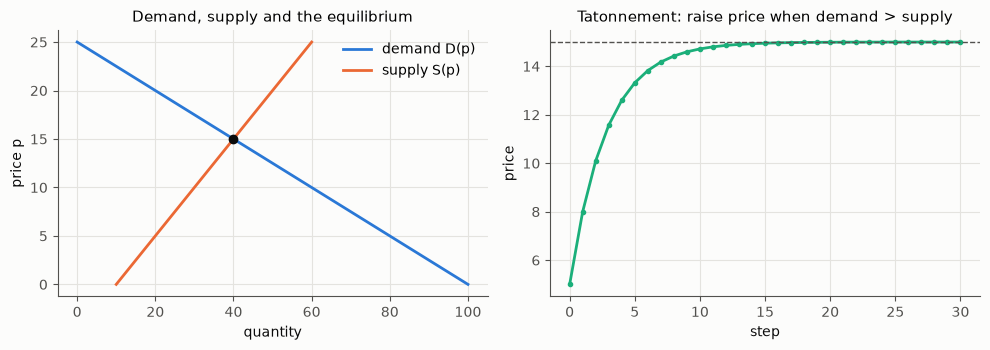

In [3]:
from scipy.optimize import minimize

D = lambda p: 100 - 4 * p          # 需要: 値段が上がると減る
S = lambda p: 10 + 2 * p           # 供給: 値段が上がると増える
p_star = 90 / 6                    # D = S を手で解くと p* = 15

# 模索過程
path = [5.0]
for t in range(30):
    path.append(path[-1] + 0.05 * (D(path[-1]) - S(path[-1])))

# (需要 − 供給)² の最小化
res = minimize(lambda x: (D(x[0]) - S(x[0])) ** 2, [5.0], method='Nelder-Mead')
print(f'手で解いた均衡価格 {p_star:.4f} / 模索過程の 30 回目 {path[-1]:.4f} / 最小化の答え {res.x[0]:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
p = np.linspace(0, 25, 100)
ax[0].plot(D(p), p, color=PAL[0], label='demand D(p)')
ax[0].plot(S(p), p, color=PAL[1], label='supply S(p)')
ax[0].scatter([D(p_star)], [p_star], color=INK, zorder=5)
ax[0].set(xlabel='quantity', ylabel='price p', title='Demand, supply and the equilibrium')
ax[0].legend()
ax[1].plot(path, marker='o', ms=3, color=PAL[2])
ax[1].axhline(p_star, color=INK2, ls='--', lw=1)
ax[1].set(xlabel='step', ylabel='price', title='Tatonnement: raise price when demand > supply')
plt.tight_layout(); plt.show()

### 1.3 市場が二つ以上あるとき: 予算がつなぐ

市場が二つ以上あると、話が変わる。パンの値段が上がると、パンに使うお金が増え、ほかの物に使えるお金が減る。市場どうしは、**予算**(使えるお金には限りがあること)でつながっている。

ここから大事な性質が二つ出てくる。

- **ワルラス法則**: 全員が予算どおりにお金を使うなら、全市場の「(需要 − 供給) × 価格」を足すと 0 になる。だから、市場が $n$ 個あるとき、独立な条件は $n - 1$ 本しかない。
- **価格の水準は決まらない**: 全部の価格と所得を 2 倍にしても、誰の行動も変わらない。決まるのは、価格どうしの比(相対価格)だけである。どれか一つの価格を 1 に決めて(これを価値尺度財、ニュメレールという)、残りを決める。

逆に言うと、予算の釣り合いを入れないまま価格を最適化すると、価格の水準や、誰がどれだけ受け取るかが宙に浮く。このことは第 8 章で、モデルの核心として戻ってくる。

### 1.4 利潤率・固定費・平均費用

企業の**利潤率**を、ここでは $(\text{売上} - \text{費用}) / \text{費用}$ と決める。売上 = 価格 × 個数、費用 = 固定費 + 一個あたりの費用 × 個数である。

**固定費**は、作る個数によらずかかる費用(工場の減価償却など)である。固定費があると、たくさん作るほど一個あたりの費用(**平均費用**)が下がる。

元のモデルの作者は、ここで面白いことに気づいた。利潤率 $\beta$ を決めたとき、それを実現できる個数 $n$ と価格 $P$ の関係を解くと、こうなる($K$ は固定費、$c$ は一個あたりの費用)。

$$
\beta = \frac{-K + (P - c)\,n}{K + c\,n}
\quad\Longleftrightarrow\quad
n = \frac{(1+\beta)K}{P - (1+\beta)c}.
$$

$P$ が大きいほど $n$ は**小さく**なる。教科書の供給曲線(値段が上がると供給が増える)と逆向きである。一社の固定費のある生産では、「値段が高ければ少なく作っても同じ利潤率が出る」からだ。

作者はここから、「供給曲線を使うのはやめ、需要に合わせて作る。利潤率は結果として決まり、その大きさをスコアに入れる」という方針を取った。この方針が、あとで見るとおり、モデルの性格を決めることになる。

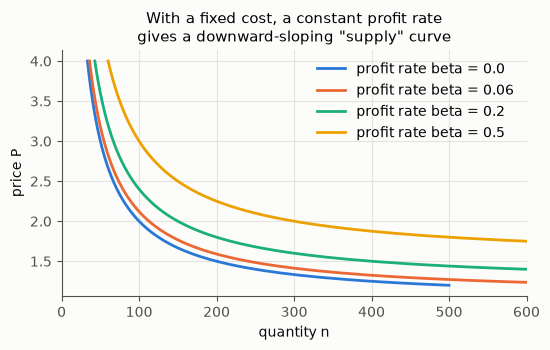

In [4]:
K, c = 100.0, 1.0
P = np.linspace(1.2, 4, 200)
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for i, beta in enumerate((0.0, 0.06, 0.2, 0.5)):
    n = (1 + beta) * K / (P - (1 + beta) * c)
    ok = P > (1 + beta) * c * 1.02
    ax.plot(n[ok], P[ok], color=PAL[i], label=f'profit rate beta = {beta}')
ax.set(xlim=(0, 600), xlabel='quantity n', ylabel='price P',
       title='With a fixed cost, a constant profit rate\ngives a downward-sloping "supply" curve')
ax.legend(); plt.tight_layout(); plt.show()

### 1.5 部門収支: 誰かの黒字は誰かの赤字

経済を、いくつかの**部門**(労働者・資本家・企業・政府など)に分けて、お金の出入りを考える。

ある期に、ある部門が収入より支出が少なければ、その差だけ金融資産(貯金など)が増える(**黒字**)。逆なら減る(**赤字**)。お金の支払いには、必ず払う側と受け取る側がいる。だから、**全部門の黒字と赤字を足すと 0 になる**。誰かの黒字は、必ず誰かの赤字である。

これは、モデルの会計が正しいかを確かめる道具になる。元のモデルには「社会的負債」という、誰にも帰属しない負債の勘定がある。もし会計が正しければ、

$$
\text{民間(労働者と資本家)の純金融資産の増分} = \text{社会的負債の増分}
$$

が、毎期、ぴったり成り立つはずである。第 7 章でこれを検算する。

### 1.6 最適化の道具: 局所的な探索と大域的な探索

最適化の関数は、与えた関数 $f(x)$ の値(**スコア**)が小さくなる $x$ を探す。元のモデルが使ったのは **Nelder–Mead 法**である。

- Nelder–Mead 法は、出発点のまわりに小さな図形(単体)を置き、スコアの低い方へ転がしていく。微分を使わないので、なめらかでない関数にも使える。
- ただし、**出発点に近い谷(局所的な最小点)**にしか行けない。関数に谷がいくつもあるとき、本当に一番低い谷(大域的な最小点)に行けるとは限らない。
- 大域的な最小点を探すには、**差分進化**や **dual annealing**(焼きなまし法の一種)のような、広く探す方法を使う。そのぶん計算はずっと重い。

谷が二つある関数で、違いを見ておこう。この違いは、第 6 章で決定的な役割を果たす。

Nelder–Mead を x =   0.5 から: x =  1.899, f =   7.852
Nelder–Mead を x =  -0.5 から: x = -2.088, f =  -4.135
Nelder–Mead を x =   2.8 から: x =  1.899, f =   7.852
差分進化(大域的):        x = -2.088, f =  -4.135


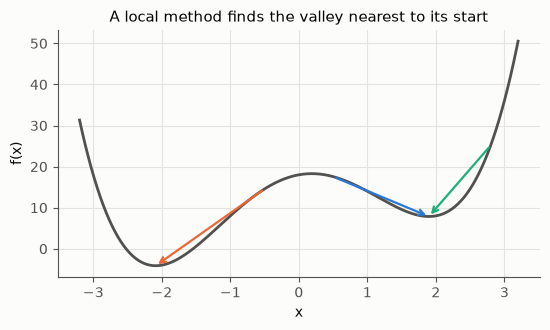

In [5]:
from scipy.optimize import differential_evolution

f = lambda x: (x[0] ** 2 - 4) ** 2 + 3 * x[0] + 2       # x ≈ -2 と x ≈ 2 に谷。左の谷のほうが低い
xs = np.linspace(-3.2, 3.2, 300)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(xs, [f([v]) for v in xs], color=INK2)
for i, x0 in enumerate((0.5, -0.5, 2.8)):
    r = minimize(f, [x0], method='Nelder-Mead')
    ax.annotate('', xy=(r.x[0], r.fun), xytext=(x0, f([x0])), arrowprops=dict(arrowstyle='->', color=PAL[i], lw=1.6))
    print(f'Nelder–Mead を x = {x0:5.1f} から: x = {r.x[0]:6.3f}, f = {r.fun:7.3f}')
r = differential_evolution(f, [(-3.2, 3.2)], seed=0)
print(f'差分進化(大域的):        x = {r.x[0]:6.3f}, f = {r.fun:7.3f}')
ax.set(xlabel='x', ylabel='f(x)', title='A local method finds the valley nearest to its start')
plt.tight_layout(); plt.show()

### 1.7 Lean: 名目の水準は決まらない

1.3 節で、市場が二つ以上あると予算がつなぐこと、そして価格の水準そのものは、相対価格の条件だけでは決まらないことを見た。価格の条件「価格 = (1 + 値上げ幅) × (賃金 × 労働の係数 + 原料の価格 × 原料の係数)」は、賃金とすべての価格を同じ k 倍しても成り立つ(一次の同次)。Lean で確かめておく。

In [6]:
%%writefile -a micro_economy.lean
/-! ## 第 1 章 名目の水準は、価格の条件の中では決まらない

価格の条件「価格 = (1 + 値上げ幅) × (賃金 × 労働の係数 + 原料の価格 × 原料の係数)」は、
賃金とすべての価格を同じ k 倍しても成り立つ(一次の同次)。だから、条件だけでは名目の水準は決まらない。 -/
theorem price_condition_homogeneous {p m W γ q α k : ℝ} (h : p = (1 + m) * (W * γ + q * α)) :
    k * p = (1 + m) * ((k * W) * γ + (k * q) * α) := by
  rw [h]; ring

Appending to micro_economy.lean


## 第 2 章 元のモデルを一から組み立てる

ここからは、元のモデル(`micro_economy_*.py`)を、部品ごとに組み立てていく。式は、コードと同じものを書く(作者の記事の説明とコードが食い違うところは、コードに従う)。版は四つ扱う。

| 版 | ファイル | 時期 | 特徴 |
|---|---|---|---|
| v1 | micro_economy_1.py | 2018-03 | 基本のモデル。スコアは「労働の需給のずれ² − 利益の総和」 |
| v2 | micro_economy_2.py | 2018-03 | v1 の「チューンアップ」版。罰の重みと、損失への罰を変えた |
| v5 | micro_economy_5.py | 2019-05 | 「log 戦略」。利益率に log に似た関数をかける |
| v7 | micro_economy_7.py | 2020-02 | 「大改良」。tanh で項をそろえ、標準利益率も変数にする |

規則(需要・生産・参入など)は、v1・v2・v5 でほぼ同じで、v7 で少し変わる。違いが大きいのはスコアである。

### 2.1 登場するもの

- **財**: 必需品 N、贅沢品 L、原料 I の三つ。どれも、原料と労働から作られる。原料は、原料を作るのにも要る。
- **人**: 労働者 1000 人と資本家 5 人。全員が、毎期、必需品を買う。貯蓄に余裕があれば、贅沢品も一個買う。
  - 労働者は、働けば賃金をもらう。働かない者(失業者)の必需品代は、「社会的負債」から出る(生活保護)。
  - 資本家は、企業を作る(参入する)。企業の利益で、企業を作ったときの負債を返す。
- **企業**: 分野(N, L, I)ごとに何社かある。各社は次の性質を持つ。
  - 一製品あたり労働量 $\gamma$、一製品あたり原料 $\alpha$
  - 優位性 $A$(生産の分担を決める重み)と、その減衰 $\delta$
  - 固定資産(原料で作る。10 期で償却され、企業はそこで退出する)
- **価格**: 賃金 $W$、必需品 $P_N$、贅沢品 $P_L$、原料 $P_I$ の四つ(v7 では、さらに標準利益率 $s$)。**これが最適化の変数**である。

### 2.2 一期の流れ

価格のベクトル $x = (W, P_N, P_L, P_I)$ を与えると、次の順に計算が進み、最後にスコアが一つ出る。最適化の関数は、このスコアが小さくなる $x$ を探す。

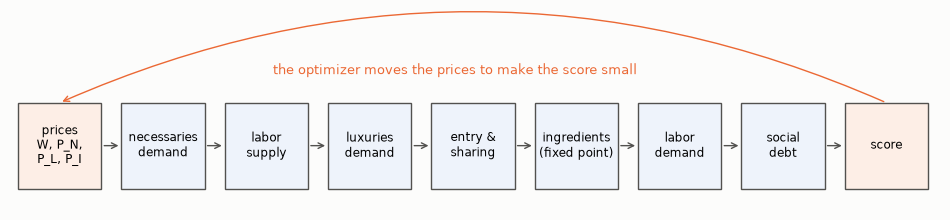

In [7]:
fig, ax = plt.subplots(figsize=(12, 2.6)); ax.axis('off')
steps = ['prices\nW, P_N,\nP_L, P_I', 'necessaries\ndemand', 'labor\nsupply', 'luxuries\ndemand', 'entry &\nsharing',
         'ingredients\n(fixed point)', 'labor\ndemand', 'social\ndebt', 'score']
for i, s in enumerate(steps):
    xx = i * 1.3
    ax.add_patch(plt.Rectangle((xx, 0.25), 1.05, 0.6, fc='#eef3fb' if i not in (0, 8) else '#fdeee6', ec=INK2))
    ax.text(xx + 0.525, 0.55, s, ha='center', va='center', fontsize=8.5)
    if i < len(steps) - 1:
        ax.annotate('', xy=(xx + 1.3, 0.55), xytext=(xx + 1.05, 0.55), arrowprops=dict(arrowstyle='->', color=INK2))
ax.annotate('', xy=(0.525, 0.85), xytext=(8 * 1.3 + 0.525, 0.85),
            arrowprops=dict(arrowstyle='->', color=PAL[1], connectionstyle='arc3,rad=0.22'))
ax.text(5.5, 1.05, 'the optimizer moves the prices to make the score small', ha='center', color=PAL[1], fontsize=9)
ax.set(xlim=(-0.1, 11.6), ylim=(0.1, 1.5)); plt.show()

以下、前の期の値には $'$ をつける($W'$ は前の期の賃金)。人数は $n_\text{pop} = 1005$ である。

### 2.3 必需品の需要

一人あたりの必需品の需要 $d$ は、前の期の需要 $d'$ と、価格の変化率から決まる。

$$
d = \max\!\left(1,\ \left(1 + \varepsilon\,\frac{P_N - P_N'}{P_N'}\right) d'\right),\qquad \varepsilon = -0.6 .
$$

$\varepsilon$ は**価格弾力性**(価格が 1% 上がると、需要が何 % 変わるか)。必需品なので、需要は価格にあまり反応しない($|\varepsilon| < 1$)。また、一人 1 単位より下には減らない。全体の需要は $d \cdot n_\text{pop}$ である。

この式は、**前の期からの変化**で需要を決めていることに注意しておく。前の期の需要を基準にするので、「長い目で見た需要曲線」がない。

### 2.4 労働の供給

まず、**新規貯蓄** $s = W - P_N d$(賃金から必需品代を引いた余り)を計算する。$s \le 0$ なら、誰も働かない(v2 では $s \le W/3$ なら)。そうでなければ、

$$
q = 0.5\,\frac{s - s'}{s'} + 0.5\,\frac{P_N - P_N'}{P_N'},\qquad
r = \frac{\arctan(2q)}{\pi}\ \ (-0.5 < r < 0.5).
$$

前の期に働いた人数を $n_w$、働かなかった人数を $n_u$ として、

- $n_u > n_w$ のとき: 働く人数 $S = n_w + \lceil r\,n_w \rceil$
- そうでないとき: $S = 1000 - (n_u - \lfloor r\,n_u \rfloor)$

$\arctan$ を使うのは、反応に上限と下限をつけるためである(一期で人数が ±50% より大きく動かない)。$S$ は整数なので、価格をなめらかに動かしても、$S$ は**階段状**に変わる。

### 2.5 贅沢品の需要

基準額 $b = \max(3s, 0)$ を決める。ある人の使えるお金を $a$(貯蓄。働く人と資本家は、今期の新規貯蓄 $s$ を足す)として、

$$
a \ge b \quad\text{かつ}\quad \frac{a - b}{3} + b \ \ge\ P_L
$$

なら、その人は贅沢品を一個買う。買う人の数が、贅沢品の需要である。

基準額が $3s$ なので、収入(新規貯蓄)が増えると基準も上がる。全員の貯蓄が基準を下回ると、贅沢品の需要は**価格によらず 0** になる。

### 2.6 生産の分担と参入

**分担**: 分野の需要を、その分野の企業で分ける。企業 $i$ が分担に加わるのは、一個あたりの粗利が正のとき、つまり $P - W\gamma_i - P_I\alpha_i > 0$ のときである($P$ はその分野の価格)。加わった企業の重みを

$$
w_i = A_i\,\gamma_i^{-\Delta}\ \ (\text{v7 では さらに } \alpha_i^{-\Theta}),\qquad \Delta = \frac{W - W'}{W'}\ \ (\text{v7 では } \tanh \text{ でくくる})
$$

とし、需要を $w_i$ の比で分ける。賃金が上がると、一製品あたり労働量 $\gamma$ の小さい(機械化の進んだ)企業の取り分が増える。どの企業も粗利が正でないときは、全社が($A_i\gamma_i^{-\Delta}$ の比で)赤字を分担する。

**参入**: 各分野で、毎期、資本家を一人ずつくじ引きの順に試す。負債のある資本家は参入できない。試しに作った新企業の性質は、前に参入した企業から、資本家の戦略 $(r_1, r_2)$ で決まる。

- 優位性 $A = 2 + 2r_1$、一製品あたり労働量 $\gamma = (0.95 + 0.04\,r_1)\,\gamma_\text{前}$
- 減衰 $\delta = 0.25^{0.1} + (0.5^{0.1} - 0.25^{0.1})\,r_2$、一製品あたり原料 $\alpha = (0.98 + 0.2\,r_2)\,\alpha_\text{前}$(原料の分野は 0.9 が上限)
- 固定資産に要る原料は、前の企業の 1.05 倍

つまり、優位性を上げると労働量の削減は小さく、優位性を長持ちさせると原料が増える。資本家 5 人の戦略は、一人がランダム、残り四人は $(r_1, r_2) = (0,0), (0,1), (1,0), (1,1)$ の決め打ちである。新企業の利潤率(今期の値と、直近 2 期を合わせた 3 期平均の、低いほう)が 6% 以上なら参入する。その分野の企業が 0 社になりそうなときは、最後の資本家が必ず参入する。

### 2.7 原料の不動点

原料の需要は、必需品と贅沢品の生産に要る原料と、新企業の固定資産に要る原料の和 $d_0$ である。ところが、原料を作るにも原料が要る。原料の分野の総生産を $u$、企業 $i$ の分担の比を $\sigma_i$ とすると、

$$
u = d_0 + \sum_i \sigma_i\,\alpha_i\,u
\quad\Longrightarrow\quad
u = \frac{d_0}{1 - \sum_i \sigma_i \alpha_i}.
$$

元のコードは、これを一変数の最適化で解いている。分母が正であるには、$\alpha$ の平均が 1 より小さくなければならない。作者が原料の分野の $\alpha$ に 0.9 の上限をつけたのは、このためである(第 7 章で、これがレオンチェフの投入産出分析の条件に当たることを見る)。

### 2.8 労働の需要と社会的負債

**労働の需要** $D$ は、全企業の「生産量 × 一製品あたり労働量」の和である。

**社会的負債**は、誰にも帰属しない負債の勘定である。次のものが付けられる。

- 労働の需要が供給より多い($D > S$)とき、働く人は残業をしたとみなし、残業代(賃金の 2 倍)を社会的負債から出す。少ないときは、余った「働く人」の賃金を社会的負債から出す。
- 働かない人の必需品代(生活保護)。
- 資本家の利益と負債の付け替え(資本家の「賃金」と固定資産の償却を社会的負債に付け、利益で負債を返し、余った利益は社会的負債を減らす)。

細かい点は、第 7 章で検算するときに詳しく見る。

### 2.9 スコア

版によって、スコアが大きく違う。$D - S$ は労働の需給のずれ、$\pi_k$ は企業 $k$ の利益(額)、$\rho_k$ は利潤率である。

| 版 | スコア(小さいほど良い) |
|---|---|
| v1 | $(D - S)^2 - \sum_k \pi_k$ |
| v2 | $3(D - S)^2 - \sum_{\text{分野}} g(\Pi_j / n_j)$。$\Pi_j$ は分野の利益の和、$n_j$ は企業数、$g(y) = 10y\ (y<0),\ y\ (y \ge 0)$ |
| v5 | $0.01(D - S)^2 - \operatorname{mean}_{\text{分野}} T(\max_k \rho_k)$。$T$ は log に似た関数(hybrid など) |

v7 のスコアは長いので、表の外に書く。$\mathrm{SD}$ は今期の社会的負債の増分、$\mathrm{SD}'$ は前期の値、$s$ は標準利益率(v7 で加わった変数)である。

$$
\begin{aligned}
\text{v7 のスコア} =\ & \tanh\!\left(\frac{1000\,(\mathrm{SD} - \mathrm{SD}')}{\max(1000,\ |\mathrm{SD}'|)}\right)
 + \tanh\!\big(5{\times}10^{-5}\,(D-S)^2\big)
 + \tanh\!\Big(10\ \operatorname{var}_{\text{分野}}\ \max_k \rho_k\Big) \\
 & - \sum_{\text{分野}} c(n_j)
 + \tanh\!\big(0.01\,(s - 0.06)^2\big)
 + 100 \cdot [\text{働く人が 0}] .
\end{aligned}
$$

$c(n)$ は、企業数 $n$ が 5 社のとき 1 になり、5 社から離れるほど小さくなる関数(自由度 7 のカイ二乗分布の密度を、5 での値で割ったもの)である。$[\cdots]$ は、中の条件が成り立てば 1、そうでなければ 0。

v1 は、利益を最大にし、労働の需給を合わせる。v2 は、損失を 10 倍に罰し、分野ごとの企業平均にした。v5 は、利益の額ではなく利潤率を、変換 $T$ をかけて足す。v7 は、全部の項を tanh で $[-1, 1]$ くらいに収め、企業数が 5 社前後になるように罰を足す。

### 2.10 一期を進める

最適化で価格 $x$ が決まったら、その価格で次のように状態を進める。

- 新企業を加える。
- 貯蓄を更新する。働く人は賃金(残業があれば割増)を受け取り、必需品と贅沢品(買うなら)を払う。働かない人は贅沢品(買うなら)だけを払う。
- 資本家の負債を、利益で返す。
- 企業の固定資産の残りの寿命を 1 減らし、尽きた企業は退出する。優位性は $\delta$ 倍に減衰する。
- 労働者を並べ替える(働いた人を前に、順番はくじ引き)。

最適化の出発点は、**前の期の価格**である。この一見何気ない決まりが、第 6 章で鍵になる。

初期値は、価格 $(W, P_N, P_L, P_I) = (30, 10, 15, 15)$、各人の貯蓄は平均 10 の指数分布、失業者 300 人、各分野に 1 社ずつ(必需品 $\gamma = 0.1, \alpha = 0.3$、贅沢品 $0.3, 0.5$、原料 $0.3, 0.3$)である。

## 第 3 章 書き直しと、元のコードとの一致の確認

### 3.1 元のコードを取ってくる

元のコードを、GitHub の決まった版から取ってくる道具を書く。`%%writefile` は、セルの中身をファイルに書き出す Jupyter の命令である。モジュールとしてファイルにしておくと、並列計算の子プロセスからも読める。

In [8]:
%%writefile orig_tools.py
"""orig_tools.py -- 元のコード(JRF-2018/micro_economy)を取ってきて、そのまま走らせる道具。

- 取ってくるのは commit 54e48f6(2020-04-12)の版。sha256 で中身が同じことを確かめる。
- 走らせるとき、print の出力は捨てる。中身は変えない。
  変えたいときは patches に(元の文字列, 新しい文字列)を渡す。差分はそのまま見せられる。
"""
import sys, io, os, random, hashlib, contextlib, urllib.request, importlib.util
import numpy as np

COMMIT = '54e48f649721bd1619b0d05296706ce0414dc190'
URL = f'https://raw.githubusercontent.com/JRF-2018/micro_economy/{COMMIT}/'
SHA256 = {
    'micro_economy_1.py': '8db99ba2578f72da56b3b7815790e4e1b18f5e5a4eeab9e997464038ad644f84',
    'micro_economy_2.py': '0b8569f6aaec78324a91d6a9b3bf4c2f166bda45e498fdcac410595c5b88a66d',
    'micro_economy_5.py': '0e690055976fb9d7b0a4c020ce77e384546ee48ba464a35f992febe7c19c3f0c',
    'micro_economy_7.py': '0380dafa41137ba54376dc2e91098c5749e105442b10389b255f3d03b57f8ec7',
}
CACHE = 'orig_cache'
VERSION_FILE = {'v1': 'micro_economy_1.py', 'v2': 'micro_economy_2.py',
                'v5': 'micro_economy_5.py', 'v7': 'micro_economy_7.py'}


def fetch(name):
    """CACHE になければ GitHub から取ってくる。sha256 が合わなければ止める。"""
    os.makedirs(CACHE, exist_ok=True)
    path = os.path.join(CACHE, name)
    if not os.path.exists(path):
        with urllib.request.urlopen(URL + name, timeout=60) as r:
            data = r.read()
        with open(path, 'wb') as f:
            f.write(data)
    data = open(path, 'rb').read()
    h = hashlib.sha256(data).hexdigest()
    if h != SHA256[name]:
        raise ValueError(f'{name}: sha256 が違う ({h})')
    return data.decode('utf-8')

Overwriting orig_tools.py


取ってきたコードを、print を捨てて走らせる道具。元の `Economy` は初期化のたびに乱数の種を変えるので(`random.seed()`)、作ったあとで種を固定し直してから初期化する。元のコードの中身は変えない。

In [9]:
%%writefile -a orig_tools.py
def load(version, patches=(), argv=()):
    """元のコードをモジュールとして読み込む。argv は元の argparse に渡すオプション(v5, v7)。"""
    name = VERSION_FILE[version]
    src = fetch(name)
    for a, b in patches:
        assert src.count(a) >= 1, a
        src = src.replace(a, b)
    sys.argv = [name] + list(argv)
    m = importlib.util.module_from_spec(importlib.util.spec_from_loader(name[:-3], loader=None))
    exec(compile(src, name, 'exec'), m.__dict__)
    return m


def new_economy(m, seed):
    """元の Economy を作り、seed を固定して初期化する(元の __init__ は random.seed() で毎回違う乱数にするため)。"""
    random.seed(seed)
    e = m.Economy()
    random.seed(seed)
    e.initialize_0()
    return e


def run_orig(version, seed, T, patches=(), argv=()):
    """元のコードを T 期回し、期ごとの価格・企業数・生産・労働を記録する。print は捨てる。"""
    m = load(version, patches, argv)
    e = new_economy(m, seed)
    last = {}
    calc = e._calcNextState
    def calc_rec(x):
        st = calc(x)
        last['st'] = st
        return st
    e._calcNextState = calc_rec          # 最後に計算した状態(= 選ばれた価格での状態)を覚えておくだけ
    log = []
    with contextlib.redirect_stdout(io.StringIO()):
        for t in range(T):
            try:
                e.step() if version != 'v7' else e.step(t + 1)
            except Exception as ex:
                log.append(dict(t=t, collapse=type(ex).__name__))
                break
            st, p = last['st'], e.prevPrice
            log.append(dict(t=t, W=p.wages, N=p.necessaries, L=p.luxuries, I=p.ingredients,
                            nN=len(e.necessariesCompanies), nL=len(e.luxuriesCompanies),
                            nI=len(e.ingredientsCompanies), score=st['score'],
                            supply=float(st['supplyOfLabors']), gap=st['demandOfLabors'] - st['supplyOfLabors'],
                            prodN=sum(st['productsOfNecessaries']), prodL=sum(st['productsOfLuxuries']),
                            prodI=sum(st['productsOfIngredients'])))
    return log

Appending to orig_tools.py


In [10]:
import importlib, orig_tools
importlib.reload(orig_tools)
for name in orig_tools.SHA256:
    src = orig_tools.fetch(name)
    print(f'{name}: {len(src.splitlines()):5d} 行, sha256 一致')

micro_economy_1.py:   886 行, sha256 一致
micro_economy_2.py:   885 行, sha256 一致
micro_economy_5.py:   903 行, sha256 一致
micro_economy_7.py:  1275 行, sha256 一致


試しに、元の v1 を 5 期だけ回してみる。

In [11]:
t0 = time.time()
log = orig_tools.run_orig('v1', seed=1, T=5)
print(f'元の v1、5 期: {time.time() - t0:.1f} 秒')
print(' 期      W      P_N     P_L     P_I   企業数 N/L/I  働く人  贅沢品の生産')
for r in log:
    print(f"{r['t'] + 1:3d} {r['W']:7.2f} {r['N']:7.2f} {r['L']:7.2f} {r['I']:7.2f}    {r['nN']:2d}/{r['nL']:2d}/{r['nI']:2d}     {r['supply']:5.0f}   {r['prodL']:6.0f}")

元の v1、5 期: 0.6 秒
 期      W      P_N     P_L     P_I   企業数 N/L/I  働く人  贅沢品の生産
  1   25.20    9.78   16.16   16.39     2/ 2/ 2       656      309
  2   24.63   10.11   13.18   21.03     3/ 2/ 3       642      356
  3   23.98   13.70    7.75   29.17     4/ 2/ 4       632      538
  4   23.16   13.06    6.57   35.81     4/ 2/ 5       608      462
  5   22.31   12.83    4.46   35.35     4/ 2/ 6       567      367


### 3.2 書き直し `me_ref.py`

調べるには、同じ計算を何千回もくり返す。そのために、元のコードと同じ計算をする書き直しを作る。方針は次のとおり。

- 版(v1, v2, v5, v7)は `Params(version=...)` で切り替える。
- **乱数の使い方は元と同じにする。** 同じ seed なら、同じくじ引きの結果になる。
- print はしない。贅沢品の需要は、1005 人をまとめて numpy で数える。
- 原料の不動点は、2.7 の閉じた式で解く(`poi='brent'` にすると、元と同じ一変数の最適化で解く)。
- 元のコードの会計の誤り(第 7 章)は、オプションで直せるようにする。既定は元のまま。
- 後の章で使うスコア(均衡の残差)や、技術の変化を止める切り替えも、オプションとして入れておく。既定は元のまま。

まず、パラメータと企業のデータ。

In [12]:
%%writefile me_ref.py
"""me_ref.py -- micro_economy_1/2/5/7.py(JRF, 2018-2020)の一期の計算を、読みやすく速く書き直したもの。

元のコードと同じ乱数の使い方をし、同じ seed・同じ最適化法なら同じ経路をたどる(test_me_ref.py で確かめる)。
違いは次のとおり。
  - print をしない。
  - 贅沢品の需要を numpy でまとめて数える。
  - 原料の自己投入の不動点を、閉じた式 u = d0 / (1 - Σ share_i α_i) で解く。
    poi='brent' にすると、元と同じ一変数最適化で解く(完全一致の確認用)。
  - 元のコードの会計の誤りを、オプションで直せる(fix_profit, fix_overtime)。既定は元のまま。
"""
import random
from dataclasses import dataclass, replace
import numpy as np
from scipy.optimize import minimize, minimize_scalar
from scipy.stats import chi2

SECTORS = ('N', 'L', 'I')       # 必需品・贅沢品・原料
N_LABORS, N_CAPITALISTS = 1000, 5


@dataclass
class Company:
    owner: int
    fa_ing: float       # 固定資産に要した原料の量
    fa_price: float     # 固定資産の価格(設立時の原料価格で評価)
    life: int
    rest: int
    A: float            # 優位性 superiority
    decay: float        # 優位性の減衰
    gamma: float        # 一製品あたり労働量
    alpha: float        # 一製品あたり原料


@dataclass
class Params:
    version: str = 'v1'          # 'v1', 'v2', 'v5', 'v7'(v5 は v1 の規則 + その3 の log 戦略のスコア)
    fix_profit: bool = False     # 資本家の利益: 原料費の符号と、複数社所有の上書きを直す
    fix_overtime: bool = False   # 残業: 社会的負債の正味を w(D-S) にする
    poi: str = 'closed'          # 原料の不動点: 'closed' か 'brent'(元と同じ)
    # 共通の定数(元のコードの既定値)
    necessaries_elasticity: float = -0.6
    surplus_vs_necessaries_ratio: float = 0.5
    standard_profit_rate: float = 0.06
    wages_elastic_power: float = 1.0
    wages_elastic_power_2: float = 1.0
    ingredients_elastic_power: float = 1.0
    ingredients_elastic_power_2: float = 1.0
    ingredients_limit: float = 0.9
    init_lpp_mag: float = 1.0
    alpha_change: bool = True    # False にすると、新企業の一製品あたり原料を前の企業と同じにする
    gamma_progress: bool = True  # False にすると、新企業の一製品あたり労働量を前の企業と同じにする(機械の高度化なし)
    # v7 のスコアの係数(元の argparse の既定値)
    score_labor_mag: float = 0.00005
    score_mean_mag: float = 0.0
    score_variance_mag: float = 10.0
    score_variance_mag_2: float = 1.0
    score_transform: str = 'none'   # v7 の既定。v5 で使うときは 'hybrid' などを指定
    v5_labor_mag: float = 0.01
    score_mean: str = 'max'
    expected_companies: float = 5.0
    score_companies_mag: float = 1.0
    score_profit_rate_mag: float = 0.01
    score_social_debt_mag: float = 1000.0
    score_zero_worker_penalty: float = 100.0
    fix_standard_profit_rate: bool = False
    # スコアの種類: 'orig' は版ごとの元のスコア。'eq' は均衡の残差
    #   (労働需給のずれ/eq_labor_scale)² + Σ_分野 ((分野の利潤率 − r̄)/eq_rate_scale)²
    score_kind: str = 'orig'
    # 慣性の項(明示した戦術「前の期の価格に近い点を選ぶ」): inertia · Σ (log x − log x')²(v7 の標準利益率は差の二乗)
    inertia: float = 0.0
    smooth_labor: bool = False   # True にすると労働供給の切り上げ・切り捨てをやめる(階段をなくす)
    eq_target_rate: float = 0.06
    eq_labor_scale: float = 10.0
    eq_rate_scale: float = 0.05
    eq_sectors: tuple = ('N', 'L', 'I')   # 利潤率をそろえる分野(一つ減らすと、式が一本足りない設定になる)

Overwriting me_ref.py


v5・v7 の「log 戦略」の変換 $T$。

In [13]:
%%writefile -a me_ref.py
def _transform(name, x):
    if name == 'none': return x
    if name == 'log': return np.log(1 + x)
    if name == 'log1.1': return -1.1 * np.log(1.1) + 1.1 * np.log(x + 1.1)
    if name == 'exp':
        a = np.log(1 + 5)
        return -np.exp(-a * x) + 1
    h = {'hybrid': 0.1, 'hybrid0.2': 0.2, 'hybrid0.1': 0.1}[name]
    k = {'hybrid': 0.2, 'hybrid0.2': 0.4, 'hybrid0.1': 0.1}[name]
    return k * np.log(x + h) - k * np.log(h) if x >= 0 else -np.exp(-2 * x) + 1

Appending to me_ref.py


初期化。乱数を引く順番(資本家 5 人の貯蓄、労働者 1000 人の貯蓄、各分野の企業の持ち主と残りの寿命)を、元の `initialize_0` と同じにする。

In [14]:
%%writefile -a me_ref.py
class Economy:
    def __init__(self, params=None, seed=0):
        self.P = params or Params()
        self.rng = random.Random(seed)
        self._initialize()

    # ---- 初期化(元の initialize_0 と同じ乱数の順) ----
    def _initialize(self):
        P, rng = self.P, self.rng
        v7 = P.version == 'v7'
        self.prev_price = np.array([30.0, 10, 15, 15] + ([P.standard_profit_rate] if v7 else []))
        self.prev_dN = 2010.0
        s = 30 - 10 * 2010 / (N_LABORS + N_CAPITALISTS)
        self.cap_savings = np.array([rng.expovariate(1.0 / s) for _ in range(N_CAPITALISTS)])
        self.cap_debt = np.zeros(N_CAPITALISTS)
        self.lab_savings = np.array([rng.expovariate(1.0 / s) for _ in range(N_LABORS)])
        self.lab_working = np.arange(N_LABORS) < N_LABORS - 300
        self.companies, self.last = {}, {}
        for sec, g, a in (('N', 0.1, 0.3), ('L', 0.3, 0.5), ('I', 0.3, 0.3)):
            owner = rng.randint(0, 4); rest = rng.randint(0, 9)
            c = Company(owner, 5, 5 * 15.0, 10, rest, 0.3 * 0.9 ** (10 - rest), 0.9,
                        g * P.init_lpp_mag, a)
            self.companies[sec] = [c]; self.last[sec] = c
        r = P.standard_profit_rate
        self.hist = {sec: [r, r] for sec in SECTORS}
        self.prev_sd = 0.0
        self.cum_sd = 0.0
        self.rstate = rng.getstate()
        self.t = 0
        self.log = []

Appending to me_ref.py


企業の設立(2.6)。ランダムな戦略の資本家だけが乱数を二つ引く。

In [15]:
%%writefile -a me_ref.py
    # ---- 企業の設立(戦略: 0 はランダム、1〜4 は r1, r2 を 0/1 に決め打ち) ----
    def _make_company(self, owner, old, price, ig_limit):
        if owner == 0:
            r1 = self.rng.random(); r2 = self.rng.random()
        else:
            r1, r2 = [(0, 0), (0, 1), (1, 0), (1, 1)][owner - 1]
        fa_ing = old.fa_ing * 1.05
        alpha = (((1.18 - 0.98) * r2 + 0.98) if self.P.alpha_change else 1.0) * old.alpha
        if ig_limit is not None and alpha > ig_limit: alpha = ig_limit
        return Company(owner, fa_ing, fa_ing * price[3], 10, 10, (4 - 2) * r1 + 2,
                       ((0.5 ** 0.1) - (0.25 ** 0.1)) * r2 + (0.25 ** 0.1),
                       (((0.99 - 0.95) * r1 + 0.95) if self.P.gamma_progress else 1.0) * old.gamma, alpha)

Appending to me_ref.py


生産の分担(2.6)と、原料の不動点(2.7)。

In [16]:
%%writefile -a me_ref.py
    # ---- 生産の分担 ----
    def _shares(self, price, p, comps):
        P, w0, i0 = self.P, self.prev_price[0], self.prev_price[3]
        if P.version == 'v7':
            delta = P.wages_elastic_power_2 * np.tanh(P.wages_elastic_power * (price[0] - w0) / w0)
            theta = P.ingredients_elastic_power_2 * np.tanh(P.ingredients_elastic_power * (price[3] - i0) / i0)
        else:
            delta = P.wages_elastic_power * (price[0] - w0) / w0
            theta = 0.0
        s = [c.A * c.gamma ** (-delta) * c.alpha ** (-theta)
             if p - price[0] * c.gamma - price[3] * c.alpha > 0 else 0 for c in comps]
        tot = sum(s)
        if tot == 0:   # どの企業も赤字なら、全社で赤字を分担する
            s = [c.A * c.gamma ** (-delta) for c in comps]; tot = sum(s)
        return [x / tot for x in s]

    def _products(self, price, p, demand, comps):
        return [x * demand for x in self._shares(price, p, comps)]

    def _products_I(self, price, p, d0, comps):
        if self.P.poi == 'brent':
            maxI = max(c.alpha for c in comps)
            def score(k):
                if k < 0: return d0 ** 2
                u = k + d0
                q = self._products(price, p, u, comps)
                return (d0 + sum(qi * c.alpha for qi, c in zip(q, comps)) - u) ** 2
            res = minimize_scalar(score, bracket=(0, (maxI / (1 - maxI)) * d0), method='brent')
            return self._products(price, p, res.x + d0, comps)
        sh = self._shares(price, p, comps)
        u = d0 / (1 - sum(s * c.alpha for s, c in zip(sh, comps)))
        return [s * u for s in sh]

    @staticmethod
    def _profit_rate(c, p, price, n):
        cost = c.fa_price / c.life + (price[0] * c.gamma + price[3] * c.alpha) * n
        return (p * n - cost) / cost

Appending to me_ref.py


参入の判定。資本家のくじ引きの順は `random.sample` で引き、負債のある資本家を先に並べる(元の `sorted` と同じく、並べ替えは安定)。

In [17]:
%%writefile -a me_ref.py
    # ---- 参入の判定と生産量 ----
    def _entry(self, sec, price, demand, spr, ig_limit=None):
        comps, p = self.companies[sec], price[{'N': 1, 'L': 2, 'I': 3}[sec]]
        prod = self._products_I if sec == 'I' else self._products
        order = sorted(self.rng.sample(range(N_CAPITALISTS), N_CAPITALISTS),
                       key=lambda i: 0 if self.cap_debt[i] >= 0.1 else 1)
        newC = None
        for i, cp in enumerate(order):
            if self.cap_debt[cp] >= 0.1 and not (len(comps) == 0 and i == N_CAPITALISTS - 1):
                continue
            newC = self._make_company(cp, self.last[sec], price, ig_limit)
            trial = comps + [newC]
            d = demand + (newC.fa_ing if sec == 'I' else 0)
            q = prod(price, p, d, trial)
            pr = self._profit_rate(newC, p, price, q[-1])
            pr = min(pr, sum(self.hist[sec][-2:] + [pr]) / 3)
            if pr >= spr or (len(trial) <= 1 and i == N_CAPITALISTS - 1):
                return newC, q
            newC = None
        return None, prod(price, p, demand, comps)

Appending to me_ref.py


一期の計算の本体。価格 $x$ を受け取り、2.3〜2.9 を順に計算して、スコアと途中の量を返す。最初に、乱数の状態を期の初めの状態に戻す(元のコードも同じことをしている)。だから、同じ $x$ なら何度呼んでも同じ答えになる。

In [18]:
%%writefile -a me_ref.py
    # ---- 一期の計算(価格 x を与えると、需要・生産・スコアなどを返す) ----
    def calc(self, x):
        P = self.P
        x = np.asarray(x, dtype=float)
        v7 = P.version == 'v7'
        if np.any((x[:4] < 1) | (x[:4] > 1000)) or (v7 and not 0.0 <= x[4] <= 1.0):
            return {'score': float('inf')}
        self.rng.setstate(self.rstate)
        spr = (P.standard_profit_rate if (not v7 or P.fix_standard_profit_rate) else x[4])
        W, PN, PL, PI = x[:4]
        pW, pN = self.prev_price[0], self.prev_price[1]
        npop = N_LABORS + N_CAPITALISTS

        # 必需品の需要(一人あたり。前期からの価格変化と弾力性で決まる。下限 1)
        prevD = self.prev_dN / npop
        curD = max(1.0, (1 + (PN - pN) / pN * P.necessaries_elasticity) * prevD)
        dN = curD * npop

        # 労働供給
        curS = W - PN * curD                     # 新規貯蓄
        cliff = W / 3 if P.version == 'v2' else 0.0
        if curS <= cliff:
            S = 0
        else:
            prevS = pW - pN * prevD
            q = (curS - prevS) / prevS * P.surplus_vs_necessaries_ratio \
                + (PN - pN) / pN * (1 - P.surplus_vs_necessaries_ratio)
            r = 0.5 * 2 * np.arctan(2 * q) / np.pi
            working = int(self.lab_working.sum()); notw = N_LABORS - working
            ceil, floor = (np.ceil, np.floor) if not P.smooth_labor else ((lambda v: v), (lambda v: v))
            S = working + ceil(r * working) if notw > working \
                else N_LABORS - (notw - floor(r * notw))

        # 贅沢品の需要(貯蓄が基準額 3·新規貯蓄 を超えた分の 1/3 + 基準額 が価格以上なら一個買う)
        base = max(curS * 3.0, 0.0)
        sav = np.concatenate([self.lab_savings, self.cap_savings])
        earning = np.ones(npop, bool); earning[:N_LABORS] = np.arange(N_LABORS) < S
        avail = sav + np.where(earning, curS, 0.0)
        buys = (avail >= base) & ((avail - base) / 3 + base >= PL)
        dL = int(buys.sum())

        # 生産と参入(必需品 → 贅沢品 → 原料の順。乱数の順も元と同じ)
        newN, qN = self._entry('N', x, dN, spr)
        newL, qL = self._entry('L', x, dL, spr)
        compsN = self.companies['N'] + ([newN] if newN else [])
        compsL = self.companies['L'] + ([newL] if newL else [])
        d0 = sum(q * c.alpha for q, c in zip(qN, compsN)) + sum(q * c.alpha for q, c in zip(qL, compsL)) \
            + (newN.fa_ing if newN else 0) + (newL.fa_ing if newL else 0)
        newI, qI = self._entry('I', x, d0, spr, P.ingredients_limit)
        compsI = self.companies['I'] + ([newI] if newI else [])
        comps = {'N': compsN, 'L': compsL, 'I': compsI}
        qs = {'N': qN, 'L': qL, 'I': qI}
        D = sum(q * c.gamma for sec in SECTORS for q, c in zip(qs[sec], comps[sec]))

        # 社会的負債
        sd, debt, profit_c = self._social_debt(x, D, S, curD, comps, qs, {'N': newN, 'L': newL, 'I': newI})

        # スコア
        price_of = {'N': PN, 'L': PL, 'I': PI}
        parts = None
        sector_rate, sector_rev, sector_maxrate = {}, {}, {}
        for sec in SECTORS:   # 分野全体の利潤率 = (売上 − 費用) / 費用
            rev = sum(price_of[sec] * q for q, c in zip(qs[sec], comps[sec]))
            cost = sum(c.fa_price / c.life + (W * c.gamma + PI * c.alpha) * q for q, c in zip(qs[sec], comps[sec]))
            sector_rate[sec] = (rev - cost) / cost
            sector_rev[sec] = rev
            sector_maxrate[sec] = max(self._profit_rate(c, price_of[sec], x, q) for q, c in zip(qs[sec], comps[sec]))
        if P.score_kind == 'eq':
            score = ((D - S) / P.eq_labor_scale) ** 2 \
                + sum(((sector_rate[sec] - P.eq_target_rate) / P.eq_rate_scale) ** 2 for sec in P.eq_sectors)
        elif P.version == 'v5':
            score = P.v5_labor_mag * (D - S) ** 2
            prs = [[self._profit_rate(c, price_of[sec], x, q) for q, c in zip(qs[sec], comps[sec])]
                   for sec in SECTORS]
            if P.score_mean == 'max': score -= np.mean([_transform(P.score_transform, max(l)) for l in prs])
            elif P.score_mean == 'mean': score -= np.mean([_transform(P.score_transform, np.mean(l)) for l in prs])
            else: score -= np.mean([_transform(P.score_transform, v) for l in prs for v in l])
        elif P.version == 'v1':
            score = (D - S) ** 2
            for sec in SECTORS:
                score -= sum(-c.fa_price / c.life + (price_of[sec] - c.gamma * W - c.alpha * PI) * q
                             for q, c in zip(qs[sec], comps[sec]))
        elif P.version == 'v2':
            score = 3 * (D - S) ** 2
            for sec in SECTORS:
                r1 = sum(-c.fa_price / c.life + (price_of[sec] - c.gamma * W - c.alpha * PI) * q
                         for q, c in zip(qs[sec], comps[sec]))
                n = len(comps[sec])
                score -= 10 * r1 / n if r1 < 0 else r1 / n
        else:
            parts = {}
            parts['zero_worker'] = P.score_zero_worker_penalty if S == 0 else 0.0
            parts['social_debt'] = np.tanh(P.score_social_debt_mag * (sd - self.prev_sd)
                                           / (1000 if abs(self.prev_sd) < 1000 else abs(self.prev_sd)))
            parts['labor'] = np.tanh(P.score_labor_mag * (D - S) ** 2)
            prs = [[self._profit_rate(c, price_of[sec], x, q) for q, c in zip(qs[sec], comps[sec])]
                   for sec in SECTORS]
            if P.score_mean == 'max': r0 = [_transform(P.score_transform, max(l)) for l in prs]
            elif P.score_mean == 'mean': r0 = [_transform(P.score_transform, np.mean(l)) for l in prs]
            else: r0 = [_transform(P.score_transform, v) for l in prs for v in l]
            parts['mean'] = -np.tanh(P.score_mean_mag * np.mean(r0))
            parts['variance'] = P.score_variance_mag_2 * np.tanh(P.score_variance_mag * np.var(r0))
            df = P.expected_companies + 2
            parts['companies'] = -P.score_companies_mag * sum(chi2.pdf(len(comps[s]), df) / chi2.pdf(P.expected_companies, df)
                                                              for s in SECTORS)
            parts['profit_rate'] = np.tanh(P.score_profit_rate_mag * (x[4] - P.standard_profit_rate) ** 2)
            score = 0.0
            for k in ('zero_worker', 'social_debt', 'labor', 'mean', 'variance', 'companies', 'profit_rate'):
                score += parts[k]
        if P.inertia > 0:
            d = np.log(x[:4] / self.prev_price[:4])
            score += P.inertia * (float(d @ d) + (float((x[4] - self.prev_price[4]) ** 2) if v7 else 0.0))
        return dict(score=float(score), sector_rate=sector_rate, sector_rev=sector_rev, sector_maxrate=sector_maxrate, x=x, dN=dN, curD=curD, curS=curS, S=float(S), D=D, dL=dL,
                    buys=buys, new={'N': newN, 'L': newL, 'I': newI}, comps=comps, qs=qs,
                    sd=sd, debt=debt, profit_c=profit_c, parts=parts)

Appending to me_ref.py


社会的負債と資本家の負債の計算。元のコードと同じ順で積む。`fix_profit`・`fix_overtime` は第 7 章で使う。

In [19]:
%%writefile -a me_ref.py
    def _social_debt(self, x, D, S, curD, comps, qs, new):
        """元の _calcNextState / step と同じ順で社会的負債を積む。資本家の負債の更新後の値も返す。"""
        P = self.P
        W, PN, PI = x[0], x[1], x[3]
        sd = 0.0
        if D > S: sd += (1 if P.fix_overtime else 2) * W * (D - S)
        else: sd += (S - D) * W
        sd += PN * curD * (N_LABORS - S)            # 失業者の生活保護
        if P.version == 'v2':
            sd += N_CAPITALISTS * W                 # v2 だけ: 資本家の「賃金」も社会的負債に
        debt = self.cap_debt.copy()
        for c in new.values():
            if c is not None: debt[c.owner] += c.fa_price
        profit = np.zeros(N_CAPITALISTS); debtable = np.zeros(N_CAPITALISTS)
        price_of = {'N': x[1], 'L': x[2], 'I': x[3]}
        for sec in SECTORS:
            for q, c in zip(qs[sec], comps[sec]):
                debtable[c.owner] += c.fa_price / c.life
                if P.fix_profit:
                    profit[c.owner] += q * (price_of[sec] - W * c.gamma - PI * c.alpha)
                else:   # 元のまま: 原料費の符号が逆、複数社は上書き
                    profit[c.owner] = q * (price_of[sec] - W * c.gamma + PI * c.alpha)
        for i in range(N_CAPITALISTS):
            profit[i] -= W; debtable[i] += W
            sd += debtable[i]; debt[i] -= debtable[i]
            if debt[i] < 0: sd += debt[i]; debt[i] = 0
            if profit[i] < 0: sd += -profit[i]
            else:
                debt[i] -= profit[i]
                if debt[i] < 0: sd += debt[i]; debt[i] = 0
        return sd, debt, profit

Appending to me_ref.py


一期を進める(2.10)。最適化の出発点は、前の期の価格。最後の `calc` の乱数の続きで労働者を並べ替える点も、元と同じにしてある(これがずれると、次の期の乱数がずれる)。

In [20]:
%%writefile -a me_ref.py
    # ---- 一期を進める ----
    def initial_guess(self):
        if self.P.version != 'v7':
            return self.prev_price.copy()
        last = [self.hist[s][-1] for s in SECTORS]
        p = self.P.standard_profit_rate if self.P.fix_standard_profit_rate else np.clip(np.mean(last), 0.0, 1.0)
        return np.r_[self.prev_price[:4], p]

    def step(self, optimizer=None):
        """optimizer(f, x0) -> x。None なら元と同じ Nelder-Mead(前期の価格から)。"""
        f = lambda x: self.calc(x)['score']
        x0 = self.initial_guess()
        if optimizer is None:
            res = minimize(f, x0, method='Nelder-Mead'); x = res.x; ok = bool(res.success)
        else:
            x = optimizer(f, x0); ok = True
        st = self.calc(x)                   # 最後の calc の乱数状態から、労働者の並べ替えに進む(元と同じ)
        if not np.isfinite(st['score']):
            raise ValueError('Economy Collapsed.')
        self._apply(st)
        self.log.append(dict(t=self.t, W=x[0], N=x[1], L=x[2], I=x[3], S_rate=(x[4] if len(x) > 4 else np.nan),
                             score=st['score'], ok=ok, supply=st['S'], gap=st['D'] - st['S'],
                             prodN=sum(st['qs']['N']), prodL=sum(st['qs']['L']), prodI=sum(st['qs']['I']),
                             nN=len(self.companies['N']), nL=len(self.companies['L']), nI=len(self.companies['I']),
                             **{f'rate_{s}': st['sector_rate'][s] for s in SECTORS},
                             **{f'maxrate_{s}': st['sector_maxrate'][s] for s in SECTORS},
                             **{f'rev_{s}': st['sector_rev'][s] for s in SECTORS},
                             sd=st['sd'], net_private=self.lab_savings.sum() + self.cap_savings.sum() - self.cap_debt.sum()))
        return st

    def _apply(self, st):
        x, P = st['x'], self.P
        W, PN, PL = x[0], x[1], x[2]
        S, D, curD, curS = st['S'], st['D'], st['curD'], st['curS']
        for sec in SECTORS:
            c = st['new'][sec]
            if c is not None:
                self.companies[sec] = self.companies[sec] + [c]; self.last[sec] = c
        # 貯蓄
        if D > S and S == 0:
            raise ZeroDivisionError('no labor supply (元のコードでも 0 除算で止まる)')
        true_w = 2 * W * (D - S) / S + W if D > S else W
        buys = st['buys']
        idx = np.arange(N_LABORS); work = idx < S
        lb = buys[:N_LABORS]
        self.lab_savings = self.lab_savings + np.where(work, true_w - PN * curD, 0.0) - np.where(lb, PL, 0.0)
        self.lab_working = work
        self.cap_savings = self.cap_savings + W - PN * curD - np.where(buys[N_LABORS:], PL, 0.0)
        # 利潤率の履歴(各分野の最大値)
        price_of = {'N': PN, 'L': PL, 'I': x[3]}
        for sec in SECTORS:
            prs = [self._profit_rate(c, price_of[sec], x, q) for q, c in zip(st['qs'][sec], self.companies[sec])]
            self.hist[sec] = self.hist[sec] + [max(prs) if prs else None]
        # 資本家の負債(calc で計算したもの)
        self.cap_debt = st['debt']
        # 固定資産の寿命と優位性の減衰
        for sec in SECTORS:
            keep = []
            for c in self.companies[sec]:
                c = replace(c, rest=c.rest - 1)
                if c.rest >= 0:
                    keep.append(replace(c, A=c.A * c.decay))
            self.companies[sec] = keep
        # 労働者を並べ替える(働いている者を前に。乱数は calc の続き)
        perm = self.rng.sample(range(N_LABORS), N_LABORS)
        w = [i for i in perm if self.lab_working[i]]; nw = [i for i in perm if not self.lab_working[i]]
        order = np.array(w + nw, dtype=int)
        self.lab_savings = self.lab_savings[order]; self.lab_working = self.lab_working[order]
        self.prev_price = x.copy()
        self.prev_dN = st['dN']
        self.prev_sd = st['sd']
        self.cum_sd += st['sd']
        self.rstate = self.rng.getstate()
        self.t += 1

Appending to me_ref.py


In [21]:
%%writefile -a me_ref.py
def run(params, seed, T, optimizer=None):
    e = Economy(params, seed)
    for _ in range(T):
        try:
            e.step(optimizer)
        except (ValueError, TypeError, ZeroDivisionError) as ex:
            e.log.append(dict(t=e.t, collapse=str(ex)[:60])); break
    return e

Appending to me_ref.py


### 3.3 一致試験

書き直しが元のコードと同じ計算をしているかを確かめる。次の二つを試す。

1. **同じ状態での一期の計算**: 両方を同じ seed で初期化し、ランダムな価格 30 点について、スコア・労働の供給・労働の需要を比べる。
2. **一期を進めた結果**: 両方を元のやり方(前の期の価格から Nelder–Mead)で一期進め、選ばれた価格を比べる。

これを 5 期くり返す。版は v1・v2・v7 を seed 1・2 で、v5 を三つの変換(hybrid, log1.1, exp)で試す。

In [22]:
%%writefile equiv.py
"""equiv.py -- me_ref と元のコードの一致試験。

(1) 同じ状態で、ランダムな価格 n_points 点について、一期の計算(スコア・労働の供給と需要)を比べる。
(2) 両方を元のやり方(Nelder-Mead)で一期進め、選ばれた価格を比べる。これを T 期くり返す。
"""
import io, contextlib, numpy as np
import orig_tools, me_ref


def compare(version, seed, T=5, n_points=30, transform=None):
    argv = ['--score-transform=' + transform] if transform else []
    m = orig_tools.load(version, argv=argv)
    eo = orig_tools.new_economy(m, seed)
    kw = dict(score_transform=transform) if transform else {}
    er = me_ref.Economy(me_ref.Params(version=version, **kw), seed)
    rng = np.random.default_rng(seed)
    res = dict(version=version, seed=seed, transform=transform, score=0.0, labor=0.0, price=0.0, status='ok')
    for t in range(T):
        for _ in range(n_points):
            x = np.exp(rng.uniform(0, np.log(200), 4))
            if version == 'v7':
                x = np.r_[x, rng.uniform(0, 1)]
            so = eo._calcNextState(list(x))
            sr = er.calc(x)
            if not (np.isfinite(so['score']) and np.isfinite(sr['score'])):
                if np.isfinite(so['score']) != np.isfinite(sr['score']):
                    res['status'] = 'inf の判定が違う'
                continue
            res['score'] = max(res['score'], abs(so['score'] - sr['score']) / max(1.0, abs(so['score'])))
            res['labor'] = max(res['labor'], abs(so['supplyOfLabors'] - sr['S']),
                               abs(so['demandOfLabors'] - sr['D']) / max(1.0, sr['D']))
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                eo.step() if version != 'v7' else eo.step(t + 1)
            except Exception as ex:
                res['status'] = f'元のコードが {t} 期で停止: {type(ex).__name__}'
                return res
        try:
            er.step()
        except Exception as ex:
            res['status'] = f'me_ref が {t} 期で停止: {type(ex).__name__}'
            return res
        po = np.array(eo.prevPrice.toArray())
        res['price'] = max(res['price'], float(np.max(np.abs(po - er.prev_price) / po)))
    return res


def compare_args(a):
    return compare(*a)


def path_diff(version, seed, T=30):
    """元のコードと me_ref を T 期回し、期ごとの価格の相対差の最大を返す。"""
    lo = [r for r in orig_tools.run_orig(version, seed, T) if 'W' in r]
    e = me_ref.run(me_ref.Params(version=version), seed, T)
    lr = [r for r in e.log if 'W' in r]
    n = min(len(lo), len(lr))
    d = [max(abs(lo[t][k] - lr[t][k]) / lo[t][k] for k in 'WNLI') for t in range(n)]
    other = [max(abs(lo[t][k] - lr[t][k]) / max(1.0, abs(lo[t][k])) for k in ('W', 'N', 'I', 'score', 'supply', 'prodN', 'prodL', 'prodI'))
             + max(abs(lo[t][k] - lr[t][k]) for k in ('nN', 'nL', 'nI')) for t in range(n)]
    return dict(version=version, seed=seed, T_orig=len(lo), T_ref=len(lr), diff=d, other=other)


def path_diff_args(a):
    return path_diff(*a)

Overwriting equiv.py


In [23]:
import me_ref, equiv
importlib.reload(me_ref); importlib.reload(equiv)
jobs = [(v, s, 5, 30, None) for v in ('v1', 'v2', 'v7') for s in (1, 2)] + [('v5', 1, 5, 30, t) for t in ('hybrid', 'log1.1', 'exp')]
t0 = time.time()
R = pmap(equiv.compare_args, jobs)
print(f'({time.time() - t0:.0f} 秒)')
print('版  seed  変換      一期のスコアの最大相対差  労働の最大差   選ばれた価格の最大相対差   状態')
for r in R:
    print(f"{r['version']}   {r['seed']}    {str(r['transform'] or '-'):8s}  {r['score']:12.1e}            {r['labor']:9.1e}   {r['price']:16.1e}          {r['status']}")

(2 秒)
版  seed  変換      一期のスコアの最大相対差  労働の最大差   選ばれた価格の最大相対差   状態
v1   1    -              5.7e-15              4.1e-16            0.0e+00          ok
v1   2    -              1.0e-14              3.5e-16            0.0e+00          ok
v2   1    -              1.7e-15              3.8e-16            0.0e+00          ok
v2   2    -              1.3e-15              4.1e-16            0.0e+00          ok
v7   1    -              1.2e-15              3.9e-16            0.0e+00          ok
v7   2    -              1.1e-15              3.7e-16            0.0e+00          ok
v5   1    hybrid         5.9e-15              3.9e-16            0.0e+00          ok
v5   1    log1.1         6.1e-15              3.8e-16            0.0e+00          ok
v5   1    exp            6.4e-15              6.0e-16            0.0e+00          ok


一期の計算のスコアの差は、計算機の丸め誤差の大きさ($10^{-14}$ 程度)しかない。労働の供給と需要も一致する。選ばれた価格も、5 期のあいだ一致する(差は 0 か $10^{-10}$ 程度)。

### 3.4 30 期の経路

次に、もっと長く回す。元のコードと書き直しを、それぞれ独立に 30 期回し、毎期の価格の相対差を見る。v1・v2 を seed 1・3・8 で試す。

In [24]:
jobs = [(v, s, 30) for v in ('v1', 'v2') for s in (1, 3, 8)]
t0 = time.time()
P30 = pmap(equiv.path_diff_args, jobs)
print(f'({time.time() - t0:.0f} 秒)')
for r in P30:
    bad = [t + 1 for t, d in enumerate(r['diff']) if d > 1e-6]   # 期は 1 から数える
    first = bad[0] if bad else None
    print(f"{r['version']} seed={r['seed']}: 期数 元 {r['T_orig']} / 書き直し {r['T_ref']}  "
          f"価格の相対差の最大 {max(r['diff']):.1e}  1e-6 を超えた最初の期 {first}  "
          f"(L 以外の量の差の最大 {max(r['other']):.1e})")

(8 秒)
v1 seed=1: 期数 元 30 / 書き直し 30  価格の相対差の最大 2.2e-05  1e-6 を超えた最初の期 28  (L 以外の量の差の最大 7.0e-14)
v1 seed=3: 期数 元 30 / 書き直し 30  価格の相対差の最大 0.0e+00  1e-6 を超えた最初の期 None  (L 以外の量の差の最大 8.5e-13)
v1 seed=8: 期数 元 30 / 書き直し 30  価格の相対差の最大 0.0e+00  1e-6 を超えた最初の期 None  (L 以外の量の差の最大 1.3e-13)
v2 seed=1: 期数 元 30 / 書き直し 30  価格の相対差の最大 0.0e+00  1e-6 を超えた最初の期 None  (L 以外の量の差の最大 5.4e-14)
v2 seed=3: 期数 元 30 / 書き直し 30  価格の相対差の最大 0.0e+00  1e-6 を超えた最初の期 None  (L 以外の量の差の最大 9.5e-15)
v2 seed=8: 期数 元 30 / 書き直し 30  価格の相対差の最大 0.0e+00  1e-6 を超えた最初の期 None  (L 以外の量の差の最大 8.1e-14)


ほとんどの場合、30 期すべてで一致する。v1 の seed=1 だけ、終わり近くで価格がずれる。ずれ方を詳しく見ると、ずれているのは**贅沢品の価格 $P_L$ だけ**で、賃金・ほかの価格・スコア・働く人の数・生産量・企業数は一致している(上の「L 以外の量の差」)。

なぜか。その期には、贅沢品の需要が 0 になっている。需要が 0 なら、$P_L$ をいくらにしても、何も変わらない。スコアは $P_L$ について**平ら**である。Nelder–Mead 法は、スコアが同じ点が並んでいるとき、どれを選ぶかを、計算機の丸め誤差(足し算の順番の違いで変わる、最後の桁の違い)で決めてしまう。だから、平らな方向にだけ、ずれが出る。

これは書き直しの誤りではない。むしろ、このモデルのスコアに**価格を決めない方向がある**ことの、最初の兆しである。第 5 章で、これをはっきり見る。

### 3.5 速さ

最後に、書き直しの速さを測っておく。

In [25]:
t0 = time.time(); orig_tools.run_orig('v1', 2, 30); t_orig = time.time() - t0
t0 = time.time(); me_ref.run(me_ref.Params(version='v1'), 2, 30); t_ref = time.time() - t0
print(f'v1 を 30 期: 元のコード {t_orig:.1f} 秒、書き直し {t_ref:.1f} 秒(約 {t_orig / t_ref:.1f} 倍)')

v1 を 30 期: 元のコード 3.2 秒、書き直し 1.5 秒(約 2.2 倍)


書き直しは元のコードの 2〜3 倍の速さである。思ったほど速くはないが、一期あたり Nelder–Mead がスコアを数百回計算するので、どちらにしても計算の大半はスコアの計算そのものである。以下の章では、多くの seed を並列に回すことで時間を稼ぐ。

以下の章では、特に断らない限り、この書き直し `me_ref` で計算する。ただし、要所では元のコードでも同じ結果になることを確かめる。

## 第 4 章 動かしてみる: カオス風の振る舞い

まず、v1 と v2 を、seed(乱数の種)を変えて 30 期ずつ回してみる。並列計算で使う関数を、モジュール `anatomy.py` に書いておく。

In [26]:
%%writefile anatomy.py
"""anatomy.py -- 第 4 章以降で使う、並列計算用の関数。引数はタプル一つ(pmap で配れるように)。"""
import numpy as np
from scipy.optimize import minimize, differential_evolution
import me_ref, orig_tools


def batch(a):
    """(Params の dict, seed, T) → me_ref で T 期回した記録。"""
    pdict, seed, T = a
    return me_ref.run(me_ref.Params(**pdict), seed, T).log


def orig_batch(a):
    """(版, seed, T) → 元のコードで T 期回した記録。"""
    version, seed, T = a
    return orig_tools.run_orig(version, seed, T)


def summarize(log, burn=0):
    """一つの経路の要約: 最適化の失敗・境界への張り付き・贅沢品の消失などの回数。"""
    L = [r for r in log if 'W' in r]
    X = np.array([[r[k] for k in 'WNLI'] for r in L])
    return dict(periods=len(L),
                fail=sum(not r.get('ok', True) for r in L),
                bound=int(((X <= 1.01) | (X >= 999)).any(1).sum()),
                zeroL=sum(r['prodL'] < 0.5 for r in L),
                blowup=bool((X[:, 0] > 100).any()),
                gap=float(np.mean([abs(r['gap']) for r in L])),
                W_end=float(X[-1, 0]))

Overwriting anatomy.py


(10 秒)


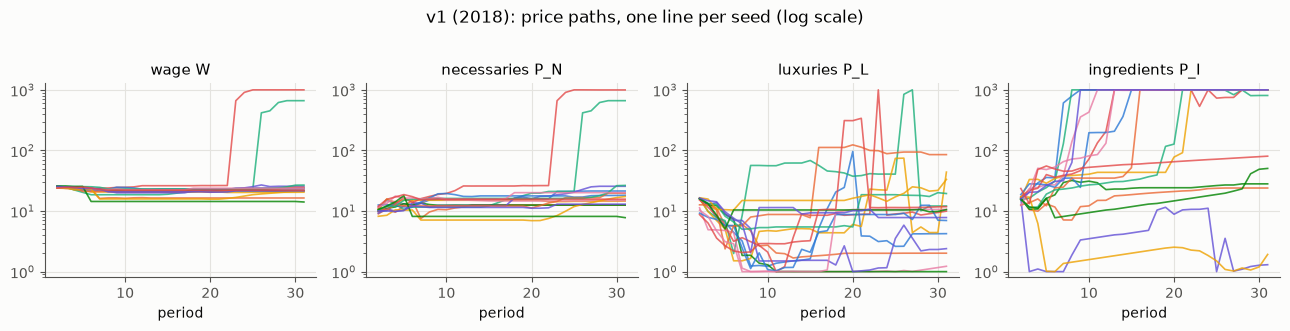

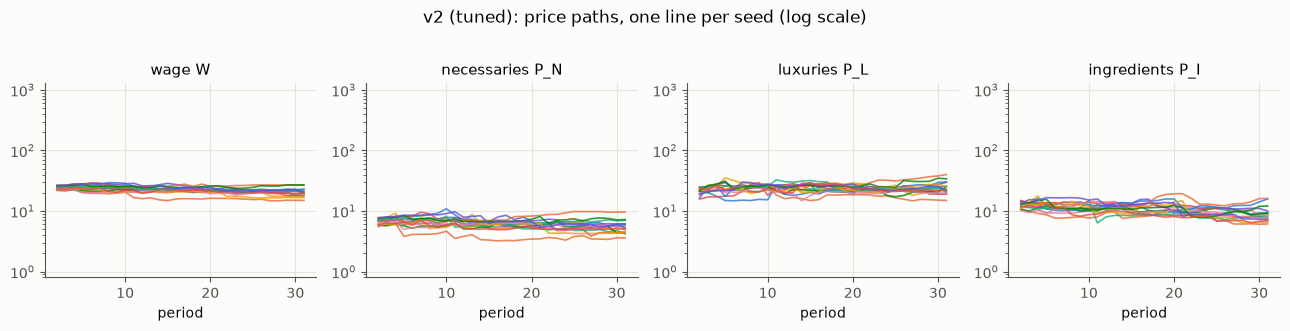

In [27]:
import anatomy
importlib.reload(anatomy)
SEEDS = list(range(1, N_SEEDS + 1))
t0 = time.time()
LOGS = {v: pmap(anatomy.batch, [(dict(version=v), s, 30) for s in SEEDS]) for v in ('v1', 'v2')}
print(f'({time.time() - t0:.0f} 秒)')


def plot_paths(logs, title):
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
    for i, (key, lab) in enumerate(zip('WNLI', ('wage W', 'necessaries P_N', 'luxuries P_L', 'ingredients P_I'))):
        for j, log in enumerate(logs):
            L = [r for r in log if 'W' in r]
            axes[i].plot([r['t'] + 1 for r in L], [r[key] for r in L], color=PAL[j % len(PAL)], lw=1.2, alpha=0.8)
        axes[i].set(yscale='log', ylim=(0.8, 1300), title=lab, xlabel='period')
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()


plot_paths(LOGS['v1'], 'v1 (2018): price paths, one line per seed (log scale)')
plot_paths(LOGS['v2'], 'v2 (tuned): price paths, one line per seed (log scale)')

In [28]:
def table(logs_by_version):
    print('版           最適化の失敗  境界に張り付いた期  贅沢品の生産 0 の期  賃金が 100 を超えた seed   労働の需給のずれ   最終期の賃金(平均 ± sd)')
    for v, logs in logs_by_version.items():
        S = [anatomy.summarize(l) for l in logs]
        m = lambda k: np.mean([s[k] for s in S])
        we = [s['W_end'] for s in S]
        print(f"{v:12s} {m('fail'):5.1f}          {m('bound'):5.1f}             {m('zeroL'):5.1f}              "
              f"{sum(s['blowup'] for s in S):2d}/{len(S)}                {m('gap'):6.1f}           {np.mean(we):7.1f} ± {np.std(we):.1f}")
    print('(回数は 30 期のうちの期数の、seed についての平均)')


table(LOGS)

版           最適化の失敗  境界に張り付いた期  贅沢品の生産 0 の期  賃金が 100 を超えた seed   労働の需給のずれ   最終期の賃金(平均 ± sd)
v1             5.9           12.6              14.5               2/16                  30.4             123.1 ± 274.3
v2             1.8            0.0               0.1               0/16                   2.3              20.5 ± 3.2
(回数は 30 期のうちの期数の、seed についての平均)


v1 は、まさに「カオス風」である。

- 原料の価格 $P_I$ は、多くの seed で上限 1000 に張り付く。
- 贅沢品の価格 $P_L$ は、下限 1 の近くに落ちる。そのあいだ、贅沢品はほとんど作られない。
- いくつかの seed では、賃金と必需品の価格が、そろって数百から 1000 まで上がる。
- 最適化の関数は、30 期のうち何期かで「失敗」(決められた回数で収束しなかった)を返す。

v2 は、見た目はずっと落ち着いている。価格は境界に張り付かず、贅沢品も作られ続ける。ただし、企業数が各分野 10 社前後に飽和しがちになる(ここでは示さないが、第 8 章で戻ってくる)。

これは書き直し(`me_ref`)での結果である。元のコードでも同じかを、v1 について確かめておく。

In [29]:
t0 = time.time()
n_check = min(8, len(SEEDS))
OLOGS = pmap(anatomy.orig_batch, [('v1', s, 30) for s in SEEDS[:n_check]])
print(f'({time.time() - t0:.0f} 秒)')
for s, lo, lr in zip(SEEDS, OLOGS, LOGS['v1']):
    so, sr = anatomy.summarize(lo), anatomy.summarize(lr)
    print(f"seed {s}: 境界 元 {so['bound']:2d} / 書き直し {sr['bound']:2d}   贅沢品 0 元 {so['zeroL']:2d} / 書き直し {sr['zeroL']:2d}   "
          f"最終期の賃金 元 {so['W_end']:7.2f} / 書き直し {sr['W_end']:7.2f}")

(7 秒)
seed 1: 境界 元 20 / 書き直し 20   贅沢品 0 元 16 / 書き直し 16   最終期の賃金 元   24.11 / 書き直し   24.11
seed 2: 境界 元  0 / 書き直し  0   贅沢品 0 元 12 / 書き直し 12   最終期の賃金 元   16.42 / 書き直し   16.42
seed 3: 境界 元 15 / 書き直し 15   贅沢品 0 元 24 / 書き直し 24   最終期の賃金 元  662.86 / 書き直し  662.86
seed 4: 境界 元  8 / 書き直し  8   贅沢品 0 元 18 / 書き直し 18   最終期の賃金 元   20.44 / 書き直し   20.44
seed 5: 境界 元 23 / 書き直し 23   贅沢品 0 元  0 / 書き直し  0   最終期の賃金 元   21.37 / 書き直し   21.37
seed 6: 境界 元 21 / 書き直し 21   贅沢品 0 元  0 / 書き直し  0   最終期の賃金 元   21.73 / 書き直し   21.73
seed 7: 境界 元  6 / 書き直し  6   贅沢品 0 元  2 / 書き直し  2   最終期の賃金 元   25.62 / 書き直し   25.62
seed 8: 境界 元 19 / 書き直し 19   贅沢品 0 元 12 / 書き直し 12   最終期の賃金 元 1000.00 / 書き直し 1000.00


元のコードでも同じである。以下では、なぜこうなるのかを、一期ずつ解剖していく。

### 4.1 作者の工夫をおさらいしておく

v2 の落ち着きは、作者の「チューンアップ」の成果である。

- 労働の需給のずれの罰を 3 倍にした。
- 分野ごとの利益を、企業数で割った(企業平均にした)。
- 赤字の分野は、損失を 10 倍に罰した。
- 働く条件を厳しくした(新規貯蓄が賃金の 1/3 を超えないと働かない)。

なぜこれで落ち着いたのか。それを理解するには、v1 で何が起きていたかを知る必要がある。

## 第 5 章 解剖 1: 一期のスコアの地形

v1 の、ある一期を取り出す。seed 1 で 6 期回したところ(つまり 7 期目の最適化の直前)である。元のやり方(前の期の価格から Nelder–Mead)で価格を選び、選ばれた価格のまわりで、**価格を一つずつ動かして**スコアがどう変わるかを見る。山登りで言えば、谷底の位置から、東西・南北それぞれの方向の断面を描くことに当たる。

v1 のスコアは「(労働の需給のずれ)² − 利益の総和」なので、二つの部分に分けて描く。

In [30]:
%%writefile -a anatomy.py
def state(pdict, seed, k):
    """k 期回したところの経済(次の期の最適化の直前)。"""
    return me_ref.run(me_ref.Params(**pdict), seed, k)


def chosen(e):
    """元のやり方の答え: 前の期の価格から Nelder-Mead。"""
    f = lambda x: e.calc(x)['score']
    return minimize(f, e.initial_guess(), method='Nelder-Mead')


def slices(a):
    """(Params の dict, seed, k, 点の数) → 選ばれた価格のまわりで、価格を一つずつ動かしたときの量。
    動かす範囲は、選ばれた値の 1/10 から上限 1000 まで(対数で等間隔)。"""
    pdict, seed, k, npts = a
    e = state(pdict, seed, k)
    r = chosen(e)
    out = dict(x=r.x.tolist(), success=bool(r.success), slices={})
    for j in range(4):
        rows = []
        grid = np.unique(np.r_[np.geomspace(max(1.0, r.x[j] / 10), 1000.0, npts), r.x[j]])
        for val in grid:
            x = r.x.copy()
            x[j] = val
            st = e.calc(x)
            if not np.isfinite(st['score']):
                continue
            gap = st['D'] - st['S']
            rows.append(dict(value=x[j], score=st['score'], gap2=gap ** 2, profit=gap ** 2 - st['score'],
                             S=st['S'], prodL=sum(st['qs']['L']),
                             new_fa=sum(c.fa_ing for c in st['new'].values() if c is not None)))
        out['slices'][j] = rows
    return out

Appending to anatomy.py


選ばれた価格 (W, P_N, P_L, P_I) = [ 22.11  15.23   1.24 789.6 ]  スコア -17490  最適化の成功: False


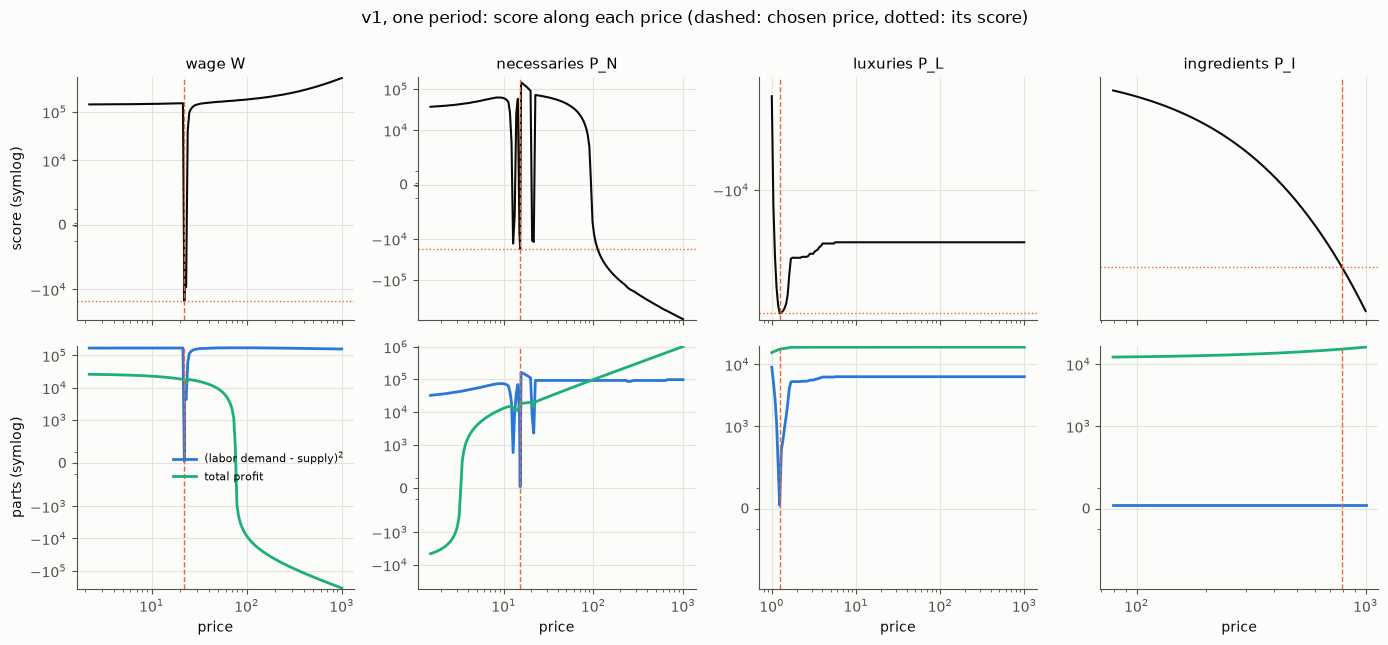

In [31]:
importlib.reload(anatomy)   # 書き足した関数を読み直す
SL = anatomy.slices((dict(version='v1'), 1, 6, 160))
x_star = np.array(SL['x'])
s_star = [r['score'] for r in SL['slices'][0] if r['value'] == x_star[0]][0]
print('選ばれた価格 (W, P_N, P_L, P_I) =', np.round(x_star, 2), ' スコア', round(s_star), ' 最適化の成功:', SL['success'])
names = ['wage W', 'necessaries P_N', 'luxuries P_L', 'ingredients P_I']
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), sharex='col')
for j in range(4):
    R = SL['slices'][j]
    v = [r['value'] for r in R]
    axes[0, j].plot(v, [r['score'] for r in R], color=INK, lw=1.5)
    axes[0, j].axhline(s_star, color=PAL[1], ls=':', lw=1)
    axes[0, j].axvline(x_star[j], color=PAL[1], ls='--', lw=1)
    axes[0, j].set(xscale='log', title=names[j])
    axes[0, j].set_yscale('symlog', linthresh=1e3, linscale=0.3)
    lo, hi = axes[0, j].get_ylim()
    axes[0, j].set_yticks([t for t in (-1e6, -1e5, -1e4, 0, 1e4, 1e5, 1e6) if lo <= t <= hi])
    axes[1, j].plot(v, [r['gap2'] for r in R], color=PAL[0], label='(labor demand - supply)$^2$')
    axes[1, j].plot(v, [r['profit'] for r in R], color=PAL[2], label='total profit')
    axes[1, j].axvline(x_star[j], color=PAL[1], ls='--', lw=1)
    axes[1, j].set(xscale='log', xlabel='price')
    axes[1, j].set_yscale('symlog', linthresh=1e2, linscale=0.3)
    lo, hi = axes[1, j].get_ylim()
    axes[1, j].set_yticks([t for t in (-1e5, -1e4, -1e3, 0, 1e3, 1e4, 1e5, 1e6) if lo <= t <= hi])
axes[0, 0].set_ylabel('score (symlog)'); axes[1, 0].set_ylabel('parts (symlog)')
axes[1, 0].legend(fontsize=8)
fig.suptitle('v1, one period: score along each price (dashed: chosen price, dotted: its score)', y=1.0)
plt.tight_layout(); plt.show()

上の段がスコア、下の段がその二つの部分(青: 労働の需給のずれ²、緑: 利益の総和)である。縦軸は、正負を両方描ける対数目盛にしてある。縦の破線が選ばれた価格、上の段の横の点線が選ばれた点のスコアである。横軸は、選ばれた値の 1/10 から上限 1000 まで。四つの価格は、それぞれまったく違う役割を負わされている。

### 5.1 原料の価格: 企業間の移転なので、利益の総和では消える

原料の価格 $P_I$ を動かしても、労働の需給は変わらない(青の線が平ら)。利益の総和(緑)だけが、**まっすぐな線**で増える。

なぜ直線なのか。原料は企業が企業から買う。原料の代金は、買う企業(必需品・贅沢品の企業)には費用、売る企業(原料の企業)には売上になる。利益を全部足すと、この二つは**打ち消し合う**。打ち消されずに残るのは、新しい企業の固定資産に使う原料だけである。その代金は、原料の企業には売上として入るが、買う側では(資本家の負債として)利益の計算の外にある。

ただし、新しい企業自身の利益も総和に入っている。新企業の固定資産の価格は、今期の原料の価格で決まり、その 1/10 が今期の償却(費用)になる。だから、利益の総和を $P_I$ で微分すると、

$$
\frac{\partial(\text{利益の総和})}{\partial P_I} = \Big(1 - \frac{1}{10}\Big) \times (\text{新企業の固定資産に要る原料の量})
$$

になるはずである。確かめる。

In [32]:
R = SL['slices'][3]
v = np.array([r['value'] for r in R]); pr = np.array([r['profit'] for r in R]); nf = [r['new_fa'] for r in R]
i0, i1 = 5, len(v) - 1
slope = (pr[i1] - pr[i0]) / (v[i1] - v[i0])
print(f'利益の総和の P_I についての傾き: {slope:.4f}')
print(f'新企業の固定資産に要る原料の量: {nf[i0]:.4f}(P_I を動かしても {min(nf):.4f}〜{max(nf):.4f})')
print(f'その 0.9 倍: {0.9 * nf[i0]:.4f}')

利益の総和の P_I についての傾き: 6.3320
新企業の固定資産に要る原料の量: 7.0355(P_I を動かしても 7.0355〜7.0355)
その 0.9 倍: 6.3320


一致する。$P_I$ を上げれば上げるほど「利益の総和」が増えるので、最適化は $P_I$ を上限の 1000 に向けて押し上げる。これが、原料の価格が 1000 に張り付く理由である。原料の価格は、需給を合わせる役割をまったく果たしていない。

### 5.2 贅沢品の価格: 労働市場を釣り合わせる「つまみ」

贅沢品の価格 $P_L$ の断面を見ると、選ばれた点は、贅沢品の企業が**赤字になるほど安い**ところにある。$P_L$ を上げると、緑の利益の総和は増える(贅沢品の企業の赤字が減る)。それなのに、最適化は $P_L$ を上げない。

理由は青の線にある。$P_L$ を上げると贅沢品が売れなくなり、贅沢品を作る労働が要らなくなる。すると労働の需要が減り、需給のずれが広がる。逆に $P_L$ を下げれば、贅沢品が売れ、労働の需要が増えて、需給のずれが縮む。

つまり最適化は、**贅沢品の価格を、労働の需給を合わせるための「つまみ」として使っている。** 贅沢品の企業は赤字が続くので、新しい企業が参入せず、贅沢品の分野は 1 社のままになる。第 4 章で見た「贅沢品の価格が下限に落ち、贅沢品が作られなくなる」現象は、ここから来ている。

#### 囲み: 贅沢品は、余った労働の受け皿

「贅沢品が、必需品に要らなかった労働を吸い取る」という役割は、v1 では最適化がたまたま見つけたものだった。同じ作者が 2026 年に作った「必需品と贅沢品のマクロ経済シミュレーション」(Gemini と共作)では、これが規則として書き込まれている。そこでは、労働をまず必需品の必要量に割り当て、**残りを贅沢品に回す**。必需品の生産性が上がるほど、贅沢品に回る労働が増える。

経済学には、これにあたる理論がある。生産性が上がると、同じ必需品を作るのに要る人手が減る。一方、必需品への需要には飽和がある(エンゲルの法則)。だから、全員が働き続けるには、**新しい需要(贅沢品・サービス)が、余った人手を吸い取らなければならない**。パシネッティ(Pasinetti 1981)は、この条件を「完全雇用のためのマクロ経済的条件」として定式化し、技術の進歩と需要の構成の変化(構造変化)の理論を作った。ボーモル(Baumol 1967)の「不均整成長」や、Kongsamut, Rebelo, Xie(2001)の、必需品に飽和がある成長モデルも、同じ現象を扱っている。

v1 の最適化は、この「受け皿」の役割を、贅沢品の価格を費用以下に下げることで、無理やり果たさせていた。正しくは、贅沢品の需要が、所得と好みから自然に生まれ、そこに労働が移っていく形で書くべきである。第 9 章で見る「機械の高度化と雇用」の話も、この構造変化の一部である。

(贅沢品・嗜好品・知財の区別は、シリーズ全体にかかわるので、ノート 2 の 8.3 節の表にまとめた。このノートの贅沢品は、その表の「消える」贅沢品にあたる)

### 5.3 賃金と必需品の価格: 細い谷と、上限のない利益

賃金 $W$ と必需品の価格 $P_N$ の断面では、青の線(需給のずれ²)が、選ばれた点のすぐ近くで急に跳ね上がる。労働の供給が、2.4 の式のとおり**階段状**に変わるからである。とくに、新規貯蓄 $W - P_N d$ が 0 以下になると、働く人が一度に 0 になる。選ばれた点は、この階段のあいだの細い谷の底にある。

そして、$P_N$ の断面の右側を見てほしい。$P_N$ を上げていくと、働く人は 0 になり、需給のずれ²は大きいところで**頭打ち**になる(ずれは労働の需要より大きくなれないから)。ところが、緑の利益の総和は**どこまでも増え続ける**。必需品の需要は、一人 1 単位より下には減らない(2.3)。だから、値段を上げれば上げるほど、売上が増える。$P_N$ を十分に上げると、スコアは、選ばれた点よりも**低く**なる。

これは、選ばれた点が、スコアの本当の最小点ではないことを意味する。次の章で、本当の最小点を探す。

### 5.4 平らな方向

もう一つ、第 3 章の伏線を回収しておく。贅沢品の需要が 0 の期には、$P_L$ を動かしても何も変わらない。スコアはその方向に**平ら**である。平らな方向がある関数では、最小点は一つに決まらない。Nelder–Mead 法は、平らな方向のどこかで止まる。どこで止まるかは、計算の細かな事情(丸め誤差)で決まる。第 3 章で、書き直しと元のコードが $P_L$ だけでずれたのは、これだった。

## 第 6 章 解剖 2: 本当の最小点はどこか

### 6.1 出発点を変えてみる

同じ一期(v1、seed 1、7 期目)で、出発点を変えて Nelder–Mead 法を回す。前の期の価格を、それぞれ ±30% くらいランダムにずらした 20 点から出発する。さらに、大域的な探索(差分進化)でも解く。

In [33]:
%%writefile -a anatomy.py
def multistart(a):
    """(Params の dict, seed, k, 出発点の数, ずらし幅) → 前の期の価格を ±ずらし幅 で変えた多点からの Nelder-Mead の答え。"""
    pdict, seed, k, n, spread = a
    e = state(pdict, seed, k)
    f = lambda x: e.calc(x)['score']
    x0 = e.initial_guess()
    rng = np.random.default_rng(seed)
    sols = []
    for i in range(n):
        xi = x0 * np.exp(rng.normal(0, spread, len(x0)))
        r = minimize(f, xi, method='Nelder-Mead')
        st = e.calc(r.x)
        if np.isfinite(st['score']):
            sols.append(dict(score=st['score'], x=r.x.tolist(), S=st['S'], prodL=sum(st['qs']['L'])))
    r = chosen(e)
    st = e.calc(r.x)
    orig = dict(score=st['score'], x=r.x.tolist(), S=st['S'], prodL=sum(st['qs']['L']))
    return dict(orig=orig, sols=sols)


def global_de(a):
    """(Params の dict, seed, k) → 差分進化(大域的な探索)の答え。"""
    pdict, seed, k = a
    e = state(pdict, seed, k)
    f = lambda x: e.calc(x)['score']
    r = differential_evolution(f, [(1, 1000)] * 4, seed=0, maxiter=300, tol=1e-8, polish=False)
    st = e.calc(r.x)
    return dict(score=st['score'], x=r.x.tolist(), S=st['S'], prodL=sum(st['qs']['L']))


def corner(a):
    """(Params の dict, seed, k) → 元のやり方の答えのスコアと、崩壊の隅(W=1, P_N=1000, P_I=1000)のスコア。"""
    pdict, seed, k = a
    e = state(pdict, seed, k)
    if e.log and 'collapse' in e.log[-1]:
        return None
    f = lambda x: e.calc(x)['score']
    r = chosen(e)
    cs = [f([1, 1000, L, 1000]) for L in (1, 10, 100, 500, 1000)]
    return dict(seed=seed, k=k, chosen=float(r.fun), corner=float(min(cs)))

Appending to anatomy.py


(3 秒)
元のやり方     score =     -17490   (W, P_N, P_L, P_I) = [ 22.1  15.2   1.2 789.6]   働く人  426   贅沢品  153
差分進化       score =    -954640   (W, P_N, P_L, P_I) = [   1.  1000.   369.2 1000. ]   働く人    0   贅沢品    0
20 点からの答え(スコアの低い順に 5 つ):
               score =    -946534   (W, P_N, P_L, P_I) = [   8.5 1000.    81.2  482. ]   働く人    0   贅沢品    0
               score =    -238034   (W, P_N, P_L, P_I) = [  2.5 291.3   3.9   1. ]   働く人    0   贅沢品    1
               score =    -167983   (W, P_N, P_L, P_I) = [281.8 292.    4.  994.2]   働く人    0   贅沢品    1
               score =     -18092   (W, P_N, P_L, P_I) = [ 20.5  12.4   3.6 999.6]   働く人  409   贅沢品    5
               score =     -18089   (W, P_N, P_L, P_I) = [  20.7   12.7    4.  1000. ]   働く人  410   贅沢品    1


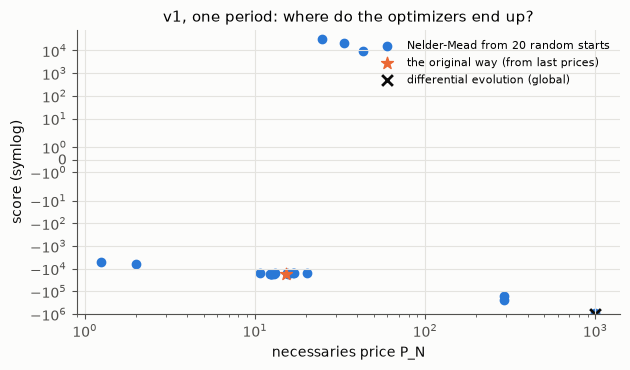

In [34]:
importlib.reload(anatomy)
t0 = time.time()
MS, DE = pmap(anatomy.multistart, [(dict(version='v1'), 1, 6, 20, 0.3)])[0], anatomy.global_de((dict(version='v1'), 1, 6))
print(f'({time.time() - t0:.0f} 秒)')
fmt = lambda d: f"score = {d['score']:10.0f}   (W, P_N, P_L, P_I) = {np.round(d['x'], 1)}   働く人 {d['S']:4.0f}   贅沢品 {d['prodL']:4.0f}"
print('元のやり方    ', fmt(MS['orig']))
print('差分進化      ', fmt(DE))
sols = sorted(MS['sols'], key=lambda d: d['score'])
print('20 点からの答え(スコアの低い順に 5 つ):')
for d in sols[:5]:
    print('              ', fmt(d))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.scatter([d['x'][1] for d in sols], [d['score'] for d in sols], color=PAL[0], label='Nelder-Mead from 20 random starts')
ax.scatter([MS['orig']['x'][1]], [MS['orig']['score']], color=PAL[1], s=80, marker='*', label='the original way (from last prices)')
ax.scatter([DE['x'][1]], [DE['score']], color=INK, s=60, marker='x', label='differential evolution (global)')
ax.set(xscale='log', yscale='symlog', xlabel='necessaries price P_N', ylabel='score (symlog)',
       title='v1, one period: where do the optimizers end up?')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

答えははっきりしている。

- 元のやり方の答えは、スコアが約 −1.7 万の点である。
- 20 点から出発すると、いくつかは、スコアが**約 −90 万**の点に行く。その点は、「賃金 ≈ 1、必需品の価格 = 1000、働く人 0、贅沢品 0」である。
- 大域的な探索(差分進化)も、同じ点に行く。

スコアの本当の最小点は、**誰も働かず、必需品が最高値の、経済の崩壊点**だったのである。

### 6.2 ほかの期・ほかの seed でも同じか

一期だけでは心もとないので、seed と期を変えて、元のやり方の答えと、「崩壊の隅」(賃金 1、必需品 1000、原料 1000)のスコアを比べる。v2 でも同じことをする。

In [35]:
n_c = 2 if FAST else 4
jobs = [(dict(version=v), s, k) for v in ('v1', 'v2') for s in range(1, n_c + 1) for k in (2, 5, 10, 15)]
t0 = time.time()
CR = pmap(anatomy.corner, jobs)
print(f'({time.time() - t0:.0f} 秒)')
for v in ('v1', 'v2'):
    rows = [(j, c) for j, c in zip(jobs, CR) if j[0]['version'] == v and c is not None]
    lower = sum(c['corner'] < c['chosen'] for _, c in rows)
    print(f'--- {v}: 崩壊の隅のほうがスコアが低い状態  {lower} / {len(rows)}')
    for j, c in rows:
        print(f"  seed {c['seed']} {c['k'] + 1:2d} 期目: 元のやり方 {c['chosen']:10.0f}   崩壊の隅 {c['corner']:10.0f}   {'← 隅が低い' if c['corner'] < c['chosen'] else ''}")

(3 秒)
--- v1: 崩壊の隅のほうがスコアが低い状態  16 / 16
  seed 1  3 期目: 元のやり方     -10888   崩壊の隅    -956166   ← 隅が低い
  seed 1  6 期目: 元のやり方     -13471   崩壊の隅    -958614   ← 隅が低い
  seed 1 11 期目: 元のやり方     -18536   崩壊の隅    -946000   ← 隅が低い
  seed 1 16 期目: 元のやり方     -12404   崩壊の隅    -898056   ← 隅が低い
  seed 2  3 期目: 元のやり方      -8390   崩壊の隅    -955879   ← 隅が低い
  seed 2  6 期目: 元のやり方        353   崩壊の隅    -954094   ← 隅が低い
  seed 2 11 期目: 元のやり方      -8189   崩壊の隅    -937540   ← 隅が低い
  seed 2 16 期目: 元のやり方     -10403   崩壊の隅    -927028   ← 隅が低い
  seed 3  3 期目: 元のやり方      -8688   崩壊の隅    -938713   ← 隅が低い
  seed 3  6 期目: 元のやり方     -10593   崩壊の隅    -928142   ← 隅が低い
  seed 3 11 期目: 元のやり方     -13476   崩壊の隅    -905141   ← 隅が低い
  seed 3 16 期目: 元のやり方      -3589   崩壊の隅    -601714   ← 隅が低い
  seed 4  3 期目: 元のやり方      -9188   崩壊の隅    -939719   ← 隅が低い
  seed 4  6 期目: 元のやり方     -12478   崩壊の隅    -930537   ← 隅が低い
  seed 4 11 期目: 元のやり方     -12222   崩壊の隅    -909238   ← 隅が低い
  seed 4 16 期目: 元のやり方     -11057   崩壊の隅    -877684   ← 隅が低い


v1 では、**どの状態でも**、崩壊の隅のスコアが桁違いに低い。v2 でも、半分以上の状態で隅のほうが低い(とくに序盤)。v2 のチューンアップは、崩壊点を消したのではなく、状態によっては隅を少し高くしただけである。

### 6.3 v2 には、極小がたくさんある

v2 でも、同じ一期で出発点を変えてみる。

In [36]:
MS2 = pmap(anatomy.multistart, [(dict(version='v2'), 1, 6, 20, 0.3)])[0]
sols2 = sorted(MS2['sols'], key=lambda d: d['score'])
print('元のやり方    ', fmt(MS2['orig']))
print('20 点からの答えのスコア:', [int(d['score']) for d in sols2])
print('最良        ', fmt(sols2[0]))

元のやり方     score =       -613   (W, P_N, P_L, P_I) = [29.3  8.6 14.9 13.8]   働く人  712   贅沢品  466
20 点からの答えのスコア: [-2258, -2205, -2155, -2119, -2016, -1671, -1133, -892, -849, -610, -520, -446, -300, 506, 1646, 18857, 20729, 68042, 73559, 515112]
最良         score =      -2258   (W, P_N, P_L, P_I) = [27.9 10.8 28.2 12.4]   働く人  715   贅沢品  601


20 の出発点から、ほとんど全部が別々の極小に落ちる。元のやり方の答えも、最良ではない。最良の点とは、贅沢品の価格などがかなり違う。どの極小に落ちるかは、出発点、つまり**前の期の価格**で決まる。経路(これまでの価格の歴史)が、結果を決めている。

### 6.4 なぜ崩壊点が最小になるのか

v1 のスコアは、「労働の需給を合わせながら、利益の総和を最大にする」というものだった。これは、**全企業がひとまとまりになって(カルテルを作って)価格を決める**問題である。市場ではなく、独占の計画者の問題と言ってよい。

その計画者にとって、一番得なのは何か。

- 必需品は、値段を上げても、一人 1 単位より下には売れ行きが落ちない。だから、値段は高いほど得である。
- 労働の需給のずれへの罰には、上限がある(ずれは労働の需要より大きくなれない)。
- 賃金は費用なので、低いほど得である。

この三つを合わせると、「必需品を最高値にし、賃金を最低にして、誰も雇わない」のが最善になる。必需品の代金を誰がどう払うのか(働かない人の生活費は社会的負債から出る)は、スコアの中に入っていない。

### 6.5 局所性が経済を支えていた

それでも v1 が、まがりなりにも経済らしく動いたのはなぜか。

毎期の最適化は、**前の期の価格から**出発する Nelder–Mead 法だった。Nelder–Mead 法は、出発点に近い谷にしか行けない。前の期の価格のまわりに、そこそこの谷があれば、そこで止まる。崩壊点ははるか遠くにあるので、たいていはそこまで行かない。たまに谷が浅く、坂を転がり続けると、賃金と必需品の価格がそろって暴走する(第 4 章の seed のいくつか)。

つまり、一期ずつの局所的な最適化の列は、本当の意味での最適化ではなかった。**前の期の価格から、スコアが少し良くなる方へ価格を動かす「調整の過程」**として働いていた。1.2 の模索過程に近いものである。

作者自身も、最適化が「失敗」を返しても、結果が間違いとは限らない、と感じていた。その感覚は正しかった。ただし理由は逆で、**上手に最適化すれば、必ず壊れるスコアだった**のである。最適化の「下手さ」(局所性)が、経済を支えていた。

見方を変えると、「前の期の価格から出発し、少しだけ良くなる方へ動いて止まる」というのは、それ自体が一つの**戦術**でもある。先のことを見通さず、目の前の改善だけを取る、近視眼的な戦術である。現実の企業や市場が、前の値段を基準に少しずつ値を変えるのに近いという意味では、むしろ現実的で直感的な戦術とすら言える。v1 で経済を支えていたのは、この暗黙の戦術だった。8.1 で、これを「式が足りない分を埋める戦術」として位置づけ、9.3 で、スコアに書き込める形(慣性の項)に定式化する。

では、何を最適化すればよかったのか。それが第 8 章の主題である。その前に、第 7 章で会計を検算しておく。

## 第 7 章 解剖 3: 会計

第 5・6 章では、スコアの形を調べた。この章では、モデルの**お金の出入り**を検算する。1.5 で見たとおり、会計が正しければ、毎期

$$
\Delta(\text{民間の純金融資産}) = \Delta(\text{社会的負債})
$$

が成り立つはずである。民間の純金融資産とは、労働者と資本家の貯蓄の合計から、資本家の負債を引いたものである。社会的負債は、誰にも帰属しない負債の勘定なので、民間の黒字の相手方になっているはずだ。

v7 は、元のコードの中で、この両方の量を毎期記録している(`social_debt` と `savings_increase`)。だから、元のコードを**そのまま**走らせて検算できる。

### 7.1 検算

In [37]:
%%writefile -a anatomy.py
# 元のコードの会計の三つの誤りを直す差分(第 7 章)。(元の文字列, 直した文字列) の組。
PATCH_SIGN = ('p - curPrice.wages * c.laborsPerProduct \\\n                    + curPrice.ingredients',
              'p - curPrice.wages * c.laborsPerProduct \\\n                    - curPrice.ingredients')
PATCH_OVERWRITE = ('profit[c.ownerId] = curP[i] * (\\', 'profit[c.ownerId] += curP[i] * (\\')
PATCH_OVERTIME_1 = ('sd += 2 * curPrice.wages * (curDemandOfLabors', 'sd += curPrice.wages * (curDemandOfLabors')
PATCH_OVERTIME_2 = ('socialDebt += 2 * curPrice.wages \\', 'socialDebt += curPrice.wages \\')
PATCHES = {'original': (),
           'sign + overwrite': (PATCH_SIGN, PATCH_OVERWRITE),
           'sign + overwrite + overtime': (PATCH_SIGN, PATCH_OVERWRITE, PATCH_OVERTIME_1, PATCH_OVERTIME_2)}


def audit_orig(a):
    """(PATCHES の名前, seed, T) → 元の v7 を回し、期ごとの「社会的負債の増分」と「民間の純金融資産の増分」を返す。"""
    import io, contextlib
    name, seed, T = a
    m = orig_tools.load('v7', PATCHES[name])
    e = orig_tools.new_economy(m, seed)
    with contextlib.redirect_stdout(io.StringIO()):
        for t in range(T):
            e.step(t + 1)
    h = e.history
    return [dict(sd=h['social_debt'][t], dnet=h['savings_increase'][t], W=h['price_W'][t],
                 gap=h['demand_vs_supply_of_labors'][t]) for t in range(len(h['social_debt']))]


def balances(a):
    """(Params の dict, seed, T) → me_ref で、期ごとの部門の収支(労働者・資本家・社会的負債)を返す。"""
    pdict, seed, T = a
    e = me_ref.Economy(me_ref.Params(**pdict), seed)
    rows = []
    for t in range(T):
        lw, cs, cd = e.lab_savings.sum(), e.cap_savings.sum(), e.cap_debt.sum()
        st = e.step()
        rows.append(dict(workers=e.lab_savings.sum() - lw,
                         capitalists=(e.cap_savings.sum() - e.cap_debt.sum()) - (cs - cd),
                         social_debt=st['sd']))
    return rows


def alpha_I_path(a):
    """(Params の dict, seed, T) → 期ごとの、原料の分野の(生産量で重みをつけた)一製品あたり原料 α_I。"""
    pdict, seed, T = a
    e = me_ref.Economy(me_ref.Params(**pdict), seed)
    out = []
    for t in range(T):
        try:
            st = e.step()
        except Exception:
            break
        q = st['qs']['I']; c = st['comps']['I']
        out.append(sum(qi * ci.alpha for qi, ci in zip(q, c)) / sum(q))
    return out

Appending to anatomy.py


(12 秒)


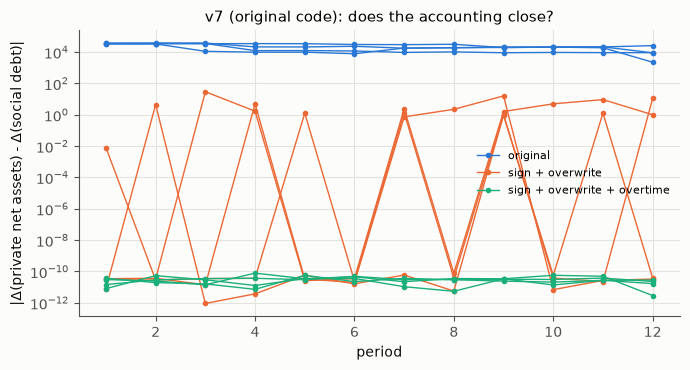

original                    : ずれの絶対値の最大 3.84e+04
sign + overwrite            : ずれの絶対値の最大 29.6
sign + overwrite + overtime : ずれの絶対値の最大 7.84e-11


In [38]:
importlib.reload(anatomy)
n_a = 2 if FAST else 4
t0 = time.time()
AUD = {name: pmap(anatomy.audit_orig, [(name, s, 12) for s in range(1, n_a + 1)]) for name in anatomy.PATCHES}
print(f'({time.time() - t0:.0f} 秒)')
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, (name, runs) in enumerate(AUD.items()):
    for j, run in enumerate(runs):
        res = [max(abs(r['dnet'] - r['sd']), 1e-13) for r in run]
        ax.plot(range(1, len(res) + 1), res, color=PAL[i], marker='o', ms=3, lw=1, label=name if j == 0 else None)
ax.set(yscale='log', xlabel='period', ylabel='|Δ(private net assets) - Δ(social debt)|',
       title='v7 (original code): does the accounting close?')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
for name, runs in AUD.items():
    print(f"{name:28s}: ずれの絶対値の最大 {max(abs(r['dnet'] - r['sd']) for run in runs for r in run):.3g}")

元のコードのままでは、毎期、**1 万から 3.5 万**もずれる。会計が閉じていない。

ずれの原因を探すと、資本家の利益を計算する部分(`## 資本家利潤` の二か所。一期の計算 `_calcNextState` と、状態を進める `step`)に、二つの誤りが見つかる。それを直すと(橙)、ほとんどの期でずれは 0 になるが、ときどき 1 から数十のずれが残る。残りのずれは、残業の扱いから来ている。三つとも直すと(緑)、ずれは計算機の丸め誤差($10^{-10}$ 程度)になり、会計は**ぴったり閉じる**。

### 7.2 三つの誤り

直した差分を、そのまま見せる。左が元の文字列、右が直した文字列である。

In [39]:
for name, (a, b) in [('誤り 1: 原料費の符号', anatomy.PATCH_SIGN), ('誤り 2: 複数社の利益の上書き', anatomy.PATCH_OVERWRITE),
                     ('誤り 3a: 残業代(一期の計算)', anatomy.PATCH_OVERTIME_1), ('誤り 3b: 残業代(状態を進める)', anatomy.PATCH_OVERTIME_2)]:
    n = orig_tools.fetch('micro_economy_7.py').count(a)
    print(f'--- {name}(元のコードに {n} か所)')
    print('  元  :', a.replace('\n', '\n        '))
    print('  直し:', b.replace('\n', '\n        '))

--- 誤り 1: 原料費の符号(元のコードに 6 か所)
  元  : p - curPrice.wages * c.laborsPerProduct \
                            + curPrice.ingredients
  直し: p - curPrice.wages * c.laborsPerProduct \
                            - curPrice.ingredients
--- 誤り 2: 複数社の利益の上書き(元のコードに 6 か所)
  元  : profit[c.ownerId] = curP[i] * (\
  直し: profit[c.ownerId] += curP[i] * (\
--- 誤り 3a: 残業代(一期の計算)(元のコードに 1 か所)
  元  : sd += 2 * curPrice.wages * (curDemandOfLabors
  直し: sd += curPrice.wages * (curDemandOfLabors
--- 誤り 3b: 残業代(状態を進める)(元のコードに 1 か所)
  元  : socialDebt += 2 * curPrice.wages \
  直し: socialDebt += curPrice.wages \


**誤り 1: 原料費の符号。** 資本家の利益を、各社について「生産量 × (価格 − 賃金 × 一製品あたり労働 **+** 原料の価格 × 一製品あたり原料)」と計算していた。原料は費用なので、引かなければならない。企業の利潤率を計算する別の関数(`_calcProfitOfCompany`)では正しく引いているので、ここだけの書き間違いである。

**誤り 2: 複数社の利益の上書き。** 資本家は、同じ分野や違う分野に何社も持つことがある。ところが、各社の利益を資本家ごとに `=` で代入していたので、最後の一社の利益だけが残っていた。`+=` で足さなければならない。

**誤り 3: 残業代。** 誤り 1・2 を直したあとに残るずれを調べると、毎期ちょうど $W \cdot \max(0, D - S)$ に一致する。確かめる。

In [40]:
run = AUD['sign + overwrite'][0]
print(' 期   ずれ(民間 − 社会的負債)   −W·max(0, D − S)')
for t, r in enumerate(run):
    print(f"{t + 1:3d}   {r['dnet'] - r['sd']:12.4f}            {-r['W'] * max(0.0, r['gap']):12.4f}")

 期   ずれ(民間 − 社会的負債)   −W·max(0, D − S)
  1        -0.0081                 -0.0081
  2         0.0000                 -0.0000
  3        -0.0000                 -0.0000
  4        -0.0000                 -0.0000
  5        -1.2612                 -1.2612
  6         0.0000                 -0.0000
  7        -1.3492                 -1.3492
  8        -0.0000                 -0.0000
  9        -0.9790                 -0.9790
 10        -0.0000                 -0.0000
 11        -1.2873                 -1.2873
 12        -0.0000                 -0.0000


### 7.3 残業の扱い: 説明と実装の食い違い

労働の需要 $D$ が供給 $S$ より多いとき、働く人は残業をしたとみなされる。そのお金の流れを、実装どおりに追うと、こうなる。

- 企業は、労働の需要 $D$ の全部について、賃金 $W$ を払う(企業の費用の計算は、一製品あたり労働 × 賃金 × 生産量)。払う額は $W D$。
- 働く人は、$W S$ に加えて、残業代として $2W(D - S)$ を受け取る。
- 社会的負債は、残業代 $2W(D - S)$ を払う。

働く人の受け取りは $WS + 2W(D-S)$、企業と社会的負債の払いは $WD + 2W(D-S)$ である。差の $W(D - S)$ は、誰も受け取っていない。お金が消えている。

作者の説明は「残業代は通常の賃金の二倍。その原資は社会的負債」である。これをどう読むかで、直し方の解釈が二つある。

- (a) 企業は通常の賃金 $W$ を払い、割増の $W$ だけを社会的負債が出す。
- (b) 企業が残業分に払う $W(D-S)$ は、国(社会的負債)に**残業税**として入り、国が残業代 $2W(D-S)$ を払う。

どちらでも、社会的負債の正味の増分は $W(D - S)$ になる。だから、意図がどちらであっても、直し方は一つ(社会的負債への計上を $2W(D-S)$ から $W(D-S)$ にする)に決まる。

(b) の読みは突飛に見えるかもしれない。だが、残業に課税し、その分を失業者などに回すという政策は、実際に論じられてきた考え方で、作者自身も以前から論じていた。モデルの意図がそれだった可能性はある。ここでは、意図は推測にとどめる。

### 7.4 社会的負債は政府部門だった

三つを直すと、会計はぴったり閉じる。部門ごとに見ると、どうなっているか。書き直し(三つとも直した設定)で、最初の 6 期の収支を並べる。

In [41]:
B = anatomy.balances((dict(version='v1', fix_profit=True, fix_overtime=True), 1, 6))
print(' 期   労働者の黒字   資本家の黒字(負債の返済を含む)   民間の合計   社会的負債の増分   差')
for t, r in enumerate(B):
    tot = r['workers'] + r['capitalists']
    print(f"{t + 1:3d}   {r['workers']:10.1f}      {r['capitalists']:14.1f}               {tot:10.1f}    {r['social_debt']:12.1f}     {tot - r['social_debt']:.1e}")

 期   労働者の黒字   資本家の黒字(負債の返済を含む)   民間の合計   社会的負債の増分   差
  1      -1427.7                -5.4                  -1433.0         -1433.0     9.1e-13
  2      -1750.8                 9.6                  -1741.2         -1741.2     -6.1e-12
  3      -2509.8               -18.1                  -2527.9         -2527.9     -3.6e-12
  4      -1677.2               -15.3                  -1692.5         -1692.5     -5.0e-12
  5       -780.2                -5.9                   -786.1          -786.1     2.5e-12
  6        155.5                -1.2                    154.2           154.2     -5.2e-11


民間(労働者と資本家)の黒字の合計が、社会的負債の増分にぴったり一致する。社会的負債は、民間の黒字の**正確な相手方**、つまり**政府部門の負債**として働いている。生活保護を払い、余った労働者の賃金を払い、資本家の利益の余りを受け取る。中身は、政府の財政赤字そのものである。

ここで、検討の初めに立てていた見立てを訂正しておく。モデルを読んだ段階では、「社会的負債が会計の穴をすべて吸い込み、誰の予算制約も効いていないのではないか」と予想していた。検算してみると、そうではなかった。**会計は(三つの誤りを直せば)閉じている。** 足りないのは、閉じた会計ではなく、次のものである。

- **政府の制約**: 社会的負債はいくら増えてもよい。税も、国債の利払いも、借りられる上限もない。
- **政府の行動**: 何を目的に、いくら払うかの規則がない。v7 では、スコアの「社会的負債を減らせ」という項が、唯一の政府の行動に当たる。

この二つが欠けていることは、第 8 章で「誰の予算が釣り合うのか」という問題として戻ってくる。

### 7.5 誤りは、動きを変えたか

v1・v2 のスコアには、社会的負債が入っていない。だから、会計の誤りはスコアには効かない。しかし、誤った利益は資本家の負債の返済に使われ、負債の有無は参入の可否を決める(負債のある資本家は参入できない)。だから、動きにも影響しうる。三つとも直した場合と比べる。

In [42]:
fixed = dict(fix_profit=True, fix_overtime=True)
t0 = time.time()
LOGS_FIX = {v: pmap(anatomy.batch, [(dict(version=v, **fixed), s, 30) for s in SEEDS]) for v in ('v1', 'v2')}
print(f'({time.time() - t0:.0f} 秒)')
table({'v1 元のまま': LOGS['v1'], 'v1 直した': LOGS_FIX['v1'], 'v2 元のまま': LOGS['v2'], 'v2 直した': LOGS_FIX['v2']})
for name, logs in [('v1 元のまま', LOGS['v1']), ('v1 直した', LOGS_FIX['v1']), ('v2 元のまま', LOGS['v2']), ('v2 直した', LOGS_FIX['v2'])]:
    sd = np.mean([sum(r['sd'] for r in l if 'sd' in r) for l in logs])
    print(f'{name}: 30 期の社会的負債の累計(seed の平均) {sd:14.0f}')

(10 秒)
版           最適化の失敗  境界に張り付いた期  贅沢品の生産 0 の期  賃金が 100 を超えた seed   労働の需給のずれ   最終期の賃金(平均 ± sd)
v1 元のまま        5.9           12.6              14.5               2/16                  30.4             123.1 ± 274.3
v1 直した         5.1           11.8              14.2               0/16                  19.9              22.4 ± 3.7
v2 元のまま        1.8            0.0               0.1               0/16                   2.3              20.5 ± 3.2
v2 直した         1.4            0.3               1.4               0/16                   2.6              20.1 ± 2.9
(回数は 30 期のうちの期数の、seed についての平均)
v1 元のまま: 30 期の社会的負債の累計(seed の平均)      -38265536
v1 直した: 30 期の社会的負債の累計(seed の平均)          -9917
v2 元のまま: 30 期の社会的負債の累計(seed の平均)        -301004
v2 直した: 30 期の社会的負債の累計(seed の平均)          10208


直すと、社会的負債の記録は大きく変わる(v1 では、累計が数千万の赤字から、ほぼ釣り合いへ)。しかし、v1 のカオス風の振る舞い(境界への張り付き、贅沢品の消失)は、ほとんど変わらない。

**会計の誤りは、カオスの原因ではなかった。** 原因は第 6 章で見たスコアの構造にある。会計の誤りは、v7 のように社会的負債をスコアに入れた版で、スコアが実際とは違う量を見ていたことのほうに効いている(第 9 章)。

### 7.6 原料の自己投入と、レオンチェフの投入産出

最後に、2.7 の原料の不動点を、経済学の言葉で読み直しておく。

財が三つ(必需品 N、贅沢品 L、原料 I)あり、どれも原料を使う。一単位作るのに要る原料を $\alpha_N, \alpha_L, \alpha_I$ とする。各財の総生産を $x = (x_N, x_L, x_I)$、最終需要(人が消費する分と、新しい工場に使う分)を $f = (f_N, f_L, f_I)$ とすると、

$$
x = A x + f,\qquad
A = \begin{pmatrix} 0 & 0 & 0 \\ 0 & 0 & 0 \\ \alpha_N & \alpha_L & \alpha_I \end{pmatrix}.
$$

$A$ を**投入係数行列**という。解は $x = (I - A)^{-1} f$ で、$(I - A)^{-1}$ を**レオンチェフ逆行列**という。この $A$ では、

$$
x_I = \frac{\alpha_N x_N + \alpha_L x_L + f_I}{1 - \alpha_I}
$$

で、これは 2.7 の式そのものである。分母の $1 - \alpha_I$ が正であること、つまり $\alpha_I < 1$ が、解が正になる条件である。一般の $A$ では、**ホーキンス=サイモン条件**(Hawkins & Simon 1949)と呼ばれ、「経済が、自分の生産に要る以上のものを作り出せる」という条件に当たる。作者が原料の分野の $\alpha$ に 0.9 の上限をつけたのは、正しい判断だった。

価格の側にも、対になる条件がある。全分野で同じ利潤率 $r$ を得る価格(第 8 章の「生産価格」)を考えると、原料の価格は

$$
P_I = (1 + r)(W \gamma_I + P_I \alpha_I)
\quad\Longrightarrow\quad
P_I = \frac{(1 + r)\,W \gamma_I}{1 - (1 + r)\,\alpha_I}
$$

となる。分母が正であるには、$(1 + r)\alpha_I < 1$、つまり $r < 1/\alpha_I - 1$ が要る。$\alpha_I$ が大きいほど、経済が実現できる利潤率の上限が下がる。

では、モデルの中で $\alpha_I$ はどう動くか。新しい企業の $\alpha$ は、前の企業の 0.98〜1.18 倍で、平均すると 1 より大きい。だから $\alpha_I$ は、だんだん上がっていくはずである。

(10 秒)


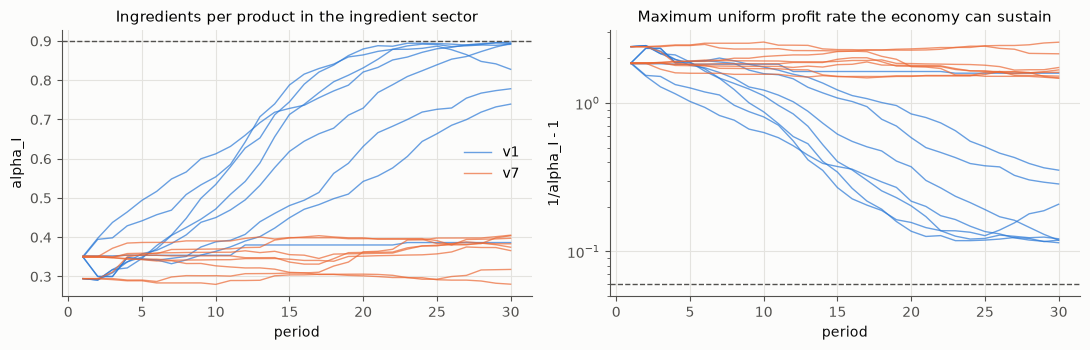

v1: 30 期目の alpha_I(seed ごと) [0.891 0.739 0.828 0.897 0.894 0.778 0.386 0.893]
v7: 30 期目の alpha_I(seed ごと) [0.383 0.404 0.366 0.397 0.28  0.318 0.375 0.405]
v1 の原料の分野の平均企業数(seed ごと) [8.7 8.  8.7 8.5 8.8 8.  1.  7.2]


In [43]:
t0 = time.time()
AP = {v: pmap(anatomy.alpha_I_path, [(dict(version=v), s, 30) for s in SEEDS[:8]]) for v in ('v1', 'v7')}
print(f'({time.time() - t0:.0f} 秒)')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, v in enumerate(('v1', 'v7')):
    for j, path in enumerate(AP[v]):
        ax[0].plot(range(1, len(path) + 1), path, color=PAL[i], lw=1, alpha=0.7, label=v if j == 0 else None)
        ax[1].plot(range(1, len(path) + 1), 1 / np.array(path) - 1, color=PAL[i], lw=1, alpha=0.7, label=v if j == 0 else None)
ax[0].axhline(0.9, color=INK2, ls='--', lw=1)
ax[0].set(xlabel='period', ylabel='alpha_I', title='Ingredients per product in the ingredient sector')
ax[1].axhline(0.06, color=INK2, ls='--', lw=1)
ax[1].set(xlabel='period', ylabel='1/alpha_I - 1', yscale='log', title='Maximum uniform profit rate the economy can sustain')
ax[0].legend(); plt.tight_layout(); plt.show()
for v in ('v1', 'v7'):
    print(f'{v}: 30 期目の alpha_I(seed ごと)', np.round([p[-1] for p in AP[v]], 3))
nI = [np.mean([r['nI'] for r in l if 'W' in r]) for l in LOGS['v1'][:8]]
print('v1 の原料の分野の平均企業数(seed ごと)', np.round(nI, 1))

v1 では、多くの seed で、原料の分野の $\alpha_I$ が 0.3 から 0.7〜0.9 まで上がる。0.9 近くまで上がると、原料一単位の最終需要を満たすのに、原料の分野は 10 単位近く作らなければならない(乗数 $1/(1 - \alpha_I)$)。経済が実現できる一様な利潤率の上限は、12% 前後まで下がる。作者が「市場利子率」とした 6% に近い。

上がり方は、seed によって違う。上がるのは、原料の分野に**新しい企業が何度も参入する**場合である。新しい企業が入るたびに、$\alpha$ が平均して 1 割近く大きくなるからだ。原料の分野がずっと 1 社のままの seed では、$\alpha_I$ はほとんど動かない。v7 では、企業数を 5 社前後に保つ項があるので参入が少なく、$\alpha_I$ は 0.3〜0.4 にとどまる。

これは、モデルの設計(優位性を長持ちさせる戦略ほど原料を多く使う)から来る、技術の「劣化」である。機械の高度化(労働の節約)と並んで、原料の使い方が悪くなっていくことも、モデルの長期の動きを左右している。第 9 章で、技術の変化と実質賃金の関係を、もう一度取り上げる。

### 7.7 Lean: 会計の誤りの形

7.2 節の三つの誤りのうち、二つを式で確かめる。持ち主ごとに利益を**足せば**、和は企業の利益の総和に等しい(元のコードの上書き `=` では、二社目以降の利益が消える)。残業の二重計上の余分は、ちょうど w(D − S) になる。

In [44]:
%%writefile -a micro_economy.lean
/-! ## 第 7 章 会計の三つの誤り

(1) 資本家の利益は、企業ごとの利益を持ち主ごとに「足す」。持ち主ごとに足した和は、企業の利益の総和に等しい
(上書きすると、二社目以降の利益が消える)。 -/
theorem owner_profit_sum {C O : Type*} [Fintype C] [Fintype O] [DecidableEq O] (owner : C → O) (π : C → ℝ) :
    ∑ o, ∑ c ∈ univ.filter (fun c => owner c = o), π c = ∑ c, π c :=
  Finset.sum_fiberwise univ owner π

/-- (3) 残業の二重計上: 企業は w·D を払うが、労働者は w·S + 2w(D − S) を受け取る(社会的負債が残業の割増を払う)。
余分は w(D − S)。 -/
theorem overtime_double_count (w S D : ℝ) : (w * S + 2 * w * (D - S)) - (w * D) = w * (D - S) := by ring

Appending to micro_economy.lean


## 第 8 章 何を最適化すべきだったか

第 6 章で、元のスコアの本当の最小点が経済の崩壊点であることを見た。では、「価格を最適化で決める」という発想そのものが間違っていたのか。そうではない。**何を最適化するか**を選べば、この発想は正しく働く。この章では、それを示す。

### 8.1 条件を数える

方程式で未知数を決めるには、未知数と同じ数の(独立な)式が要る。未知数が 4 つなら、式も 4 本。式が足りなければ、答えは一つに決まらない。式が多すぎれば(矛盾していれば)、答えはない。

元のモデルで、毎期決めたい未知数は、四つの価格 $(W, P_N, P_L, P_I)$ である(v7 では標準利益率 $s$ も加わって五つ)。それに対して、元のスコアが課していた条件を数えてみる。

| 版 | 等式として効いている条件 | 未知数 | 残りはどう決まるか |
|---|---|---|---|
| v1 | 労働の需給(1 本) | 4 | 「利益の総和を最大に」。これは条件ではなく、際限のない要求 → 崩壊点 |
| v2 | 労働の需給(1 本) | 4 | 同上(罰を変えたので、崩壊点がいつも最小とは限らない) |
| v7 | 最大利潤率が分野でそろう(2 本) | 5 | 第 9 章で見るように、残りの方向は決まらない |

財の市場の需給は、規則(需要に合わせて作る)でいつも合っているので、条件の数には入らない。だから、労働の需給の 1 本では、4 つの価格を決めるには 3 本足りない。v1 は、その足りない分を「利益の最大化」で埋めようとした。ところが、利益の最大化は「この値に合わせよ」という条件ではなく、「いくらでも大きく」という要求である。足りない式の代わりにはならず、価格を境界まで押しやった。

#### 式が足りないとき、現実はどう回っているのか

ここで、作者がこのモデルを作ったときの直感に触れておきたい。それは、おおよそ次のようなものだった。

> 変数の数に対して式の数がそろわなくても、現実の経済はそういう状態で回っている。だから、何か「戦術」(tactic)があるはずだ。戦術がないならないなりに、ある種のカオスが現れるのなら、それも現実を映しているのではないか。

「戦術」という言葉は、作者の 2011 年の最初の経済シミュレーションから来ている。そこでは、市場のルールを「外作用」、プレイヤーがルールの中で取れる行動を「内作用」すなわち「戦術」(tactics)と呼んで、はっきり分けていた。ルールは簡易で厳格に、戦術は自由に書く。これは、ゲーム理論でいう「ゲームの形式」と「戦略」の区別そのものである。

この直感は、半分は正しく、半分は区別が要る。

**正しい半分**: 式が足りないとき、答えは一つに決まらず、答えの**族**(たくさんの答えの集まり)になる。現実の経済にも、理論だけでは決まらないことはたくさんある。その族から一つを選ぶのは、歴史・慣習・行動の規則である。たとえば、企業は前の期の値段を基準に少しだけ変える(**価格の粘着性**)。皆が同じ目印に合わせる(**フォーカル・ポイント**)。過去にたまたま選ばれたものが続く(**経路依存**)。これらはまさに「戦術」と呼ぶにふさわしい。経済学ではこれを**均衡選択**の問題という。

**区別が要る半分**: v1 のカオスは、式が足りないことから来たのではなかった。崩壊点が最適になっていたことから来ていた。足りない式を、際限のない要求(利益の最大化)で埋めたのが原因である。これは現実を映すカオスではなく、スコアの作り方から来る「作りものの崩壊」である。

だから、進め方は二つある。

1. **式を足して、未知数の数とそろえる。** 経済学が「均衡の条件」として知っているものを使う(8.2〜8.3)。
2. **足りない分を、明示した戦術で埋める。** 「前の期の価格に一番近い答えを選ぶ」といった規則を、スコアにはっきり書き込む(第 9 章)。

どちらの場合も大事なのは、「いくらでも大きく」という要求をスコアに入れないことである。

### 8.2 均衡の残差: 労働の需給 + 利潤率の均等化

足りない 3 本の式として、何を使えばよいか。古典派の経済学(スミス、リカード)とマルクスは、こう考えた。

> 資本は、利潤率の高い分野に移り、低い分野から逃げる。その結果、長い目で見ると、**どの分野の利潤率も同じ水準にそろう**。

そろった利潤率を**一般的利潤率**、そのときの価格を**生産価格**という(スラッファ 1960 は、これを投入産出の形で厳密に書いた)。三つの分野の利潤率がそろって、ある水準 $\bar r$ になる、というのは 3 本の式である。労働の需給と合わせて、**4 本**。未知数の数とそろう。

そこで、スコアを次のように替える。

$$
\text{スコア}_\text{eq} = \left(\frac{D - S}{10}\right)^2 + \sum_{j \in \{N, L, I\}} \left(\frac{\rho_j - \bar r}{0.05}\right)^2 .
$$

$\rho_j$ は分野 $j$ 全体の利潤率((売上 − 費用) / 費用)、$\bar r = 0.06$ は作者が「市場利子率」とした値である。10 と 0.05 は、二つの項の大きさをそろえるための目盛りにすぎない。**スコアの最小値は 0 で、0 になるのはちょうど均衡のとき**である。「いくらでも大きく」という項はない。

作者の「バランス戦略」(分野の利潤率の**分散**を罰する)は、この第 2 項の不完全な形だったと言える。分散を罰すると、利潤率はそろうが、そろう**水準**が決まらない。水準まで決めるには、$\bar r$ との差を罰する必要がある。

規則(需要・参入・分担など)は v1 のまま、スコアだけをこれに替えて回す(`me_ref` の `score_kind='eq'`)。

(4 秒)
版           最適化の失敗  境界に張り付いた期  贅沢品の生産 0 の期  賃金が 100 を超えた seed   労働の需給のずれ   最終期の賃金(平均 ± sd)
v1(元のスコア)      5.9           12.6              14.5               2/16                  30.4             123.1 ± 274.3
均衡の残差          0.6            0.0               0.0               0/16                   0.8              25.8 ± 2.3
(回数は 30 期のうちの期数の、seed についての平均)


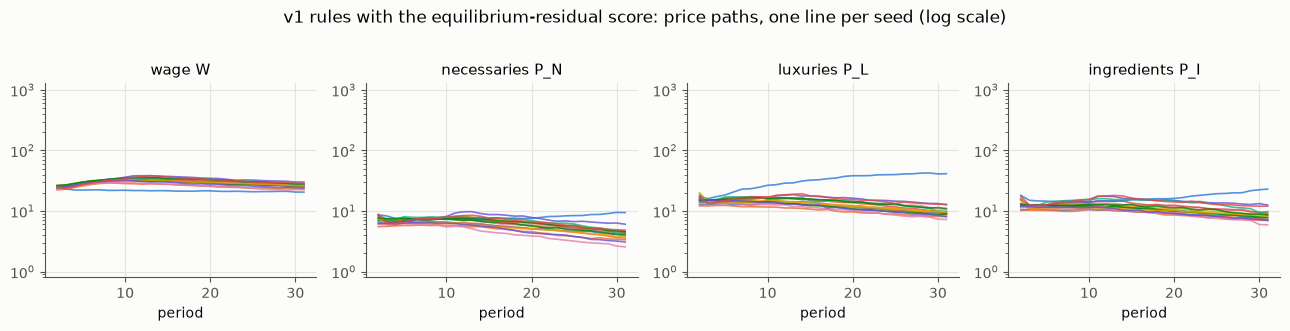

In [45]:
t0 = time.time()
LOGS['eq'] = pmap(anatomy.batch, [(dict(version='v1', score_kind='eq'), s, 30) for s in SEEDS])
print(f'({time.time() - t0:.0f} 秒)')
table({'v1(元のスコア)': LOGS['v1'], '均衡の残差': LOGS['eq']})
plot_paths(LOGS['eq'], 'v1 rules with the equilibrium-residual score: price paths, one line per seed (log scale)')

元のスコアと比べると、違いは歴然としている。境界への張り付きも、贅沢品の消失もなくなる。最適化の「失敗」もほとんどない。労働の需給のずれも小さい。seed による違い(最終期の賃金のばらつき)も、ずっと小さい。

#### 答えは一つに決まるか

第 6 章と同じく、ある一期で 20 の出発点から解いてみる。崩壊の隅のスコアも測る。

In [46]:
%%writefile -a anatomy.py
def multistart_detail(a):
    """(Params の dict, seed, k, 出発点の数, ずらし幅) → 多点出発の答えを、分野の利潤率と労働の需給のずれつきで返す。"""
    pdict, seed, k, n, spread = a
    e = state(pdict, seed, k)
    f = lambda x: e.calc(x)['score']
    x0 = e.initial_guess()
    rng = np.random.default_rng(seed)
    out = []
    for i in range(n):
        r = minimize(f, x0 * np.exp(rng.normal(0, spread, len(x0))), method='Nelder-Mead',
                     options=dict(maxiter=4000, xatol=1e-6, fatol=1e-9))
        st = e.calc(r.x)
        if np.isfinite(st['score']):
            out.append(dict(score=st['score'], x=r.x.tolist(), S=st['S'], gap=st['D'] - st['S'],
                            rates=[st['sector_rate'][s] for s in 'NLI']))
    cs = [f([1, 1000, L, 1000]) for L in (1, 10, 100, 500, 1000)]
    return dict(sols=sorted(out, key=lambda d: d['score']), corner=float(min(cs)))

Appending to anatomy.py


In [47]:
importlib.reload(anatomy)
MD = pmap(anatomy.multistart_detail, [(dict(version='v1', score_kind='eq'), s, k, 20, 0.3) for s, k in ((1, 4), (2, 14))])
for (s, k), r in zip(((1, 4), (2, 14)), MD):
    print(f'--- seed {s}、{k + 1} 期目。崩壊の隅のスコア: {r["corner"]:.0f}')
    good = [d for d in r['sols'] if d['score'] < 1e-2]
    print(f'残差 < 0.01 の答え: {len(good)} / {len(r["sols"])}')
    for d in r['sols'][:6]:
        print(f"  残差 {d['score']:9.2e}  (W, P_N, P_L, P_I) = {np.round(d['x'], 2)}  利潤率 {np.round(d['rates'], 4)}  需給のずれ {d['gap']:6.2f}  働く人 {d['S']:.0f}")
    if len(good) > 1:
        X = np.array([d['x'] for d in good])
        print(f'  残差 < 0.01 の答えどうしの価格の違い(最大): {np.max(X.max(0) / X.min(0) - 1):.1%}')

--- seed 1、5 期目。崩壊の隅のスコア: 4715
残差 < 0.01 の答え: 5 / 20
  残差  1.66e-04  (W, P_N, P_L, P_I) = [29.72  6.66 13.59 10.87]  利潤率 [0.0596 0.06   0.0596]  需給のずれ  -0.05  働く人 711
  残差  6.36e-04  (W, P_N, P_L, P_I) = [29.72  6.66 13.59 10.86]  利潤率 [0.0601 0.0601 0.0587]  需給のずれ   0.02  働く人 711
  残差  8.69e-04  (W, P_N, P_L, P_I) = [29.54  6.51 13.37 10.52]  利潤率 [0.059  0.06   0.0592]  需給のずれ  -0.12  働く人 709
  残差  1.33e-03  (W, P_N, P_L, P_I) = [29.7   6.67 13.59 10.89]  利潤率 [0.0613 0.06   0.0611]  需給のずれ   0.15  働く人 711
  残差  9.46e-03  (W, P_N, P_L, P_I) = [29.57  6.67 13.02 10.81]  利潤率 [0.059  0.0554 0.0591]  需給のずれ  -0.12  働く人 710
  残差  1.70e-02  (W, P_N, P_L, P_I) = [29.67  6.71 13.42 10.55]  利潤率 [0.0659 0.0605 0.0582]  需給のずれ  -0.42  働く人 711
  残差 < 0.01 の答えどうしの価格の違い(最大): 4.4%
--- seed 2、15 期目。崩壊の隅のスコア: 4053
残差 < 0.01 の答え: 4 / 20
  残差  6.06e-05  (W, P_N, P_L, P_I) = [30.85  5.7  12.48 10.66]  利潤率 [0.0602 0.06   0.0602]  需給のずれ   0.05  働く人 706
  残差  5.24e-04  (W, P_N, P_L, P_I) = [30.76  5.64 12.44 10.6

- 最良の答えの残差は、ほぼ 0 である。三つの分野の利潤率はどれも 0.060、労働の需給のずれもほぼ 0。
- 崩壊の隅のスコアは数千で、ずっと高い。退化した最小点はない。
- 残差がほぼ 0 の答えは、互いに数 % 以内に集まる。働く人の数は整数なので、その一つ一つの値ごとに、少しずつ違う答えがある。だから「数学的にきっかり一つ」ではないが、**経済的には一つに決まっている**と言ってよい。
- 残差が 0 にならずに止まった出発点もある。これは本物の極小ではない。労働の供給の階段(2.4)のところで、Nelder–Mead 法が止まってしまうためで、解き方の問題である。

一つ、残った問題がある。上の経路の図では見えないが、この設定では企業数が各分野 10 社前後に飽和する。価格が毎期、利潤率を $\bar r$ に合わせるので、効率のよい新しい企業は、いつも参入の基準(6%)を超えるからである。参入と退出の規則を、均衡の条件と整合させることは、続くノートの課題として残す(企業数を連続量にする話につながる)。

In [48]:
nE = np.array([[np.mean([r[k] for r in l if 'W' in r][-10:]) for k in ('nN', 'nL', 'nI')] for l in LOGS['eq']])
print('均衡の残差の設定での、最後の 10 期の平均企業数(seed の平均) N/L/I =', np.round(nE.mean(0), 1))

均衡の残差の設定での、最後の 10 期の平均企業数(seed の平均) N/L/I = [ 9.9  9.9 10. ]


### 8.3 $\bar r$ は経済の中では決まらない

8.2 では、$\bar r$ を 0.06 と外から与えた。では、$\bar r$ を変えると、何が変わるか。参入の基準も $\bar r$ にそろえて回す。

(4 秒)
r̄ = 0.00: 実質賃金 W/P_N =  5.59   働く人   722   贅沢品の生産   739
r̄ = 0.03: 実質賃金 W/P_N =  5.51   働く人   699   贅沢品の生産   719
r̄ = 0.06: 実質賃金 W/P_N =  5.29   働く人   696   贅沢品の生産   712
r̄ = 0.12: 実質賃金 W/P_N =  4.42   働く人   682   贅沢品の生産   606
r̄ = 0.20: 実質賃金 W/P_N =  3.86   働く人   594   贅沢品の生産   291


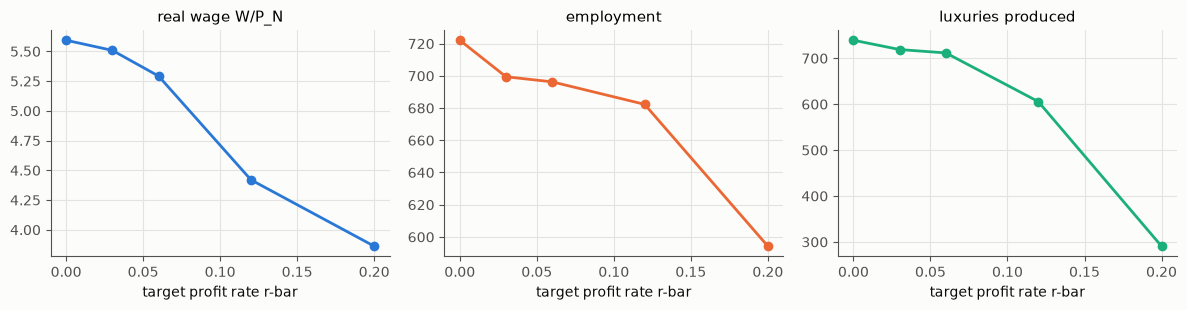

In [49]:
RB = (0.0, 0.03, 0.06, 0.12, 0.2)
n_r = 3 if FAST else 6
t0 = time.time()
RL = pmap(anatomy.batch, [(dict(version='v1', score_kind='eq', eq_target_rate=r, standard_profit_rate=r), s, 20)
                          for r in RB for s in range(1, n_r + 1)])
print(f'({time.time() - t0:.0f} 秒)')
rows = []
for i, r in enumerate(RB):
    logs = RL[i * n_r:(i + 1) * n_r]
    last = [[x for x in l if 'W' in x][-5:] for l in logs]
    m = lambda k: np.mean([np.mean([x[k] for x in L]) for L in last])
    rw = np.mean([np.mean([x['W'] / x['N'] for x in L]) for L in last])
    rows.append((r, rw, m('supply'), m('prodL')))
    print(f'r̄ = {r:4.2f}: 実質賃金 W/P_N = {rw:5.2f}   働く人 {m("supply"):5.0f}   贅沢品の生産 {m("prodL"):5.0f}')
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for j, (lab, col) in enumerate((('real wage W/P_N', 1), ('employment', 2), ('luxuries produced', 3))):
    ax[j].plot([r[0] for r in rows], [r[col] for r in rows], marker='o', color=PAL[j])
    ax[j].set(xlabel='target profit rate r-bar', title=lab)
plt.tight_layout(); plt.show()

$\bar r$ を上げると、実質賃金(賃金で買える必需品の量)が下がり、働く人も、贅沢品の生産も減る。利潤の取り分が増えれば、賃金の取り分が減る。これはスラッファの**賃金と利潤のトレードオフ**(賃金−利潤曲線)である。

大事なのは、**$\bar r$ が経済の中では決まらない**ことである。4 本の式は、$\bar r$ を与えれば価格を決める。しかし $\bar r$ そのものを決める式は、どこにもない。古典派の経済学で言う「分配の一つの自由度」である。スラッファ自身は、利潤率は貨幣の利子率によって外から決まるのかもしれない、と示唆している。

ここで、二つのことがつながる。

- **v7 の標準利益率 $s$**: v7 は、標準利益率を最適化の変数にした。これは、経済の中では決まらない量を、スコアの都合で動かしたことになる。第 9 章で見るように、$s$ は 0.4〜0.5 あたりに漂う。
- **信用のモデル**: 利潤率の水準が、金利(と信用の状態)で外から決まるのなら、このモデルは、信用創造のモデル(別のノートで扱った信用循環モデル)と、ここでつながる。

### 8.4 全体最適と力関係: Negishi の方法

ここまでは、利潤率という古典派の道具を使った。最後に、作者のもう一つの考え方を検討したい。作者は、経済をシミュレーションする最適化について、おおよそ次のように考えていた。

> 経済には複数のプレイヤーがいて、それぞれ利益を出そうとしている。自分以外も最適化しようとしているので、自分の最適化しようとする力と他人の力がせめぎあう。プログラムで両者を同時に最適化するには、両者の和などを最適化することになる。だから、個々の利益の追求を同時に行うには、究極的には**全体の最適化**でとらえるしかない。誰が得をし、誰が損をするかは、ランダム性を含む**力関係**で決まる。

この考え方は、経済学の **Negishi の定理**(根岸隆、1960)と、ほぼ同じ形をしている。

> 競争均衡は、各人の効用に重み $\lambda_i$ をつけた和 $\sum_i \lambda_i u_i$ を最大にする配分として表せる。その重みは、**各人の予算がちょうど釣り合うように**決まる。

重み $\lambda_i$ が「力関係」に当たる。ただし、力関係は自由に選べるのではなく、**予算の釣り合い**で決まる。これを、小さな模型で確かめる。

- 財は二つ(必需品 N、贅沢品 L)、人は二人(労働 $H$ を持つ労働者と、資本 $K$ を持つ資本家)。
- 生産は、労働と資本から、収穫一定(コブ=ダグラス型)で行う。
- 効用は、必需品に生存水準がある形(Stone–Geary 型)。

重み $\lambda_w$(労働者)と $1 - \lambda_w$(資本家)を与えて、計画者が重みつきの効用の和を最大にする。そのときの価格(限界的な交換の比率)で、労働者の**予算のずれ** $B(\lambda)$ = 支出 − 所得 を測る。

In [50]:
%%writefile toy_negishi.py
"""toy_negishi.py -- 「全体最適 + 力関係」を Negishi の方法で確かめる最小の模型

財: 必需品 N、贅沢品 L。生産要素: 労働(労働者が H 持つ)、資本(資本家が K 持つ)。
生産: y_j = A_j K_j^a_j L_j^(1-a_j)(収穫一定)。
効用: u_i = β_i log(c_iN − n̄_i) + (1−β_i) log c_iL(必需品には生存水準 n̄ がある)。

(1) 重み λ = (λ_w, 1−λ_w) を与え、計画者が λ_w u_w + λ_c u_c を最大化する(凸計画)。
    価格は限界条件から出る(p_N = 1)。
(2) その価格で、労働者の支出 − 所得 = 予算のずれ B(λ) を測る。
    B ≠ 0 なら、その配分を市場で実現するには、誰かが B だけ移転しなければならない(= 社会的負債)。
(3) B(λ*) = 0 となる λ* を探す(Negishi の重み)。
(4) 別に、競争均衡を「超過需要 = 0」の連立方程式として解き、(3) と一致するか確かめる。
"""
import numpy as np
from scipy.optimize import minimize, brentq, fsolve

H, K = 100.0, 50.0
A = {'N': 1.0, 'L': 1.0}
a = {'N': 0.3, 'L': 0.5}            # 資本分配率(贅沢品のほうが資本集約的)
beta = {'w': 0.6, 'c': 0.3}          # 必需品への選好
nbar = {'w': 20.0, 'c': 5.0}         # 生存水準


def output(j, Kj, Lj):
    return A[j] * Kj ** a[j] * Lj ** (1 - a[j])


def planner(lam_w):
    """変数 z = (K_N, L_N, c_wN, c_wL)。残りは資本家へ。"""
    lam = {'w': lam_w, 'c': 1 - lam_w}
    def unpack(z):
        KN, LN, cwN, cwL = z
        yN, yL = output('N', KN, LN), output('L', K - KN, H - LN)
        return dict(KN=KN, LN=LN, yN=yN, yL=yL, c={'w': (cwN, cwL), 'c': (yN - cwN, yL - cwL)})
    def negW(z):
        s = unpack(z); v = 0.0
        for i in ('w', 'c'):
            cN, cL = s['c'][i]
            if cN <= nbar[i] or cL <= 0: return 1e10
            v += lam[i] * (beta[i] * np.log(cN - nbar[i]) + (1 - beta[i]) * np.log(cL))
        return -v
    best = None
    for z0 in ([K / 2, H / 2, 30, 10], [K / 3, H * 0.6, 40, 15], [K * 0.6, H * 0.7, 35, 5]):
        r = minimize(negW, z0, method='Nelder-Mead', options=dict(xatol=1e-10, fatol=1e-12, maxiter=20000))
        if best is None or r.fun < best.fun: best = r
    s = unpack(best.x)
    # 価格(p_N = 1): 必需品部門の限界生産力が賃金・利子、限界変形率が p_L
    KN, LN = s['KN'], s['LN']
    w = (1 - a['N']) * s['yN'] / LN
    r_ = a['N'] * s['yN'] / KN
    pL = w / ((1 - a['L']) * s['yL'] / (H - LN))
    cwN, cwL = s['c']['w']
    B = cwN + pL * cwL - w * H                 # 労働者の予算のずれ(支出 − 所得)
    return dict(lam_w=lam_w, w=w, r=r_, pL=pL, B=B, s=s)


def competitive():
    """競争均衡: 価格 (w, r, p_L)、p_N = 1。家計は予算のもとで効用最大化、企業は費用最小化で利潤 0。"""
    def unit_cost(j, w, r):    # コブ=ダグラスの単位費用
        return (r / a[j]) ** a[j] * (w / (1 - a[j])) ** (1 - a[j]) / A[j]
    def excess(v):
        w, r, pL = np.exp(v)
        e1 = unit_cost('N', w, r) - 1.0          # 必需品の利潤 0
        e2 = unit_cost('L', w, r) - pL           # 贅沢品の利潤 0
        inc = {'w': w * H, 'c': r * K}
        dN = sum(nbar[i] + beta[i] * (inc[i] - nbar[i]) for i in inc)          # Stone–Geary の需要
        dL = sum((1 - beta[i]) * (inc[i] - nbar[i]) / pL for i in inc)
        # 要素需要(シェパードの補題)と、要素市場の需給
        LN = (1 - a['N']) * unit_cost('N', w, r) / w * dN
        LL = (1 - a['L']) * unit_cost('L', w, r) / w * dL
        return [e1, e2, (LN + LL - H) / H]
    v = fsolve(excess, np.log([1.0, 1.0, 1.0]))
    w, r, pL = np.exp(v)
    inc_w = w * H
    cwN = nbar['w'] + beta['w'] * (inc_w - nbar['w'])
    cwL = (1 - beta['w']) * (inc_w - nbar['w']) / pL
    return dict(w=w, r=r, pL=pL, cw=(cwN, cwL), resid=np.max(np.abs(excess(v))))

Overwriting toy_negishi.py


予算のずれが 0 になる重み λ_w* = 0.549269
  計画者の解: 賃金 0.514316  資本の利子 0.615857  贅沢品の価格 1.125602  労働者の消費 [38.858955 11.169696]
  競争均衡  : 賃金 0.514316  資本の利子 0.615857  贅沢品の価格 1.125602  労働者の消費 [38.858955 11.169695]  (残差 8.9e-16)
  重みの比 λ_w*/λ_c* = 1.219、所得の比 wH/rK = 1.670


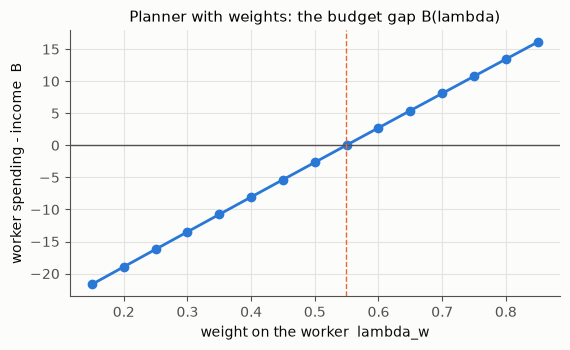

In [51]:
import toy_negishi
importlib.reload(toy_negishi)
from scipy.optimize import brentq
lams = np.linspace(0.15, 0.85, 15)
Bs = [toy_negishi.planner(l)['B'] for l in lams]
lam_star = brentq(lambda l: toy_negishi.planner(l)['B'], 0.2, 0.8, xtol=1e-10)
ps, ce = toy_negishi.planner(lam_star), toy_negishi.competitive()
print(f'予算のずれが 0 になる重み λ_w* = {lam_star:.6f}')
print(f"  計画者の解: 賃金 {ps['w']:.6f}  資本の利子 {ps['r']:.6f}  贅沢品の価格 {ps['pL']:.6f}  労働者の消費 {np.round(ps['s']['c']['w'], 6)}")
print(f"  競争均衡  : 賃金 {ce['w']:.6f}  資本の利子 {ce['r']:.6f}  贅沢品の価格 {ce['pL']:.6f}  労働者の消費 {np.round(ce['cw'], 6)}  (残差 {ce['resid']:.1e})")
print(f"  重みの比 λ_w*/λ_c* = {lam_star / (1 - lam_star):.3f}、所得の比 wH/rK = {ce['w'] * toy_negishi.H / (ce['r'] * toy_negishi.K):.3f}")
fig, ax = plt.subplots(figsize=(5.8, 3.6))
ax.plot(lams, Bs, marker='o', color=PAL[0])
ax.axhline(0, color=INK2, lw=1); ax.axvline(lam_star, color=PAL[1], ls='--', lw=1)
ax.set(xlabel='weight on the worker  lambda_w', ylabel='worker spending - income  B',
       title='Planner with weights: the budget gap B(lambda)')
plt.tight_layout(); plt.show()

- 重みを変えると、計画者の答え(誰がどれだけ消費するか)が変わる。重みは、たしかに「力関係」を表している。
- ところが、ほとんどの重みでは、労働者の予算が釣り合わない($B \ne 0$)。$B > 0$ なら、労働者は稼ぎ以上に消費している。その配分を市場で実現するには、誰かが $B$ だけ労働者に移転しなければならない。**この移転こそが、元のモデルの「社会的負債」に当たる。**
- 予算のずれが 0 になる重み $\lambda_w^*$ で、計画者の答えは、別に解いた競争均衡と、価格も消費も 6 桁まで一致する。
- 重みの比は、所得の比とは違う。重みは所得そのものではなく、「所得一単位がその人にもたらす効用」の逆数である。

まとめると、作者の「全体最適 + 力関係」は、**力関係(重み)を予算の釣り合いで決めれば、正確に競争均衡を表す**。元のモデルは、重みを「利益の単純な和」に固定し、予算のずれを社会的負債に吸わせていた。社会的負債には制約がない(第 7 章)。だから、どんな配分でも「実現」できてしまい、スコアの都合で崩壊点まで行けてしまった。

#### 命令的前提と環境的前提

作者は、スコアに入れる項を「命令的前提」(そうなるべきこと。たとえば「利益は大きいほうがよい」)、モデルの規則を「環境的前提」(世界がそうなっていること。たとえば「コストが低いほうが利益が大きくなる」)と呼び分けていた。そして、「コストは低いほうがよい」をスコアに入れると、利益の項と重なって結果が悪くなるので入れない、と判断していた。

この判断は正しい。同じことを二重に数えると、その方向に過剰に押しやられる。この章の結論は、その判断をもう一歩進めたものになる。**スコアに入れる命令的前提は、「この値に合わせよ」という条件(残差が 0 になるもの)にすべきで、「いくらでも大きく」という要求にしてはいけない。** 要求を入れると、環境的前提の穴(ここでは、社会的負債に制約がないこと)を通って、スコアが現実にはありえない点に行ってしまう。

### 8.5 log 戦略を読む

作者は、その3 で「log 戦略」を試した。利益率に log に似た関数をかけて足す、というものである。狙いは、急な価格の上昇に対して、需要が「弾力的に」減るような効果を出すことだった。その結果、極端な振る舞いは減ったが、思ったほどバランスは取れなかった。その理由を、数値で調べる。

v5(その3 の版)は、v1 の規則に、スコア $0.01(D-S)^2 - \operatorname{mean}_j T(\max_k \rho_k)$ をつけたものである。$T$ は変換で、恒等(none)、log1.1、exp、hybrid を比べる。

(21 秒)
変換      最適化の失敗  境界  贅沢品 0   分野の最大利潤率のばらつき(sd)  赤字の分野がある期  崩壊の隅が低い状態
none        0.31       3.9    4.7            0.725                       35%              0 / 8
log1.1      0.38       0.0    3.6            0.454                       44%              0 / 8
exp         0.12       0.0    1.3            0.256                       15%              0 / 8
hybrid      0.00       0.0    0.4            0.219                       10%              0 / 8


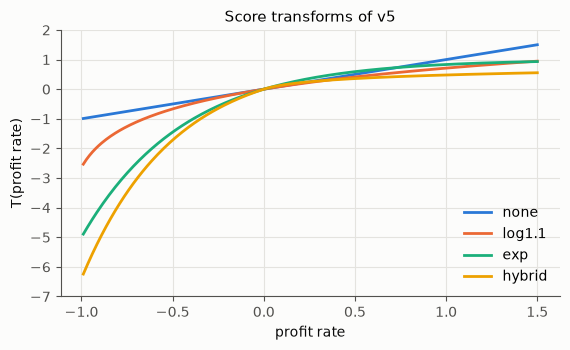

In [52]:
TR = ('none', 'log1.1', 'exp', 'hybrid')
t0 = time.time()
V5 = {t: pmap(anatomy.batch, [(dict(version='v5', score_transform=t), s, 30) for s in SEEDS]) for t in TR}
CR5 = {t: pmap(anatomy.corner, [(dict(version='v5', score_transform=t), s, k) for s in range(1, 5) for k in (4, 14)]) for t in TR}
print(f'({time.time() - t0:.0f} 秒)')
print('変換      最適化の失敗  境界  贅沢品 0   分野の最大利潤率のばらつき(sd)  赤字の分野がある期  崩壊の隅が低い状態')
for t in TR:
    S = [anatomy.summarize(l) for l in V5[t]]
    mr = [np.array([[r[f'maxrate_{s}'] for s in 'NLI'] for r in l if 'W' in r][5:]) for l in V5[t]]
    sd = np.mean([m.std(1).mean() for m in mr]); neg = np.mean([(m < 0).any(1).mean() for m in mr])
    lower = sum(c['corner'] < c['chosen'] for c in CR5[t] if c)
    print(f"{t:8s}  {np.mean([s['fail'] for s in S]):6.2f}     {np.mean([s['bound'] for s in S]):5.1f}  {np.mean([s['zeroL'] for s in S]):5.1f}"
          f"           {sd:6.3f}                     {neg:5.0%}              {lower} / {len(CR5[t])}")
xx = np.linspace(-0.99, 1.5, 300)
fig, ax = plt.subplots(figsize=(5.8, 3.6))
for i, t in enumerate(TR):
    ax.plot(xx, [me_ref._transform(t, v) for v in xx], color=PAL[i], label=t)
ax.set(ylim=(-7, 2), xlabel='profit rate', ylabel='T(profit rate)', title='Score transforms of v5')
ax.legend(); plt.tight_layout(); plt.show()

まず、v5 では、変換がない(none)場合でも、崩壊の隅は最小ではない。v5 は、利益の「額」の代わりに利益「率」を使い、労働の項の重みを決め直した。崩壊点を消したのは、この切り替えであって、log ではない。

変換の良し悪しは、hybrid > exp > log1.1 > none の順である。これは、グラフで見ると、**赤字の側(利潤率 < 0)の落ち込みの急さ**の順と一致する。利潤率 −1 での値は、log1.1 が約 −2.6、exp が −5、hybrid が約 −6.4。効いているのは、利益の側の log ではなく、「損失を強く嫌う」形のほうである。

#### log は、何をそろえるのか

では、log は何をするのか。簡単な問題で考える。利益の総額 $\Pi$ が決まっていて、それを費用の規模 $c_j$ の違う三つの分野に分けるとする($\sum_j c_j \rho_j = \Pi$)。$\sum_j \log(1 + \rho_j)$ を最大にする分け方は、ラグランジュの乗数 $\lambda$ を使って、

$$
\frac{1}{1 + \rho_j} = \lambda\, c_j
\quad\Longrightarrow\quad
c_j (1 + \rho_j) = \frac{1}{\lambda}\ \ (\text{全分野で同じ})
$$

となる。$c_j(1 + \rho_j)$ は、その分野の**売上**である。log が等しくするのは、利潤率ではなく、**売上**なのである。規模の小さい分野には高い利潤率が、大きい分野には低い(赤字の)利潤率が割り当てられる。数値で確かめる。

In [53]:
%%writefile toy_log.py
"""toy_log.py -- log 戦略は何をそろえるのか、と、log が正しく市場を表す場合(アイゼンバーグ=ゲール)

(1) 一定の利益の総額 Π を、費用の規模 c_s の違う三分野に分ける。
    max Σ T(r_s)  s.t.  Σ c_s r_s = Π,  r_s ≥ −1
    T の選び方で、何がそろうかを見る。
    - 恒等(利益率の和): 角の解(費用の小さい分野に全部)。
    - 分散の罰(その2): 利益率 r がそろう。
    - log(1+r): 1/(1+r_s) = λ c_s より、c_s(1+r_s) = 売上がそろう(利益率はそろわない)。
    - hybrid / exp(その3): 数値で。
(2) フィッシャー市場: 予算 m_i の買い手が、線形の効用 u_i = Σ_j a_ij x_ij で、供給 1 の財を買う。
    max Σ_i m_i log u_i  s.t.  Σ_i x_ij ≤ 1 の解の双対変数が均衡価格になる(Eisenberg & Gale 1959)。
    価格を出し、「各財は売り切れる」「各人は予算を使い切る」「各人は効用/価格の最も高い財だけを買う」を確かめる。
"""
import numpy as np
from scipy.optimize import minimize

T = {
    'identity': lambda r: r,
    'log': lambda r: np.log(1 + r),
    'log1.1': lambda r: -1.1 * np.log(1.1) + 1.1 * np.log(r + 1.1),
    'exp': lambda r: -np.exp(-np.log(6) * r) + 1,
    'hybrid': lambda r: np.where(r >= 0, 0.2 * np.log(np.maximum(r, 0) + 0.1) - 0.2 * np.log(0.1), -np.exp(-2 * r) + 1),
}


def allocate(name, c, Pi, var_pen=None):
    c = np.asarray(c, float)
    if var_pen is not None:
        obj = lambda r: -(np.mean(r) - var_pen * np.var(r))
    else:
        obj = lambda r: -np.sum(T[name](r))
    cons = [{'type': 'eq', 'fun': lambda r: c @ r - Pi}]
    best = None
    for r0 in (np.full(3, Pi / c.sum()), np.array([0.5, -0.5, 0.1]), np.array([-0.5, 0.5, 0.3])):
        res = minimize(obj, r0, method='SLSQP', bounds=[(-0.999, 50)] * 3, constraints=cons,
                       options=dict(ftol=1e-14, maxiter=2000))
        if best is None or res.fun < best.fun: best = res
    return best.x


def fisher(m, a):
    m, a = np.asarray(m, float), np.asarray(a, float)
    nb, ng = a.shape
    def negobj(z):
        X = z.reshape(nb, ng); u = (a * X).sum(1)
        return -np.sum(m * np.log(np.maximum(u, 1e-300)))
    cons = [{'type': 'ineq', 'fun': (lambda z, j=j: 1 - z.reshape(nb, ng)[:, j].sum())} for j in range(ng)]
    res = minimize(negobj, np.full(nb * ng, 1.0 / nb), method='SLSQP', bounds=[(0, 1)] * (nb * ng),
                   constraints=cons, options=dict(ftol=1e-15, maxiter=5000))
    X = res.x.reshape(nb, ng); u = (a * X).sum(1)
    p = np.max(m[:, None] * a / u[:, None], axis=0)      # KKT: p_j = max_i m_i a_ij / u_i
    return X, u, p

Overwriting toy_log.py


In [54]:
import toy_log
importlib.reload(toy_log)
c = np.array([17000.0, 4000.0, 15000.0]); Pi = 0.1 * c.sum()
print(f'利益の総額 {Pi:.0f} を、費用 c = {c} の三分野(必需品・贅沢品・原料に近い比)に分ける')
for name in ('identity', 'log', 'log1.1', 'exp', 'hybrid'):
    r = toy_log.allocate(name, c, Pi)
    print(f"  {name:8s}: 利潤率 {np.round(r, 3)}   売上 c(1 + 利潤率) {np.round(c * (1 + r), 0)}")
r = toy_log.allocate(None, c, Pi, var_pen=100.0)
print(f"  分散の罰 : 利潤率 {np.round(r, 3)}   売上 c(1 + 利潤率) {np.round(c * (1 + r), 0)}")

利益の総額 3600 を、費用 c = [17000.  4000. 15000.] の三分野(必需品・贅沢品・原料に近い比)に分ける
  identity: 利潤率 [-0.999  8.892 -0.999]   売上 c(1 + 利潤率) [1.7000e+01 3.9568e+04 1.5000e+01]
  log     : 利潤率 [-0.224  2.3   -0.12 ]   売上 c(1 + 利潤率) [13200. 13200. 13200.]
  log1.1  : 利潤率 [-0.253  2.5   -0.14 ]   売上 c(1 + 利潤率) [12700. 14000. 12900.]
  exp     : 利潤率 [-0.019  0.789  0.051]   売上 c(1 + 利潤率) [16680.  7155. 15765.]
  hybrid  : 利潤率 [0.041 0.5   0.06 ]   売上 c(1 + 利潤率) [17700.  6000. 15900.]
  分散の罰 : 利潤率 [0.099 0.104 0.1  ]   売上 c(1 + 利潤率) [18684.  4418. 16498.]


log では売上がちょうど 13200 ずつにそろい、利潤率は −22%、+230%、−12% とばらばらになる。分散の罰(その2 のバランス戦略)では、利潤率がそろう。hybrid と exp は、その中間である。v5 の log1.1 で「赤字の分野がある期」が多かったのは、このためである。

#### log が正しく働く場所: アイゼンバーグ=ゲール

それでも、「log をかけると、ちょうどよい弾力性が出る」という直感は、的外れではない。log をかける**相手**が違っていたのである。

Eisenberg と Gale(1959)は、次のことを示した。予算 $m_i$ を持つ買い手が、線形の効用 $u_i = \sum_j a_{ij} x_{ij}$ で財を買う市場(フィッシャー市場)を考える。このとき、

$$
\max \sum_i m_i \log u_i \quad \text{(各財の量は 1 まで)}
$$

という最適化の答えは、**そのまま市場の均衡**になる。均衡価格は、この最適化の制約(各財は 1 まで)のラグランジュ乗数として出てくる。消費者の**効用**の log を、**予算**の重みで足すのである。小さな市場で確かめる。

In [55]:
m = np.array([10.0, 5.0, 2.0])
a = np.array([[3.0, 1.0, 1.0], [1.0, 2.0, 1.0], [1.0, 1.0, 4.0]])
X, u, p = toy_log.fisher(m, a)
print('価格 p =', np.round(p, 6), '  合計', round(p.sum(), 6), '= 予算の合計', m.sum())
print('各財の売れた量 =', np.round(X.sum(0), 6))
print('各人の支出 =', np.round((X * p).sum(1), 6), '  予算 =', m)
for i in range(3):
    bang = a[i] / p; bought = X[i] > 1e-6
    print(f'買い手 {i}: 効用/価格 = {np.round(bang, 4)}  買った財 {np.where(bought)[0].tolist()}  '
          f'買ったのは効用/価格が最大の財だけか: {np.allclose(bang[bought], bang.max(), rtol=1e-4)}')

価格 p = [9. 5. 3.]   合計 17.0 = 予算の合計 17.0
各財の売れた量 = [1. 1. 1.]
各人の支出 = [10.  5.  2.]   予算 = [10.  5.  2.]
買い手 0: 効用/価格 = [0.3333 0.2    0.3333]  買った財 [0, 2]  買ったのは効用/価格が最大の財だけか: True
買い手 1: 効用/価格 = [0.1111 0.4    0.3333]  買った財 [1]  買ったのは効用/価格が最大の財だけか: True
買い手 2: 効用/価格 = [0.1111 0.2    1.3333]  買った財 [2]  買ったのは効用/価格が最大の財だけか: True


全部の財がちょうど売り切れ、各人はちょうど予算を使い切り、各人は「価格あたりの効用」が一番高い財だけを買っている。これは市場の均衡の条件そのものである。

ここでも、予算が重みになっている(8.4 の Negishi の重みと同じ役割)。log をかけるべきだったのは、企業の利益率ではなく、**予算で重みをつけた、消費者の効用**だった。そうすれば、最適化の答えが、そのまま市場の均衡になる。

### 8.6 この章のまとめ

1. 未知数の数と、等式の条件の数をそろえる。足りない分を「いくらでも大きく」という要求で埋めてはいけない。
2. 古典派の「利潤率の均等化」を条件にすると、同じ規則のままで、崩壊点のない、ほぼ一つに決まる答えが出る。作者の「バランス戦略」は、その不完全な形だった。
3. 利潤率の水準 $\bar r$ は経済の中では決まらず、分配を左右する。外から(たとえば金利として)与える必要がある。
4. 「全体最適 + 力関係」は、力関係(重み)を予算の釣り合いで決めれば、競争均衡を正しく表す(Negishi)。予算のずれは移転であり、それが社会的負債に当たる。
5. log は、企業の利益率にかけると売上をそろえてしまう。予算で重みをつけた消費者の効用にかければ、市場の均衡そのものになる(アイゼンバーグ=ゲール)。

### 8.7 Lean: 均衡の残差と、スラッファの取り換え

8.2 節の「均衡の残差の二乗和を最小にする」が、均衡を解くことと同じである理由(二乗和が 0 になるのは、すべての条件が満たされるときに限る)と、8.3 節の賃金と利潤の取り換え(一財の生産価格 p = (1 + r)(w l + p a) では、実質賃金 w/p は r の減る関数)を、Lean で証明する。

In [56]:
%%writefile -a micro_economy.lean
/-! ## 第 8 章 均衡の残差と、スラッファの取り換え

均衡の条件の残差の二乗和が 0 になるのは、すべての条件が満たされるとき、そのときに限る。
だから、二乗和の最小化(最小値 0)は、均衡を解くことと同じになる。 -/
theorem residual_sumsq_zero_iff {ι : Type*} (s : Finset ι) (r : ι → ℝ) :
    ∑ i ∈ s, r i ^ 2 = 0 ↔ ∀ i ∈ s, r i = 0 := by
  rw [Finset.sum_eq_zero_iff_of_nonneg (fun i _ => sq_nonneg (r i))]
  simp

/-- 一財の生産価格 p = (1 + r)(w l + p a) から、実質賃金 w/p = (1 − (1 + r) a) / ((1 + r) l)。 -/
theorem sraffa_real_wage {p w l a r : ℝ} (hp : p ≠ 0) (hl : l ≠ 0) (hr : 1 + r ≠ 0)
    (h : p = (1 + r) * (w * l + p * a)) : w / p = (1 - (1 + r) * a) / ((1 + r) * l) := by
  rw [div_eq_div_iff hp (mul_ne_zero hr hl)]
  linear_combination (-1 : ℝ) * h

/-- 賃金と利潤の取り換え: 標準の利潤率 r が高いほど、実質賃金は低い(l > 0)。 -/
theorem sraffa_tradeoff {l a r₁ r₂ : ℝ} (hl : 0 < l) (h0 : 0 < 1 + r₁) (h12 : r₁ ≤ r₂) :
    (1 - (1 + r₂) * a) / ((1 + r₂) * l) ≤ (1 - (1 + r₁) * a) / ((1 + r₁) * l) := by
  have h2 : 0 < 1 + r₂ := by linarith
  rw [div_le_div_iff₀ (mul_pos h2 hl) (mul_pos h0 hl)]
  nlinarith [mul_pos hl hl, mul_pos h0 h2]

Appending to micro_economy.lean


## 第 9 章 v7 の「大改良」を読む

2020 年の v7 は、それまでの工夫を統合した版である(2.9 のスコアを参照)。第 4 章の初めに見たとおり、v7 は 30〜40 期回しても崩壊せず、各分野の企業数も 5 社前後に落ち着く。この章では、v7 のスコアを、第 5・6 章と同じ道具で解剖する。

以下では、第 7 章の三つの誤りを直した設定を主に使う(元の会計の設定とも比べる)。

### 9.1 v7 には、崩壊点の最小がない

同じ一期のスコアを、四つのやり方で最小にしてみる。

- 元のやり方(前の期の価格から Nelder–Mead)
- 20 の出発点からの Nelder–Mead の最良
- dual annealing(大域的な探索。その5 で作者が試したもの)を、価格の範囲 [1, 100] と [1, 1000] で

In [57]:
%%writefile -a anatomy.py
from scipy.optimize import dual_annealing
V7_PARTS = ('zero_worker', 'social_debt', 'labor', 'variance', 'companies', 'profit_rate')


def v7_compare(a):
    """(Params の dict, seed, k) → 同じ一期の v7 のスコアを、四つのやり方で最小にした答え。"""
    pdict, seed, k = a
    e = state(pdict, seed, k)
    f = lambda x: e.calc(x)['score']
    def desc(x):
        st = e.calc(x)
        return dict(score=st['score'], x=list(map(float, x)), parts={p: float(st['parts'][p]) for p in V7_PARTS},
                    gap=st['D'] - st['S'], dsd=st['sd'] - e.prev_sd, n=[len(st['comps'][s]) for s in 'NLI'])
    out = dict(orig=desc(chosen(e).x))
    x0 = e.initial_guess(); rng = np.random.default_rng(seed); best = None
    for i in range(20):
        xi = np.r_[x0[:4] * np.exp(rng.normal(0, 0.3, 4)), rng.uniform(0, 1)]
        r = minimize(f, xi, method='Nelder-Mead')
        if np.isfinite(r.fun) and (best is None or r.fun < best.fun):
            best = r
    out['multi'] = desc(best.x)
    for name, ub in (('da100', 100), ('da1000', 1000)):
        out[name] = desc(dual_annealing(f, [(1, ub)] * 4 + [(0, 1)], seed=seed, maxiter=300).x)
    return out


def v7_slice(a):
    """(Params の dict, seed, k, 価格の番号, 点の数) → 選ばれた点のまわりで一つの価格を動かしたときの、v7 のスコアの各項。"""
    pdict, seed, k, j, npts = a
    e = state(pdict, seed, k)
    r = chosen(e)
    rows = []
    for v in np.geomspace(r.x[j] / 3, r.x[j] * 3, npts):
        x = r.x.copy(); x[j] = v
        st = e.calc(x)
        if np.isfinite(st['score']):
            rows.append(dict(value=v, score=st['score'], dsd=st['sd'] - e.prev_sd, gap=st['D'] - st['S'],
                             **{p: float(st['parts'][p]) for p in V7_PARTS}))
    return dict(x=r.x.tolist(), rows=rows)


def near_family(a):
    """(Params の dict, seed, k, 出発点の数) → 前の期の価格の近く(±5%)から解いた、最良 + 0.01 以内の答えの集まり。"""
    pdict, seed, k, n = a
    e = state(pdict, seed, k)
    f = lambda x: e.calc(x)['score']
    x0 = e.initial_guess(); rng = np.random.default_rng(seed); sols = []
    for i in range(n):
        xi = np.r_[x0[:4] * np.exp(rng.normal(0, 0.05, 4)), np.clip(x0[4] + rng.normal(0, 0.05), 0, 1)]
        r = minimize(f, xi, method='Nelder-Mead', options=dict(maxiter=3000))
        if np.isfinite(r.fun):
            st = e.calc(r.x)
            sols.append(dict(score=r.fun, x=r.x.tolist(), realwage=r.x[0] / r.x[1], prodL=sum(st['qs']['L']), gap=st['D'] - st['S']))
    best = min(s['score'] for s in sols)
    good = [s for s in sols if s['score'] <= best + 0.01]
    Z = np.array([np.r_[np.log(s['x'][:4]), s['x'][4]] for s in good])
    sv = np.linalg.svd(Z - Z.mean(0), compute_uv=False) if len(Z) > 2 else np.array([])
    return dict(best=best, good=good, n=len(sols), sv=sv.tolist())


def tactic_select(a):
    """(慣性の強さ λ, seed, k) → 式が一本足りない設定(原料の分野の利潤率の条件を外す)で、
    Nelder-Mead と Powell を 10 点ずつから回し、最良 × 1.05 以内の答えの数と価格の広がりを返す。"""
    lam, seed, k = a
    e = me_ref.run(me_ref.Params(version='v1', score_kind='eq'), seed, k)
    e.P = me_ref.Params(version='v1', score_kind='eq', eq_sectors=('N', 'L'), inertia=lam)
    f = lambda x: e.calc(x)['score']
    x0 = e.initial_guess(); rng = np.random.default_rng(seed); sols = []
    for meth in ('Nelder-Mead', 'Powell'):
        for i in range(10):
            opts = dict(maxiter=20000, xtol=1e-8, ftol=1e-12) if meth == 'Powell' else dict(maxiter=20000, xatol=1e-8, fatol=1e-12)
            r = minimize(f, x0 * np.exp(rng.normal(0, 0.1, 4)), method=meth, options=opts)
            sols.append((r.fun, r.x))
    best = min(s for s, _ in sols)
    good = np.array([x for s, x in sols if s <= best * 1.05 + 1e-12])
    return dict(lam=lam, seed=seed, k=k, best=best, n_good=len(good), spread=float(np.max(good.max(0) / good.min(0) - 1)))


def tech_path(a):
    """(Params の dict, seed, T) → 期ごとの実質賃金 W/P_N、労働生産性、雇用。"""
    pdict, seed, T = a
    e = me_ref.Economy(me_ref.Params(**pdict), seed)
    rows = []
    for t in range(T):
        try:
            st = e.step()
        except Exception:
            break
        q = {s: sum(st['qs'][s]) for s in 'NLI'}
        rows.append((st['x'][0] / st['x'][1], (q['N'] + q['L']) / st['D'], st['S']))
    return np.array(rows)


def opt_path(a):
    """(Params の dict, seed, T, 最適化法) → その最適化法(前の期の価格から)で T 期回した価格の経路。"""
    pdict, seed, T, meth = a
    opt = None if meth == 'Nelder-Mead' else (lambda f, x0: minimize(f, x0, method=meth).x)
    e = me_ref.run(me_ref.Params(**pdict), seed, T, optimizer=opt)
    return np.array([[r[k] for k in 'WNLI'] for r in e.log if 'W' in r])

Appending to anatomy.py


In [58]:
importlib.reload(anatomy)
FIX7 = dict(version='v7', fix_profit=True, fix_overtime=True)
ORIG7 = dict(version='v7')
states = [(p, s, k) for p in (ORIG7, FIX7) for s in (1, 2) for k in (4, 14)]
t0 = time.time()
V7C = pmap(anatomy.v7_compare, states)
print(f'({time.time() - t0:.0f} 秒)')
print('会計     seed 期   元のやり方  20点の最良  DA[1,100]  DA[1,1000]')
for (p, s, k), r in zip(states, V7C):
    print(f"{'直した' if p.get('fix_profit') else '元のまま'}  {s:3d} {k + 1:3d}   " + '  '.join(f"{r[m]['score']:9.3f}" for m in ('orig', 'multi', 'da100', 'da1000')))

(15 秒)
会計     seed 期   元のやり方  20点の最良  DA[1,100]  DA[1,1000]
元のまま    1   5      -3.491     -3.819     -3.595     -2.767
元のまま    1  15      -2.000     -3.828     -2.890     -2.888
元のまま    2   5      -3.760     -3.920     -3.944     -2.702
元のまま    2  15      -3.118     -3.074     -3.454     -2.076
直した    1   5      -4.000     -4.000     -3.860     -1.998
直した    1  15      -2.000     -3.994     -1.945     -1.526
直した    2   5      -3.943     -3.944     -2.758     -1.758
直した    2  15      -1.996     -3.951     -1.901     -1.553


v1 とは逆の結果である。一番低いのは、たいてい 20 点からの最良で、−3.8〜−4.0 に達する。価格の範囲を [1, 100] に狭めた dual annealing が、それとほぼ同じか少し良いこともある。しかし、範囲を [1, 1000] に広げた dual annealing は、いつも悪い。大域的に広く探しても、崩壊点のような「もっと低い所」は見つからない。元のやり方は、多くの状態でほぼ下限に達するが、ときどき −2 前後で止まる(その理由は 9.2 で見る)。

v7 のスコアの下限は、ほぼ −4 である(社会的負債の項 −1、企業数の項 −3、ほかの項 0)。元のやり方は、その下限にほぼ達している。v7 は、**崩壊点を消すことに成功している**。項をどれも tanh でくくって大きさに上限をつけたこと、働く人が 0 なら +100 の罰を与えたことが効いている。

### 9.2 しかし、スコアの項が飽和している

v7 のスコアを、項ごとに分けて見る。選ばれた価格のまわりで、四つの価格を一つずつ(1/3 倍から 3 倍まで)動かす。

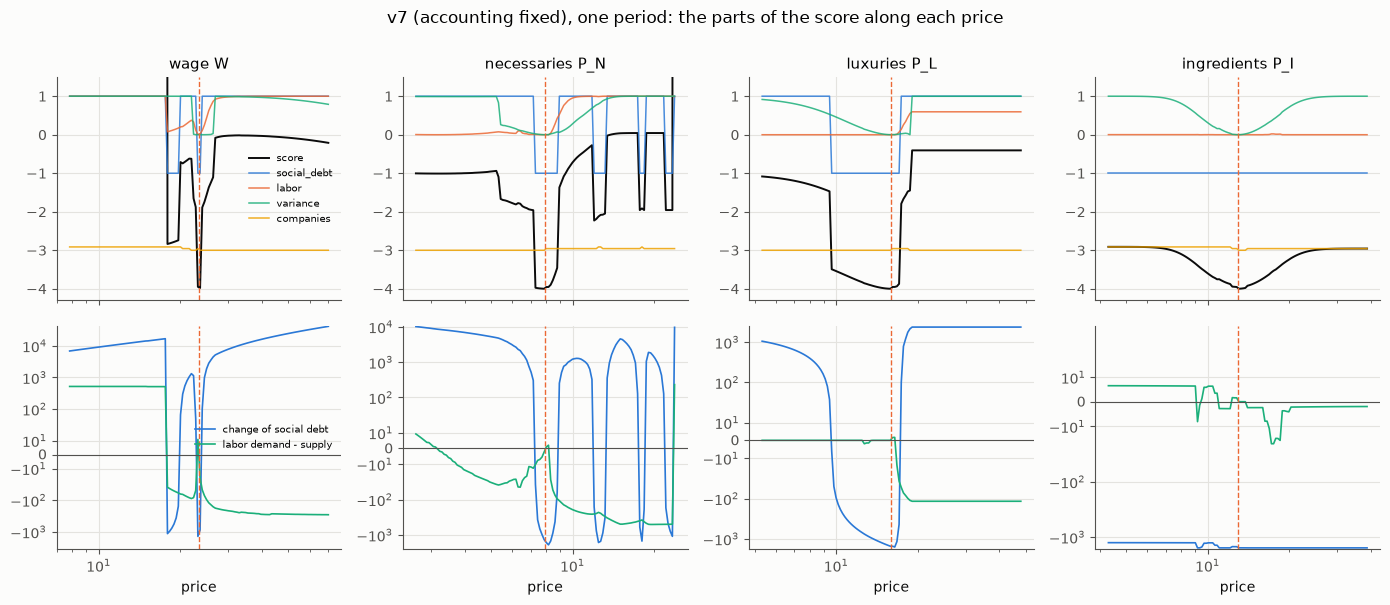

In [59]:
import matplotlib.ticker
SLV = pmap(anatomy.v7_slice, [(FIX7, 1, 4, j, 120) for j in range(4)])
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex='col')
for j, r in enumerate(SLV):
    R = r['rows']; v = [d['value'] for d in R]
    axes[0, j].plot(v, [d['score'] for d in R], color=INK, lw=1.4, label='score')
    for i, p in enumerate(('social_debt', 'labor', 'variance', 'companies')):
        axes[0, j].plot(v, [d[p] for d in R], color=PAL[i], lw=1.1, alpha=0.85, label=p)
    axes[0, j].axvline(r['x'][j], color=PAL[1], ls='--', lw=1)
    axes[0, j].set(xscale='log', title=names[j], ylim=(-4.3, 1.5))
    axes[1, j].plot(v, [d['dsd'] for d in R], color=PAL[0], lw=1.2, label='change of social debt')
    axes[1, j].plot(v, [d['gap'] for d in R], color=PAL[2], lw=1.2, label='labor demand - supply')
    axes[1, j].axhline(0, color=INK2, lw=0.8); axes[1, j].axvline(r['x'][j], color=PAL[1], ls='--', lw=1)
    axes[1, j].set(xscale='log', xlabel='price'); axes[1, j].set_yscale('symlog', linthresh=10, linscale=0.4)
    lo, hi = axes[1, j].get_ylim()
    axes[1, j].set_yticks([t for t in (-1e4, -1e3, -1e2, -10, 0, 10, 1e2, 1e3, 1e4, 1e5) if lo <= t <= hi])
    for rr in (0, 1):
        axes[rr, j].xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
axes[0, 0].legend(fontsize=7); axes[1, 0].legend(fontsize=7)
fig.suptitle('v7 (accounting fixed), one period: the parts of the score along each price', y=1.0)
plt.tight_layout(); plt.show()

上の段がスコアとその項、下の段が社会的負債の増分と労働の需給のずれである。

- **社会的負債の項(青)は、ほぼ −1 か +1 の二つの値しか取らない。** 係数が 1000 なので、社会的負債の増分が数単位を超えると、tanh はほぼ ±1 に張り付く。「社会的負債が減ったか、増えたか」の二択になり、増減が 0 のところに高さ 2 の**崖**がある。下の段の社会的負債の増分(青)が 0 をまたぐところで、上の段の青が跳ぶ。
- **労働の項(橙)は、ほとんど効いていない。** 係数が $5\times 10^{-5}$ なので、需給のずれが 10 なら 0.005、50 でも 0.12 にしかならない。下の段の需給のずれ(緑)がかなり動いても、上の段の橙はほぼ 0 のままである。
- **企業数の項(黄)は、階段状**に変わる。参入するかどうかで、企業数が変わるからである。

つまり、v7 で実際に効いている条件は、次の三つしかない。

1. 社会的負債が減ること(不等式。等式ではない)
2. 各分野の企業数が 5 社前後であること(離散的)
3. 三つの分野の最大利潤率がそろうこと(等式 2 本)

8.1 の言葉で言えば、等式は実質 2 本しかなく、未知数は 5 つ(価格 4 つと標準利益率)である。**v7 は崩壊点を消した代わりに、価格を決める条件を失っている。**

### 9.3 答えは「族」になり、前の期の価格で選ばれる

条件が足りないので、最小点は一つに決まらない。前の期の価格の近く(±5%)の 40 点から解き、最良に近い(最良 + 0.01 以内の)答えの集まりを調べる。答えの散らばりの主な方向の数は、主成分分析(特異値分解)で見積もる。

In [60]:
fam_jobs = [(FIX7, s, k, 40) for s in (1, 2, 3) for k in (4, 14)]
FAM = pmap(anatomy.near_family, fam_jobs)
print('seed 期   最良    最良+0.01以内   特異値(散らばりの大きさ)        実質賃金の範囲     贅沢品の生産の範囲   需給のずれの範囲')
for (p, s, k, n), r in zip(fam_jobs, FAM):
    g = r['good']
    rw = [d['realwage'] for d in g]; pl = [d['prodL'] for d in g]; gp = [d['gap'] for d in g]
    print(f"{s:3d} {k + 1:3d}  {r['best']:6.3f}     {len(g):2d}/{r['n']}      {np.round(r['sv'][:4], 3)!s:28s}  "
          f"[{min(rw):.2f}, {max(rw):.2f}]       [{min(pl):4.0f}, {max(pl):4.0f}]       [{min(gp):6.1f}, {max(gp):5.1f}]")

seed 期   最良    最良+0.01以内   特異値(散らばりの大きさ)        実質賃金の範囲     贅沢品の生産の範囲   需給のずれの範囲
  1   5  -4.000     35/40      [0.235 0.151 0.042 0.023]     [2.91, 3.19]       [ 170,  256]       [  -5.5,   1.7]
  1  15  -3.898      1/40      []                            [3.15, 3.15]       [ 229,  229]       [ -13.9, -13.9]
  2   5  -3.944     31/40      [0.211 0.176 0.056 0.043]     [3.12, 3.35]       [ 174,  239]       [  -7.6,   1.0]
  2  15  -3.954      1/40      []                            [3.48, 3.48]       [ 224,  224]       [   0.7,   0.7]
  3   5  -4.000     31/40      [0.271 0.198 0.119 0.049]     [2.77, 3.06]       [ 187,  277]       [  -9.0,   2.1]
  3  15  -1.997     17/40      [0.212 0.051 0.03  0.016]     [3.20, 3.51]       [ 131,  195]       [  -4.9,   4.1]


5 期目の状態では、40 点のうち 30 点以上が最良に近い答えに行き、その答えは主に**二つの方向**に散らばる(大きい特異値が二つあり、残りは小さい)。その中で、実質賃金は 1 割近く、贅沢品の生産は 4〜5 割も違い、労働の需給のずれも 10 近く動く。スコアから見ればほぼ同じ答えが、経済としてはかなり違う。15 期目の状態では、最良に近い答えが一つしか見つからないこともある(段差に囲まれた狭い谷に入ると、近くの出発点からはそこにたどりつけない)。

どの答えが選ばれるかは、出発点、つまり**前の期の価格**で決まる。第 4 章の初めに見た v7 の名目価格の漂い(1 期あたり 1% 強のデフレ)や、標準利益率 $s$ が目標の 0.06 から離れて 0.4〜0.5 に漂うことは、この決まらない方向に沿った「慣性」の動きとして説明できる。

#### 戦術を明示する

8.1 で、式が足りない分を、明示した戦術で埋めるという道を挙げた。6.5 で見たとおり、v1 でも v7 でも、経済を支えていたのは「前の期の価格から少しだけ動く」という、Nelder–Mead 法の局所性がもたらす暗黙の戦術だった。v7 が暗黙にしていることは、「前の期の価格から出発して、近くで止まる」、言い換えれば「**前の期の価格に近い答えを選ぶ**」という戦術である。それを、スコアにはっきり書き込むことができる。

$$
\text{スコア} + \lambda \sum_{j} \big(\log x_j - \log x_j'\big)^2 .
$$

$x'$ は前の期の価格、$\lambda$ はこの「慣性」の強さである。この項は、族の中から**前の期の価格に一番近い点**を一つ選ぶ。

まず、その原理が働くかを、式がちょうど一本足りない設定で確かめる。8.2 の均衡の残差から、原料の分野の利潤率の条件を外す(未知数 4、条件 3)。Nelder–Mead と Powell(別の局所的な最適化法)を、それぞれ 10 点から回す。

In [61]:
tjobs = [(lam, s, k) for lam in (0.0, 0.1, 1.0) for s in (1, 2) for k in (4, 14)]
TS = pmap(anatomy.tactic_select, tjobs)
print('慣性 λ   seed  期    最良のスコア   最良×1.05 以内の答え   その中の価格の広がり')
for r in TS:
    print(f"{r['lam']:5.1f}    {r['seed']:3d} {r['k'] + 1:3d}    {r['best']:10.2e}        {r['n_good']:2d} / 20                {r['spread']:6.1%}")

慣性 λ   seed  期    最良のスコア   最良×1.05 以内の答え   その中の価格の広がり
  0.0      1   5      3.03e-28         7 / 20                 24.8%
  0.0      1  15      2.76e-27        12 / 20                 43.1%
  0.0      2   5      2.16e-28        12 / 20                 39.2%
  0.0      2  15      1.79e-27        10 / 20                 68.3%
  0.1      1   5      4.92e-04         1 / 20                  0.0%
  0.1      1  15      2.96e-04         2 / 20                  0.0%
  0.1      2   5      1.79e-04         1 / 20                  0.0%
  0.1      2  15      2.68e-04         1 / 20                  0.0%
  1.0      1   5      4.87e-03         1 / 20                  0.0%
  1.0      1  15      1.86e-03         1 / 20                  0.0%
  1.0      2   5      1.79e-03         1 / 20                  0.0%
  1.0      2  15      2.67e-03         1 / 20                  0.0%


- **慣性がないとき**($\lambda = 0$): 残差がほぼ 0(計算機の精度の限界)の答えが、いくつも見つかる。その価格は 2〜7 割も違う。式が一本足りないので、答えは本当に族になっている。
- **慣性があるとき**: 最良の答えは**一つ**になる(最良に近い答えはそれ一つだけで、広がりは 0)。戦術を書き込むと、答えが決まる。

ただし、表の「最良 × 1.05 以内の答え」が 20 のうち 1 つか 2 つしかないことにも注意してほしい。残りは、最良の点に**たどりつけずに**止まっている。このモデルのスコアには、労働の供給の階段(2.4)、贅沢品を買う人数の階段(2.5)、分担に加わるかどうかの切り替え(2.6)と、不連続なところがたくさんある。局所的な最適化法は、そうした段差で止まってしまう。

では v7 そのものに慣性の項を足すとどうなるか。最適化法を Nelder–Mead から Powell に替えて、30 期の経路がどれだけ変わるかを比べる。

In [62]:
pjobs = [(dict(FIX7, inertia=lam), s, 30, m) for lam in (0.0, 1.0) for s in (1, 2, 3) for m in ('Nelder-Mead', 'Powell')]
t0 = time.time()
PP = pmap(anatomy.opt_path, pjobs)
print(f'({time.time() - t0:.0f} 秒)')
for i in range(0, len(pjobs), 2):
    A, B = PP[i], PP[i + 1]; n = min(len(A), len(B))
    lam, s = pjobs[i][0]['inertia'], pjobs[i][1]
    print(f'慣性 λ = {lam:3.1f}  seed {s}: Nelder-Mead と Powell の価格の違い(30 期で最大) {np.max(np.abs(A[:n] - B[:n]) / A[:n]):6.1%}   '
          f'30 期目の実質賃金 {A[-1, 0] / A[-1, 1]:.2f} 対 {B[-1, 0] / B[-1, 1]:.2f}')

(11 秒)
慣性 λ = 0.0  seed 1: Nelder-Mead と Powell の価格の違い(30 期で最大)  77.0%   30 期目の実質賃金 3.80 対 3.64
慣性 λ = 0.0  seed 2: Nelder-Mead と Powell の価格の違い(30 期で最大)  96.3%   30 期目の実質賃金 4.32 対 3.02
慣性 λ = 0.0  seed 3: Nelder-Mead と Powell の価格の違い(30 期で最大)  64.2%   30 期目の実質賃金 3.70 対 3.72
慣性 λ = 1.0  seed 1: Nelder-Mead と Powell の価格の違い(30 期で最大)  56.2%   30 期目の実質賃金 3.58 対 3.25
慣性 λ = 1.0  seed 2: Nelder-Mead と Powell の価格の違い(30 期で最大)  85.1%   30 期目の実質賃金 3.90 対 2.91
慣性 λ = 1.0  seed 3: Nelder-Mead と Powell の価格の違い(30 期で最大)  36.5%   30 期目の実質賃金 3.67 対 3.20


慣性の項を足しても、v7 の経路は、最適化法によって大きく変わったままである。v7 のスコアは、9.2 で見た崖(社会的負債の項)と段差(企業数・労働・贅沢品)だらけで、最適化法ごとに違う段差で止まるからだ。さらに、一期の小さな違いが参入の有無を変え、それが後の期に積み重なっていく。

まとめると、こうなる。

- **戦術を明示すれば、答えは原理的に一つに決まる。** 式が足りないこと自体は、戦術で補える。作者の直感(「戦術があるはずだ」)は、この意味で正しい。
- **しかし、戦術が働くには、スコアが(ほぼ)連続でなければならない。** 崖や段差があると、どの最適化法も、戦術が選ぶ点にたどりつけない。そのとき現れる「カオス」は、現実を映したものというより、モデルの段差と最適化法の癖を映したものである。
- だから、このモデルを立て直すには、まず段差をなくす(人数を連続量にする、参入を滑らかにする、社会的負債の項を符号ではなく大きさで効かせる)必要がある。これは続くノート(企業数の連続化)の課題である。

### 9.4 その5 の dual annealing の観察

作者は、その5 で dual annealing(大域的な探索)を試し、「社会的負債がマイナスに大きいところ」に行って、賃金や必需品の価格が奇妙になることを観察していた。9.1 の dual annealing の答えを見ると、その理由がわかる。

In [63]:
for (p, s, k), r in zip(states, V7C):
    d = r['da1000']
    print(f"{'直した' if p.get('fix_profit') else '元のまま'} seed {s} {k + 1:2d} 期目: DA[1,1000] の答え (W, P_N, P_L, P_I, s) = {np.round(d['x'], 2)}   "
          f"社会的負債の増分 {d['dsd']:10.0f}   スコア {d['score']:.3f}")

元のまま seed 1  5 期目: DA[1,1000] の答え (W, P_N, P_L, P_I, s) = [5.3552e+02 1.1300e+00 6.1580e+02 1.1420e+02 6.0000e-02]   社会的負債の増分        -70   スコア -2.767
元のまま seed 1 15 期目: DA[1,1000] の答え (W, P_N, P_L, P_I, s) = [2.3640e+01 1.0000e+00 3.8829e+02 1.1894e+02 6.0000e-02]   社会的負債の増分    -237673   スコア -2.888
元のまま seed 2  5 期目: DA[1,1000] の答え (W, P_N, P_L, P_I, s) = [2.0900e+01 3.9300e+00 3.5800e+02 9.3636e+02 6.0000e-02]   社会的負債の増分   -1398254   スコア -2.702
元のまま seed 2 15 期目: DA[1,1000] の答え (W, P_N, P_L, P_I, s) = [3.8890e+01 1.1800e+00 8.5285e+02 7.2690e+02 6.0000e-02]   社会的負債の増分   -1976966   スコア -2.076
直した seed 1  5 期目: DA[1,1000] の答え (W, P_N, P_L, P_I, s) = [239.97 238.76 423.85 451.24   0.52]   社会的負債の増分       -170   スコア -1.998
直した seed 1 15 期目: DA[1,1000] の答え (W, P_N, P_L, P_I, s) = [8.7130e+01 1.0000e+00 9.6574e+02 1.5200e+00 9.0000e-02]   社会的負債の増分      66037   スコア -1.526
直した seed 2  5 期目: DA[1,1000] の答え (W, P_N, P_L, P_I, s) = [2.0692e+02 2.0676e+02 2.7503e+02 3.7987e+02 6.0000e-02]   社会的負債の

dual annealing の答えは、どれも、賃金や贅沢品・原料の価格が数百から 1000 になる、極端な点である。

- 元の会計(誤りあり)では、そこで社会的負債が数万から百万単位で減っている。社会的負債の項は、減り方の**大きさ**を見ずに**符号**しか見ない(9.2)。だから、大域的な探索にとっては、「社会的負債が減る点」はどれも同じくらい良く見え、経済的に意味のない極端な点が選ばれる。しかも元の会計では、社会的負債の値そのものが実際と違っていた(第 7 章)。作者が見たのは、これである。
- 直した会計では、dual annealing は良い点そのものを見つけられず(スコアは −2 前後)、やはり極端な価格の点で止まる。崖と段差だらけのスコアでは、大域的な探索も役に立たない。

### 9.5 機械の高度化と実質賃金

作者がこのモデルを作り始めたときの関心は、「賃金が上がると機械化が進み、機械化が進むと労働の需要が減る」という、機械の高度化をめぐる問題だった。v7 は、その問いに小さな答えを出している。

新しい企業は、前の企業より一製品あたり労働量 $\gamma$ が小さく(0.95〜0.99 倍。労働を節約する機械)、一製品あたり原料 $\alpha$ が変わる(0.98〜1.18 倍)。この二つの変化を、それぞれ止めた場合と比べる(`me_ref` の `gamma_progress`、`alpha_change`)。

(29 秒)
γ の低下  α の変化   実質賃金 1→40 期   労働生産性 1→40 期   雇用 1→40 期   労働者全体の実質所得(雇用 × 実質賃金)
  あり      あり       2.86 → 4.31         3.70 → 8.84         654 →  426       1870 →   1839
  あり      なし       3.04 → 4.23         3.98 → 7.91         642 →  460       1953 →   1943
  なし      あり       2.80 → 3.26         3.60 → 4.54         656 →  602       1838 →   1960
  なし      なし       2.96 → 2.95         3.85 → 3.61         648 →  689       1914 →   2030


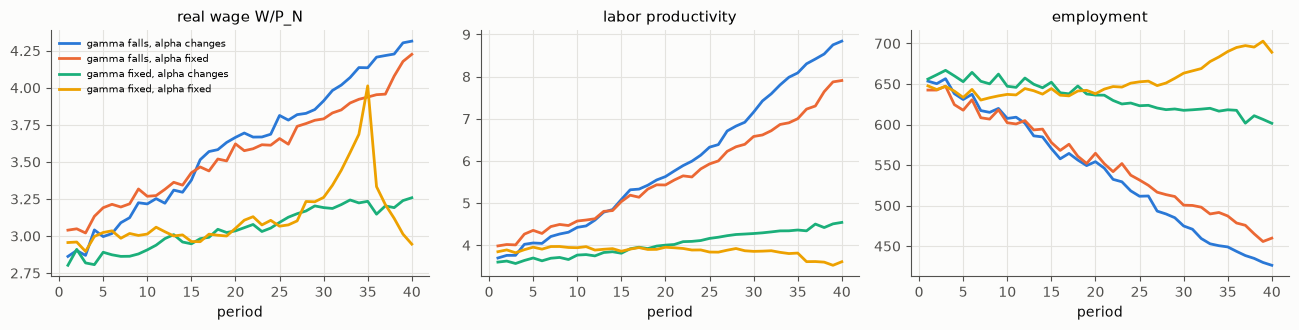

In [64]:
combos = [(True, True), (True, False), (False, True), (False, False)]
n_t = 3 if FAST else 6
t0 = time.time()
TP = pmap(anatomy.tech_path, [(dict(FIX7, gamma_progress=g, alpha_change=al), s, 40) for g, al in combos for s in range(1, n_t + 1)])
print(f'({time.time() - t0:.0f} 秒)')
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
print('γ の低下  α の変化   実質賃金 1→40 期   労働生産性 1→40 期   雇用 1→40 期   労働者全体の実質所得(雇用 × 実質賃金)')
for i, (g, al) in enumerate(combos):
    R = [r for r in TP[i * n_t:(i + 1) * n_t] if len(r) >= 40]
    A = np.mean(R, 0)
    lab = f"gamma {'falls' if g else 'fixed'}, alpha {'changes' if al else 'fixed'}"
    for j in range(3):
        ax[j].plot(range(1, 41), A[:, j], color=PAL[i], label=lab)
    print(f"  {'あり' if g else 'なし'}      {'あり' if al else 'なし'}       {A[0, 0]:.2f} → {A[-1, 0]:.2f}         {A[0, 1]:.2f} → {A[-1, 1]:.2f}        "
          f"{A[0, 2]:4.0f} → {A[-1, 2]:4.0f}     {A[0, 0] * A[0, 2]:6.0f} → {A[-1, 0] * A[-1, 2]:6.0f}")
for j, t in enumerate(('real wage W/P_N', 'labor productivity', 'employment')):
    ax[j].set(title=t, xlabel='period')
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

- $\gamma$ の低下も $\alpha$ の変化もなければ、実質賃金は、1 期目と 40 期目でほぼ同じである(途中で一時的に跳ねるのは、6 つの seed の平均の中で、一つの seed の価格が大きく動いたためである。9.3 の「決まらない方向」の現れでもある)。
- $\gamma$ が下がると(労働を節約する機械が入ると)、労働生産性が上がり、実質賃金が上がる。
- $\alpha$ の変化だけでも、実質賃金は少し上がる。必需品の分野では、参入の選別で $\alpha$ の小さい企業が残り、必需品が安くなるからである。
- 技術が進むと、**雇用は減る**。機械が、働く人を余らせる(古典派やマルクスの言う「相対的過剰人口」)。
- 雇われている人の実質賃金は上がるが、労働者全体の実質所得(雇用 × 実質賃金)は、ほぼ横ばいである。余った人の生活は、社会的負債(政府部門)が支えている。

これは、作者の最初の問いへの、小さいながらも筋の通った答えである。ただし、v7 の価格には 9.3 で見た「決まらない方向」があるので、数値の細部は、最適化法や経路に左右されうることを付け加えておく。

### 9.6 v1・v2・v7 と均衡の残差のまとめ

| | スコアの最小の場所 | 一期の答えの決まり方 | 現れる「カオス」の正体 |
|---|---|---|---|
| v1 | 崩壊点(常に) | 局所的な最適化が、近くの谷にとどまることに頼る | 崩壊点に向かう坂と、段差 |
| v2 | 崩壊点(しばしば)と、たくさんの極小 | 出発点(前の期の価格)で決まる | 多数の極小のあいだの乗り換え |
| v5 | 崩壊点ではない(利益率と労働の重み) | 損失を嫌う変換の形で変わる | 赤字の分野への偏り(log は売上をそろえる) |
| v7 | 経済的にまともな領域(下限 −4 にほぼ達する) | 約 2 次元の族から、出発点に近い点 | 決まらない方向に沿った慣性と、崖・段差 |
| 均衡の残差 | 残差 0 の点(実質的に一つ) | 4 本の条件で決まる | (ほぼ現れない。企業数の飽和は残る) |

## 第 10 章 まとめと、続くノートへ

### 10.1 三つの問いへの答え

**問い 1: なぜ、あのモデルは不安定だったのか。**

- 一番の理由は、**スコアの本当の最小点が経済の崩壊点だった**ことである(第 6 章)。v1 のスコア「労働の需給のずれ² − 利益の総和」は、全企業がまとまって価格を決めるカルテルの問題で、その最善は「必需品を最高値にし、賃金を最低にして、誰も雇わない」点だった。必需品の需要に下限があり、労働の罰に上限があるからである。
- v1 が経済らしく動いたのは、毎期、前の期の価格から局所的に探したからにすぎない。一期ずつの局所的な最適化は、最適化ではなく、**価格の調整過程**として働いていた。上手に最適化すれば必ず壊れるスコアを、最適化の「下手さ」(局所性)が支えていた。
- それに、スコアの段差(労働の人数、贅沢品を買う人数、参入、分担への参加)と、平らな方向(贅沢品の需要が 0 のときの贅沢品の価格など)が加わって、結果は出発点と経路に強く左右された(第 5 章)。
- 会計には三つの誤りがあった(第 7 章)が、それはカオスの原因ではなかった。

**問い 2: 作者の工夫は、経済学の何に当たるのか。**

| 作者の工夫 | 経済学の言葉では | 評価 |
|---|---|---|
| 分野間の「バランス」(利潤率の分散を罰する) | 利潤率の均等化(古典派・マルクスの生産価格) | 正しい方向。分散ではなく、水準 $\bar r$ との差にすれば完全になる(8.2) |
| 標準利益率を変数にする(v7) | 一般的利潤率 | 経済の中では決まらない量(分配の自由度)。外から与えるべき(8.3) |
| 「全体最適 + 力関係」 | Negishi の重みつき厚生の最大化 | 力関係を予算の釣り合いで決めれば、競争均衡と一致する(8.4) |
| log 戦略 | ナッシュ積、アイゼンバーグ=ゲール | 企業の利益率にかけると売上をそろえてしまう。予算で重みをつけた消費者の効用にかければ、市場の均衡になる(8.5) |
| tanh で項をそろえる | 多目的最適化のスカラー化 | 崩壊点は消えたが、項が飽和して、価格を決める条件が減った(第 9 章) |
| 社会的負債 | 政府部門(SFC の相手勘定) | 会計としては正しい(誤りを直せば閉じる)。制約と行動が欠けていた(7.4) |
| 原料の上限 0.9 | ホーキンス=サイモン条件 | 正しい判断(7.6) |
| 命令的前提・環境的前提 | 目的関数と制約・モデルの区別 | 正しい区別。命令的前提は「この値に合わせよ」という条件にすべき(8.4) |

**問い 3: 「価格を最適化で決める」という発想を、正しく使うにはどうすればよいのか。**

この発想は、筋が悪いのではない。次のことを守れば、正しく働く。

1. **会計を閉じ、毎期検算する。** 全部門の黒字と赤字の合計が 0 になることを、プログラムの中で確かめる(第 7 章)。
2. **条件を数え、未知数の数とそろえる。** スコアは「残差」(0 になるのが均衡)にする(8.1、8.2)。
3. **「いくらでも大きく」という要求を、スコアに入れない。** 要求は、モデルの穴を通って、ありえない点にスコアを連れていく(第 6 章、8.4)。
4. **力関係(重み)は、予算の釣り合いで決める。** 予算のずれは移転であり、それを誰が払うのかを、モデルに書く(8.4)。
5. **足りない式は、明示した戦術で埋める。** ただし、戦術が働くように、スコアの段差をなくす(9.3)。
6. **答えが最適化法によらないことを確かめる。** 出発点を変える、局所的な方法と大域的な方法の両方で解く。答えが変わるなら、スコアのどこかに問題がある(第 6 章、第 9 章)。

作者は当初、「戦術がないならないなりに、ある種のカオスが現れるなら、それも現実を映している」と考えていた。この解剖の結論は、カオスには二種類ある、ということである。現実の経済にも、理論だけでは決まらないことがあり、それが歴史や慣習で決まるという意味での不確かさは、現実を映している。しかし、このモデルで現れたカオスの多くは、スコアの作り方(崩壊点、段差、飽和)と、最適化法の癖を映したものだった。二つを区別するのが、上の 6 か条である。

### 10.2 残る問い

この解剖で、手をつけずに残したことがある。

- **企業数の飽和**: 均衡の残差の設定では、企業数が各分野 10 社前後に飽和する(8.2)。参入と退出の規則を、均衡の条件(利潤率の均等化)と整合させる必要がある。企業数を整数ではなく連続量(生産能力)として扱えば、段差も同時になくせる。
- **段差をなくす**: 労働の人数、贅沢品を買う人数、分担への参加を、滑らかな形(連続量、ロジット型の配分など)にする(9.3)。
- **名目の錨と金利**: 名目の価格の水準は、このモデルの中では決まらない(1.3)。利潤率の水準 $\bar r$ も外から与える必要がある(8.3)。どちらも、貨幣と信用のモデルから与えるのが自然である。
- **輸出入**: 地域が二つ以上ある経済。地域間の価格の均衡が一つの最適化問題として解けることは、Samuelson(1952)が示している。
- **危機時の生産**: どの企業も赤字で作りたがらないとき、どうするか。元のモデルは「全社で赤字を分担する」としていた。在庫(売れ残りと品切れを許す)、政府が赤字を埋めて作らせる「最後の生産者」、損失の分担を比べたい。
- **政府部門の行動**: 社会的負債を、税と移転と借入の制約を持つ、本物の政府部門にする。

### 10.3 続くノート

このノートは、シリーズの一冊目である(シリーズの一覧は第 0 章)。ここで残した問いは、続くノートで次のように扱った。

1. **資産市場とその前史**: 2011 年の「外作用的簡易経済シミュレーション」(Perl)は**ノート O** で、2019 年の「資産市場の簡易シミュレーション」(土地と知的財産の市場)は**ノート 2** で解剖した。お金を「マイナスの負債」として書いて総量を保存する 2011 年のモデルは、このノートの v1〜v7 より会計の筋が良かった。一方で、資産が買値のまま積み上がって発散した(ノート O 第 2 章)。ノート 2 では、土地(減価しない資産)と知的財産(減価する資産)を、信用循環モデルの「株式的な富」を二つに分ける形で読み、土地を担保とした信用の増幅(Kiyotaki と Moore 1997 の型)を調べた(ノート 2 第 5・7 章)。
2. **シミュレーション仏教の経済**: 価格も市場もなく、家族ごとの資産配分(債券・株式・大バクチ・死蔵・農地)と、裾の重い収益、生活保護、一家離散からなる経済を、**ノート 3** で読んだ。
3. **総合的な立て直し**: 10.2 の課題(企業数の連続化、段差のない需要と供給、在庫と危機時の生産、輸出入、政府部門)を、**ノート 4** の模型 im で一つにした(企業数の連続化と均衡の残差は第 1・3 章、輸出入は第 5 章、危機時の生産は第 7 章)。ブラウザで動かして試せる版(The JRF Economy Model 2026)も作った。

ほかに、ネットの小さな通貨の制度の設計(**ノート P**)、贅沢品を探索とみる作者の議論(**ノート I**)、作者が AI と作った小さな模型(**ノート M**)を読んだ。

---

## 付録 A: 再現のために

### A.1 このノートが書き出すファイル

このノートは、実行すると、作業ディレクトリに次のファイルを書き出す。どれも `%%writefile` のセルの中身そのものである。

| ファイル | 中身 | 章 |
|---|---|---|
| `orig_tools.py` | 元のコードの取得(sha256 の確認)と、そのままの実行 | 3.1 |
| `me_ref.py` | 元のモデルの書き直し(v1・v2・v5・v7、オプション) | 3.2 |
| `equiv.py` | 元のコードとの一致試験 | 3.3 |
| `anatomy.py` | 第 4〜9 章の解析(並列計算用の関数) | 4〜9 |
| `toy_negishi.py` | Negishi の模型 | 8.4 |
| `toy_log.py` | log 戦略の模型と、フィッシャー市場 | 8.5 |
| `orig_cache/` | GitHub から取ってきた元のコード | 3.1 |

### A.2 `me_ref.Params` のおもなオプション

既定値は、どれも元のコードと同じ振る舞いになるように決めてある。

| オプション | 既定 | 意味 | 章 |
|---|---|---|---|
| `version` | `'v1'` | 規則とスコアの版(`'v1'`, `'v2'`, `'v5'`, `'v7'`) | 2 |
| `poi` | `'closed'` | 原料の不動点の解き方(`'brent'` で元と同じ) | 2.7、3.2 |
| `fix_profit`, `fix_overtime` | `False` | 会計の三つの誤りを直す | 7 |
| `score_transform` | `'none'` | v5・v7 の変換(`'log1.1'`, `'exp'`, `'hybrid'` など) | 8.5 |
| `score_kind` | `'orig'` | `'eq'` で均衡の残差のスコア | 8.2 |
| `eq_target_rate`, `standard_profit_rate` | 0.06 | 目標の利潤率 $\bar r$ と、参入の基準 | 8.3 |
| `eq_sectors` | `('N','L','I')` | 利潤率をそろえる分野(減らすと式が足りない設定) | 9.3 |
| `inertia` | 0 | 明示した戦術(前の期の価格に近い点を選ぶ)の強さ $\lambda$ | 9.3 |
| `smooth_labor` | `False` | 労働の供給の切り上げ・切り捨てをやめる | 9.3 |
| `gamma_progress`, `alpha_change` | `True` | 新企業の $\gamma$ の低下・$\alpha$ の変化を止める | 9.5 |

### A.3 Lean の準備

次のセル(「Lean の準備」)が、Lean を用意する。このノートと同じディレクトリの `.leandir` に、Lean 4(v4.34.1)と Mathlib の入った lake のプロジェクトの場所(lakefile のあるディレクトリ)が書いてあれば、それを使う。なければ、elan(Lean の版の管理)を入れ、そのプロジェクト `jrf_lean/` を作って、`.leandir` に書く。Google Colab でも、そのまま通る。初めてのときは Mathlib の組み上がったものを取ってくるので 10 分ほどかかり、10GB ほどの場所を使う。同じディレクトリでほかのノートを動かすときは、それを使い回す。

手元の Lean を使うなら、たとえば次のようにして、`.leandir` を先に書いておく。

```bash
lake new leanproj math        # Mathlib を使うプロジェクトを作る
cd leanproj && lake exe cache get
pwd > /path/to/notebook/.leandir
```

In [65]:
# Lean の準備: .leandir に書いた lake のプロジェクト(Mathlib 入り)があれば、それを使う。
# なければ elan(Lean の版の管理)を入れ、Lean 4 v4.34.1 と Mathlib の入ったプロジェクト jrf_lean/ を作る(Google Colab でもそのまま通る)。
# 初めてのときは Mathlib の組み上がったものを取ってくるので、10 分ほどかかり、10GB ほどの場所を使う。同じディレクトリのほかのノートは、それを使い回す。
import os, shutil, subprocess

def lean_project_ok(d):
    return bool(d) and os.path.exists(os.path.join(d, 'lakefile.lean')) and os.path.isdir(os.path.join(d, '.lake', 'packages', 'mathlib'))

LEANDIR = open('.leandir').read().strip() if os.path.exists('.leandir') else None
if lean_project_ok(LEANDIR):
    print('Lean のプロジェクト: .leandir に書いた場所にあるものを使う')
else:
    elan_bin = os.path.expanduser('~/.elan/bin')
    os.environ['PATH'] = elan_bin + ':' + os.environ.get('PATH', '')
    if not shutil.which('lake'):
        subprocess.run('curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh'
                       ' | sh -s -- -y --default-toolchain none', shell=True, check=True)
    LEANDIR = os.path.abspath('jrf_lean')
    os.makedirs(LEANDIR, exist_ok=True)
    with open(os.path.join(LEANDIR, 'lean-toolchain'), 'w') as f:
        f.write('leanprover/lean4:v4.34.1\n')
    with open(os.path.join(LEANDIR, 'lakefile.lean'), 'w') as f:
        f.write('import Lake\nopen Lake DSL\n\npackage jrf_lean\n\n'
                'require mathlib from git\n  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"\n')
    lake = shutil.which('lake') or os.path.join(elan_bin, 'lake')
    for args in (['update'], ['exe', 'cache', 'get']):
        r = subprocess.run([lake] + args, cwd=LEANDIR, capture_output=True, text=True)
        print(f'lake {" ".join(args)}: 終了コード {r.returncode}')
        if r.returncode != 0:
            print(r.stdout[-2000:], r.stderr[-2000:])
            raise RuntimeError('Lean のプロジェクトを作れなかった')
    with open('.leandir', 'w') as f:
        f.write(LEANDIR + '\n')
    print('Lean のプロジェクト: jrf_lean/ に作り、.leandir に書いた')

Lean のプロジェクト: .leandir に書いた場所にあるものを使う


### A.4 Lean による一括の確かめ

章ごとに書き足してきた `micro_economy.lean` の最後に、名前空間を閉じる行を足し、前の節で用意した Lean に一括して確かめさせる。

In [66]:
%%writefile -a micro_economy.lean
end MicroEconomy

Appending to micro_economy.lean


In [67]:
import os, shutil, subprocess
LEANDIR = open('.leandir').read().strip() if os.path.exists('.leandir') else None
if LEANDIR:
    lake = shutil.which('lake') or os.path.expanduser('~/.elan/bin/lake')
    env = dict(os.environ, PATH=os.path.dirname(lake) + ':' + os.environ.get('PATH', ''))
    path = os.path.abspath('micro_economy.lean')
    r = subprocess.run([lake, 'env', 'lean', path], cwd=LEANDIR, capture_output=True, text=True, env=env)
    print(r.stdout[-3000:], r.stderr[-3000:])
    n_thm = sum(1 for line in open(path) if line.startswith('theorem '))
    print(f'=== micro_economy.lean: {n_thm} 個の定理を確かめた。終了コード {r.returncode}(0 なら、すべての証明が通った) ===')
    assert r.returncode == 0
else:
    print('Lean のプロジェクトがない(.leandir がない)ので飛ばす。前のセル(Lean の準備)を走らせる')

 
=== micro_economy.lean: 6 個の定理を確かめた。終了コード 0(0 なら、すべての証明が通った) ===


### A.5 実行環境

In [68]:
import sys, platform
print('Python', sys.version.split()[0], '/', platform.platform())
print('numpy', np.__version__, '/ scipy', scipy.__version__, '/ matplotlib', matplotlib.__version__)
print('元のコード: JRF-2018/micro_economy commit', orig_tools.COMMIT)
print('FAST =', FAST, '/ N_SEEDS =', N_SEEDS, '/ 並列', N_JOBS)

Python 3.14.4 / Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
numpy 2.5.4 / scipy 1.18.1 / matplotlib 3.11.2
元のコード: JRF-2018/micro_economy commit 54e48f649721bd1619b0d05296706ce0414dc190
FAST = False / N_SEEDS = 16 / 並列 8


元のコードの最初の版は、Python 3.6.4、SciPy 1.0.0 で書かれた(その1 の記事による)。このノートを作った環境(上)でも、2020 年の版まで、そのまま動く。書き直しとの一致(第 3 章)は、同じ環境の中で確かめたものである。SciPy の版が大きく違うと、Nelder–Mead 法の細部の違いから、元のコードの経路そのものが変わることはありうる。

## 付録 B: 用語集

| 用語 | 意味 |
|---|---|
| 均衡 | 需要と供給が合っている状態。複数の市場では、全部の市場で合っている状態 |
| 模索過程(タトヌマン) | 品切れなら価格を上げ、売れ残りなら下げる、という価格の調整の過程 |
| ワルラス法則 | 全員が予算どおりにお金を使うなら、全市場の「(需要 − 供給) × 価格」の和が 0 になること |
| ニュメレール(価値尺度財) | 価格を 1 に決めて、ほかの価格の物差しにする財 |
| 利潤率 | (売上 − 費用) / 費用 |
| 一般的利潤率・生産価格 | 資本の移動で全分野の利潤率がそろったときの利潤率と、そのときの価格(古典派・マルクス・スラッファ) |
| 賃金−利潤のトレードオフ | 利潤率が上がると実質賃金が下がる関係 |
| 部門収支 | 部門ごとの黒字・赤字。全部門の和は 0 |
| SFC(ストック・フロー一貫)モデル | すべてのお金の流れと残高に、払う側と受け取る側を書くモデル |
| 投入係数行列・レオンチェフ逆行列 | 一単位作るのに要る中間財の量の表と、最終需要から総生産を求める行列 $(I - A)^{-1}$ |
| ホーキンス=サイモン条件 | レオンチェフ逆行列が正になる条件。経済が自分の生産に要る以上のものを作れること |
| Negishi の重み | 競争均衡を、重みつきの効用の和の最大化として表すときの重み。予算の釣り合いで決まる |
| アイゼンバーグ=ゲールの凸計画 | 予算で重みをつけた効用の log の和の最大化。答えがフィッシャー市場の均衡になる |
| ナッシュ積 | 各人の利得の積。その最大化がナッシュ交渉解 |
| 多目的最適化・スカラー化 | 複数の目的を、重みつきの和などで一つのスコアにすること |
| 局所的な最適化・大域的な最適化 | 出発点の近くの谷を探す方法(Nelder–Mead 法、Powell 法)と、全体を広く探す方法(差分進化、dual annealing) |
| 均衡の残差 | 均衡の条件のずれの二乗和。0 になる点が均衡 |
| 均衡選択・経路依存・フォーカル・ポイント | 均衡がたくさんあるとき、どれが選ばれるかを決めるもの(歴史、慣習、目印) |
| 価格の粘着性 | 価格が、前の値の近くにとどまりやすいこと |
| 相対的過剰人口 | 機械化などで、働く場を失った人々 |

---

## 付録 C: 過去の議論

この文書の材料になった作者の記事と、その前後の関連する記事を、古い順に挙げる(URL は参考文献に)。

- **2006 年 3 月**: 「名目賃金と実質賃金 − 失われた10年は残業に課税すべきだった」。残業(能力を超えた生産)の割増を、賃金と価格の関係で考えた(7.3 の残業の扱い)。
- **2011 年 1 月**: 「外作用的簡易経済シミュレーションのアイデアと Perl による実装」。お金をマイナスの負債として書く、市場のルール(外作用)と戦術(内作用)を分ける。このモデルの前史(ノート O)。
- **2018 年 3 月**: 「ミクロ経済学の我流シミュレーション」その1 基礎経済モデル。価格を最適化で決める(第 2 章)。
- **2018 年 9 月**: その2 バランス戦略(4.1、8.4)。
- **2019 年 5 月**: その3 log 戦略(8.5)、その4 最適化の失敗(第 6 章)。同じ月に「資産市場の簡易シミュレーション」(ノート 2)。
- **2020 年 2 月**: その5 大改良(v7。第 9 章)。
- **2022 年 3 月**: 『「シミュレーション仏教」の試み』。最適化による経済シミュレーションについての考え方(8.4)。その本の経済の部分はノート 3。
- **2026 年 1 月**: 「必需品と贅沢品のマクロ経済シミュレーション」(gj_6、Gemini と。ノート M)。
- **2026 年 10 月**: 信用循環モデルのノート「信用創造はどこで止まるのか」「信用の世界経済は一つか」(credit_simulation_v6)。利潤率の水準が金利で外から決まる、というこのノートの 8.3 節の読みと、そこでつながる。

---

## 参考文献

### 元のモデルと、関連する作者の記事・著作

- JRF「ミクロ経済学の我流シミュレーション」その1〜その5、ブログ『JRF の私見:税・経済・法』。
  - その1 基礎経済モデル(2018 年 3 月): http://jrf.cocolog-nifty.com/society/2018/03/post.html
  - その2 バランス戦略(2018 年 9 月): http://jrf.cocolog-nifty.com/society/2018/09/post.html
  - その3 log 戦略(2019 年 5 月): http://jrf.cocolog-nifty.com/society/2019/05/post-79cdc2.html
  - その4 最適化の失敗(2019 年 5 月): http://jrf.cocolog-nifty.com/society/2019/05/post-6f63b5.html
  - その5 大改良(2020 年 2 月): http://jrf.cocolog-nifty.com/society/2020/02/post-3f22aa.html
- JRF, micro_economy(Python のコード、public domain): https://github.com/JRF-2018/micro_economy (このノートは commit `54e48f6` を使う)
- JRF「外作用的簡易経済シミュレーションのアイデアと Perl による実装」(2011 年 1 月): http://jrf.cocolog-nifty.com/society/2011/01/post.html
- JRF「資産市場の簡易シミュレーション」(2019 年 5 月): http://jrf.cocolog-nifty.com/society/2019/05/post-9da6e7.html
- JRF・Gemini「必需品と贅沢品のマクロ経済シミュレーション」(2026 年 1 月): https://github.com/JRF-2018/misc_ipynb/blob/master/economic_simulation_gj_6.ipynb
- JRF「名目賃金と実質賃金 − 失われた10年は残業に課税すべきだった」(2006 年 3 月): http://jrf.cocolog-nifty.com/society/2006/03/post_4.html
- JRF『「シミュレーション仏教」の試み』(JRF 電版、2022 年 3 月)。最適化による経済シミュレーションについての考え方(8.4)。
- 信用循環モデルのノート: JRF「信用創造はどこで止まるのか」「信用の世界経済は一つか」、https://github.com/JRF-2018/credit_simulation_v6

### 経済学

- 富塚良三『経済原論』有斐閣大学双書、1976 年。
- 平井規之・北川和彦・滝田和夫『経済原論』有斐閣Sシリーズ、1987 年。
- Walras, L., *Éléments d'économie politique pure*, 1874(久武雅夫訳『純粋経済学要論』岩波書店、1983 年)。
- Marx, K., *Das Kapital*, Band III, 1894(第 2 篇、利潤の平均利潤への転化)。
- Pasinetti, L. L. (1981), *Structural Change and Economic Growth: A Theoretical Essay on the Dynamics of the Wealth of Nations*, Cambridge University Press.
- Baumol, W. J. (1967), "Macroeconomics of Unbalanced Growth: The Anatomy of Urban Crisis", *American Economic Review* 57(3), 415–426.
- Kongsamut, P., Rebelo, S., and Xie, D. (2001), "Beyond Balanced Growth", *Review of Economic Studies* 68(4), 869–882.
- Sraffa, P. (1926), "The Laws of Returns under Competitive Conditions", *Economic Journal* 36(144), 535–550.
- Sraffa, P. (1960), *Production of Commodities by Means of Commodities*, Cambridge University Press(菱山泉・山下博訳『商品による商品の生産』有斐閣、1962 年)。
- Leontief, W. (1936), "Quantitative Input and Output Relations in the Economic Systems of the United States", *Review of Economics and Statistics* 18(3), 105–125.
- Hawkins, D. and Simon, H. A. (1949), "Note: Some Conditions of Macroeconomic Stability", *Econometrica* 17(3/4), 245–248.
- Arrow, K. J. and Debreu, G. (1954), "Existence of an Equilibrium for a Competitive Economy", *Econometrica* 22(3), 265–290.
- Negishi, T. (1960), "Welfare Economics and Existence of an Equilibrium for a Competitive Economy", *Metroeconomica* 12(2–3), 92–97.
- Scarf, H. (1960), "Some Examples of Global Instability of the Competitive Equilibrium", *International Economic Review* 1(3), 157–172.
- Sonnenschein, H. (1972), "Market Excess Demand Functions", *Econometrica* 40(3), 549–563.
- Mantel, R. R. (1974), "On the Characterization of Aggregate Excess Demand", *Journal of Economic Theory* 7(3), 348–353.
- Debreu, G. (1974), "Excess Demand Functions", *Journal of Mathematical Economics* 1(1), 15–21.
- Nash, J. F. (1950), "The Bargaining Problem", *Econometrica* 18(2), 155–162.
- Eisenberg, E. and Gale, D. (1959), "Consensus of Subjective Probabilities: The Pari-Mutuel Method", *Annals of Mathematical Statistics* 30(1), 165–168.
- Samuelson, P. A. (1952), "Spatial Price Equilibrium and Linear Programming", *American Economic Review* 42(3), 283–303.
- Schelling, T. C. (1960), *The Strategy of Conflict*, Harvard University Press(フォーカル・ポイント)。
- Arthur, W. B. (1989), "Competing Technologies, Increasing Returns, and Lock-In by Historical Events", *Economic Journal* 99(394), 116–131(経路依存)。
- Kiyotaki, N. and Moore, J. (1997), "Credit Cycles", *Journal of Political Economy* 105(2), 211–248.
- Godley, W. and Lavoie, M. (2007), *Monetary Economics: An Integrated Approach to Credit, Money, Income, Production and Wealth*, Palgrave Macmillan.

### 最適化

- Nelder, J. A. and Mead, R. (1965), "A Simplex Method for Function Minimization", *The Computer Journal* 7(4), 308–313.
- Powell, M. J. D. (1964), "An Efficient Method for Finding the Minimum of a Function of Several Variables without Calculating Derivatives", *The Computer Journal* 7(2), 155–162.
- Storn, R. and Price, K. (1997), "Differential Evolution – A Simple and Efficient Heuristic for Global Optimization over Continuous Spaces", *Journal of Global Optimization* 11, 341–359.
- Xiang, Y., Sun, D. Y., Fan, W., and Gong, X. G. (1997), "Generalized Simulated Annealing Algorithm and Its Application to the Thomson Model", *Physics Letters A* 233(3), 216–220(SciPy の dual annealing の元)。
- Ferris, M. C. and Pang, J.-S. (1997), "Engineering and Economic Applications of Complementarity Problems", *SIAM Review* 39(4), 669–713(均衡を相補性問題として解く)。